In [1]:
import requests
from pathlib import Path
from scipy.io import loadmat, savemat
from scipy.signal import resample_poly
import urllib3

base_url = "https://engineering.case.edu/sites/default/files/"
target_fs = 12_000

files = {
    "train/normal_1hp.mat": ("98.mat", 48_000),
    "train/IR007_1.mat": ("106.mat", 12_000),
    "train/IR014_1.mat": ("170.mat", 12_000),
    "train/OR007@6_1.mat": ("131.mat", 12_000),
    "train/OR014@6_1.mat": ("198.mat", 12_000),
    "train/B007_1.mat": ("119.mat", 12_000),
    "train/B014_1.mat": ("186.mat", 12_000),
    "test_unseen/IR021_1.mat": ("210.mat", 12_000),
    "test_unseen/B021_1.mat": ("223.mat", 12_000),
}

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

for output, (source, source_fs) in files.items():
    path = Path("bearing_dataset") / output
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        print(f"{output} already exists, skipping download")
        continue
    print(f"Downloading {output}...")

    response = requests.get(base_url + source, timeout=120, verify=False)
    response.raise_for_status()
    path.write_bytes(response.content)

    if source_fs != target_fs:
        mat_data = loadmat(path)
        resampled_data = {}
        for key, value in mat_data.items():
            if key.startswith("__"):
                continue
            if key.endswith("_time"):
                value = resample_poly(value.squeeze(), target_fs, source_fs)
            resampled_data[key] = value
        savemat(path, resampled_data)
        print(f"Downloaded and resampled from {source_fs / 1000:g} kHz to {target_fs / 1000:g} kHz")
    else:
        print(f"Downloaded at {target_fs / 1000:g} kHz")

print(f"\nDownload complete. All signals are standardized to {target_fs / 1000:g} kHz.")

Downloaded and resampled from 48 kHz to 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz

Download complete. All signals are standardized to 12 kHz.


# Bearing Fault Detection with Uncertainty-Aware 1D-CNN (CWRU dataset)

This notebook completes **Phase A** (dataset understanding and preprocessing) and **Phase B** (baseline neural fault detector and uncertainty scoring).

Known classes used for training: `Normal`, `IR007`, `IR014`, `OR007`, `OR014`, `B007`, `B014` (all at 1 hp load, drive-end, 12 kHz).
Unseen classes kept completely apart: `IR021`, `B021`.

All figures are saved to `figures/` and all artifacts (processed data, model, thresholds) to `artifacts/` so they can be reused in the report and in Phase C.

In [2]:
# ---- Imports and global configuration ----
import json, os, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis, skew

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, accuracy_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = Path("bearing_dataset")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
ART_DIR = Path("artifacts"); ART_DIR.mkdir(exist_ok=True)

FS = 12_000            # all signals were standardized to 12 kHz by the download cell
WINDOW_SIZE = 1024     # points per sample (~85 ms at 12 kHz)
STRIDE = 512           # 50% overlap between consecutive windows
TRAIN_FRAC = 0.80      # 80% train / 20% test

# file -> (class label, original CWRU file number, which set it belongs to)
FILE_INFO = {
    "train/normal_1hp.mat":    ("Normal", 98,  "known"),
    "train/IR007_1.mat":       ("IR007",  106, "known"),
    "train/IR014_1.mat":       ("IR014",  170, "known"),
    "train/OR007@6_1.mat":     ("OR007",  131, "known"),
    "train/OR014@6_1.mat":     ("OR014",  198, "known"),
    "train/B007_1.mat":        ("B007",   119, "known"),
    "train/B014_1.mat":        ("B014",   186, "known"),
    "test_unseen/IR021_1.mat": ("IR021",  210, "unseen"),
    "test_unseen/B021_1.mat":  ("B021",   223, "unseen"),
}
KNOWN_CLASSES = [v[0] for v in FILE_INFO.values() if v[2] == "known"]
UNSEEN_CLASSES = [v[0] for v in FILE_INFO.values() if v[2] == "unseen"]

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("TensorFlow", tf.__version__)
print("Known classes :", KNOWN_CLASSES)
print("Unseen classes:", UNSEEN_CLASSES)

TensorFlow 2.20.0
Known classes : ['Normal', 'IR007', 'IR014', 'OR007', 'OR014', 'B007', 'B014']
Unseen classes: ['IR021', 'B021']


---
# PHASE A: Dataset Understanding & Preprocessing

## Step 1 — Load each `.mat` file and inspect its structure

CWRU files contain keys like `X106_DE_time` (drive-end accelerometer), `X106_FE_time` (fan-end), `X106_BA_time` (base) and `X106RPM`. We use the **drive-end (`_DE_time`)** signal because the faults were seeded on the drive-end bearing. Some CWRU files contain more than one `_DE_time` key (a known quirk of the dataset), so we pick the one whose number matches the original file number.

In [3]:
mat_contents = {}
for rel_path, (label, file_no, split) in FILE_INFO.items():
    path = DATA_DIR / rel_path
    mat = loadmat(path)
    mat_contents[label] = mat
    print(f"\n=== {label}  ({rel_path}, original {file_no}.mat) ===")
    for k, v in mat.items():
        if k.startswith("__"):
            continue
        shape = getattr(v, "shape", None)
        print(f"  {k:<18} shape={shape}  dtype={getattr(v, 'dtype', type(v))}")

def find_de_key(mat, file_no):
    de_keys = [k for k in mat if k.endswith("_DE_time")]
    if not de_keys:
        raise KeyError(f"No drive-end (_DE_time) key found. Keys: {list(mat)}")
    preferred = f"X{file_no:03d}_DE_time"
    if preferred in de_keys:
        return preferred
    if len(de_keys) > 1:
        print(f"  WARNING: several DE keys {de_keys}, expected {preferred}; using {de_keys[0]}")
    return de_keys[0]

DE_KEYS = {label: find_de_key(mat_contents[label], FILE_INFO[p][1])
           for p, (label, _, _) in FILE_INFO.items()}
print("\nDrive-end signal key selected per file:")
for label, key in DE_KEYS.items():
    print(f"  {label:<7} -> {key}")


=== Normal  (train/normal_1hp.mat, original 98.mat) ===
  X098_DE_time       shape=(1, 120976)  dtype=float64
  X098_FE_time       shape=(1, 120976)  dtype=float64

=== IR007  (train/IR007_1.mat, original 106.mat) ===
  X106_DE_time       shape=(121991, 1)  dtype=float64
  X106_FE_time       shape=(121991, 1)  dtype=float64
  X106_BA_time       shape=(121991, 1)  dtype=float64
  X106RPM            shape=(1, 1)  dtype=uint16

=== IR014  (train/IR014_1.mat, original 170.mat) ===
  X170_DE_time       shape=(121846, 1)  dtype=float64
  X170_FE_time       shape=(121846, 1)  dtype=float64
  X170_BA_time       shape=(121846, 1)  dtype=float64
  X170RPM            shape=(1, 1)  dtype=uint16

=== OR007  (train/OR007@6_1.mat, original 131.mat) ===
  X131_DE_time       shape=(122426, 1)  dtype=float64
  X131_FE_time       shape=(122426, 1)  dtype=float64
  X131_BA_time       shape=(122426, 1)  dtype=float64
  X131RPM            shape=(1, 1)  dtype=uint16

=== OR014  (train/OR014@6_1.mat, origina

## Step 2 — Extract the raw drive-end signal as a plain 1D array

In [4]:
raw_signals = {}
for label, key in DE_KEYS.items():
    raw_signals[label] = np.asarray(mat_contents[label][key], dtype=np.float64).ravel()

for label, x in raw_signals.items():
    print(f"{label:<7} length={len(x):>7,}  duration={len(x)/FS:6.2f} s  first values={np.round(x[:4], 4)}")

Normal  length=120,976  duration= 10.08 s  first values=[-0.0141 -0.0432  0.0697 -0.0869]
IR007   length=121,991  duration= 10.17 s  first values=[-0.2776 -0.0443  0.1176 -0.1451]
IR014   length=121,846  duration= 10.15 s  first values=[-0.0404  0.0037  0.0201 -0.075 ]
OR007   length=122,426  duration= 10.20 s  first values=[-0.1105  0.2156  0.08   -0.318 ]
OR014   length=122,136  duration= 10.18 s  first values=[ 0.1462 -0.0844  0.0143  0.0091]
B007    length=121,410  duration= 10.12 s  first values=[-0.0721  0.3031  0.0331 -0.2073]
B014    length=122,136  duration= 10.18 s  first values=[ 0.0055 -0.1038 -0.0455  0.1252]
IR021   length=121,556  duration= 10.13 s  first values=[ 0.1714  0.1178 -0.0971  0.0097]
B021    length=121,701  duration= 10.14 s  first values=[ 0.23    0.1886 -0.4262 -0.0882]


## Step 3 — Plot the raw signals (before any processing)

A few thousand points (4,000 ≈ 0.33 s) of each signal. This confirms the files loaded correctly and shows that fault types look different: faults produce periodic impulses, larger fault sizes usually give larger amplitudes.

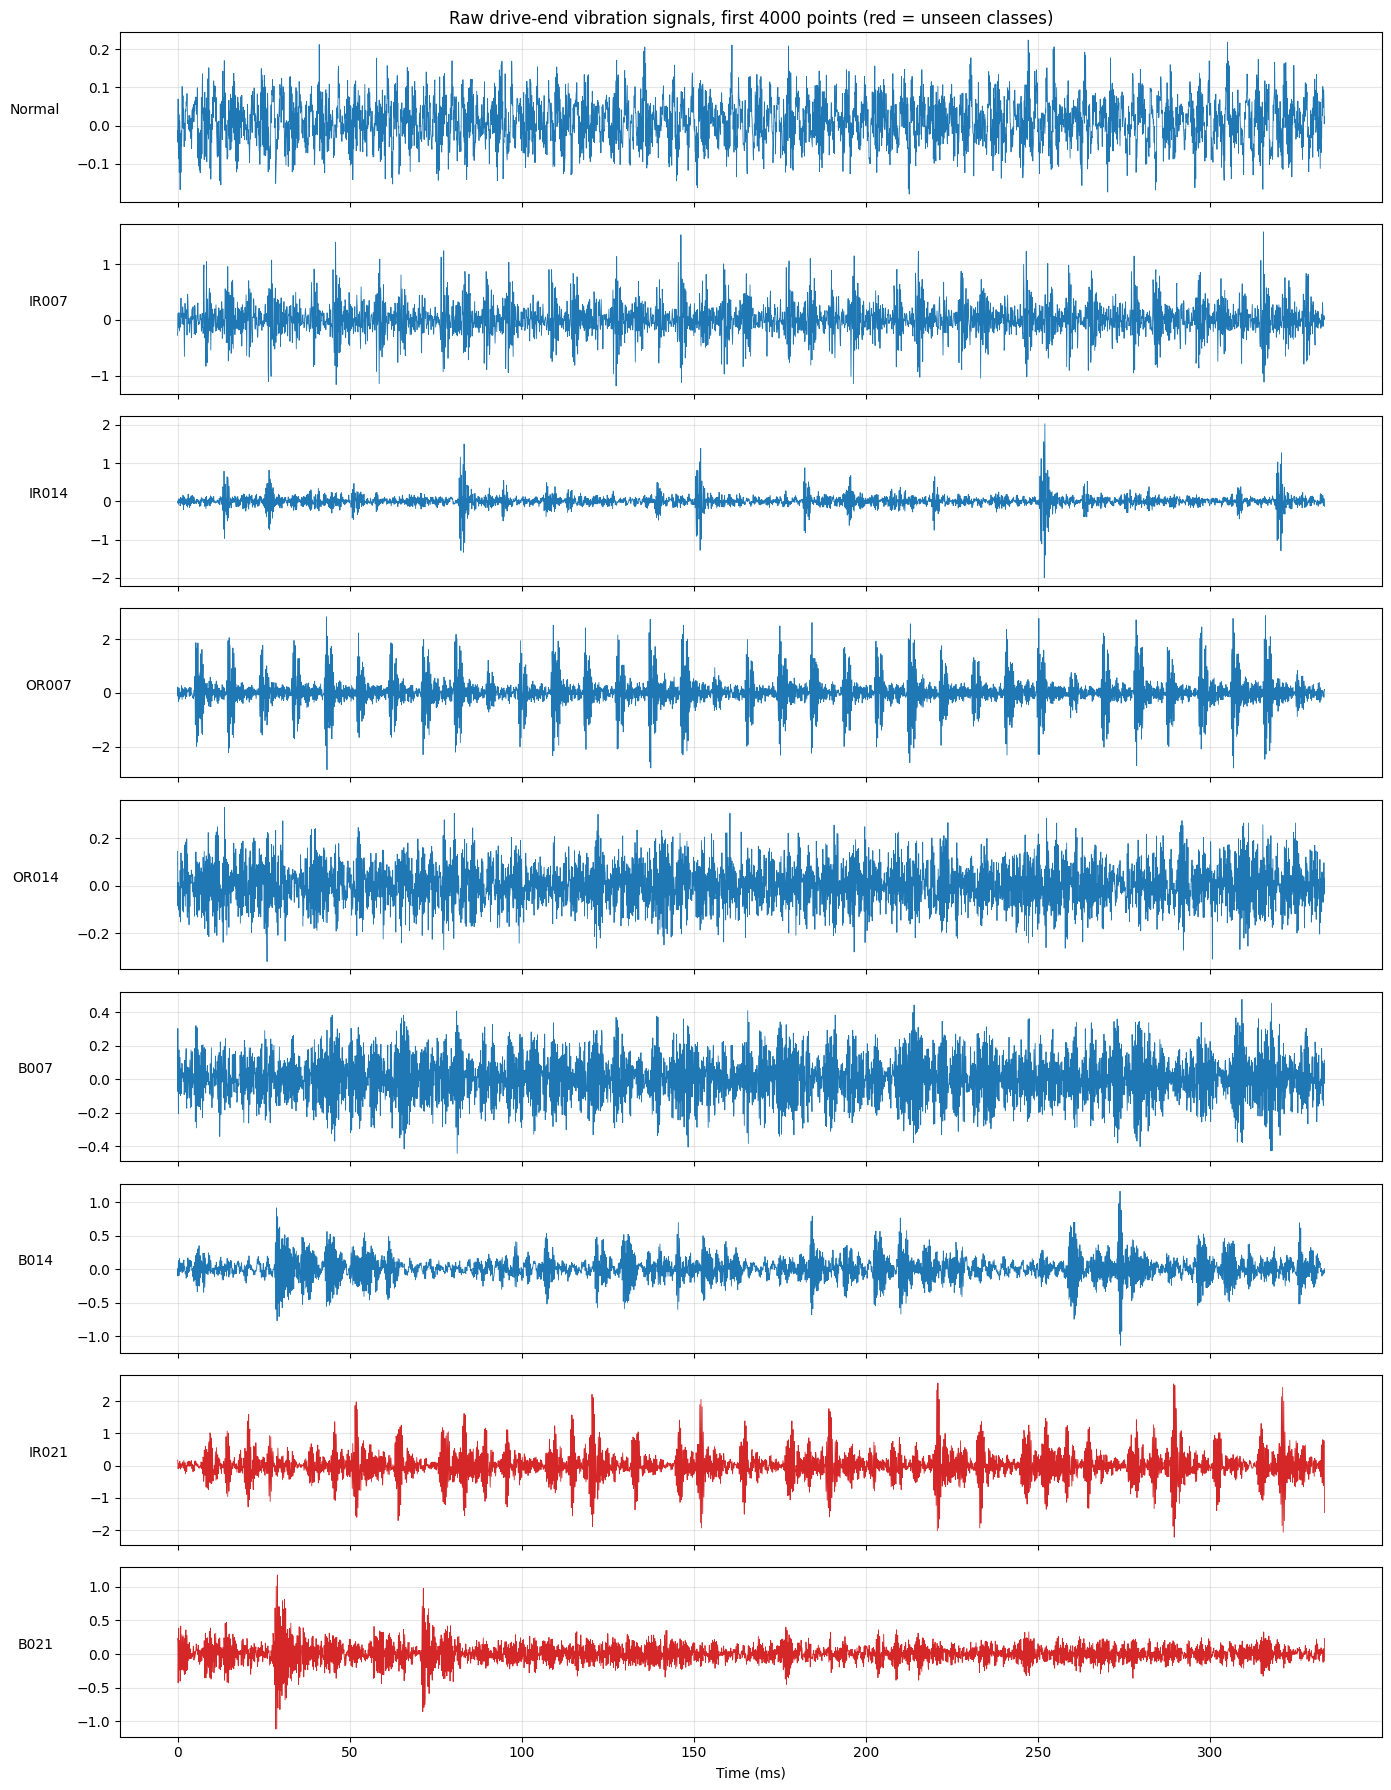

In [5]:
N_PLOT = 4000
t_ms = np.arange(N_PLOT) / FS * 1000
labels_all = list(raw_signals)
fig, axes = plt.subplots(len(labels_all), 1, figsize=(14, 2.0 * len(labels_all)), sharex=True)
for ax, label in zip(axes, labels_all):
    split = [v[2] for v in FILE_INFO.values() if v[0] == label][0]
    ax.plot(t_ms, raw_signals[label][:N_PLOT], lw=0.6, color="tab:red" if split == "unseen" else "tab:blue")
    ax.set_ylabel(label, rotation=0, labelpad=30)
    ax.grid(alpha=0.3)
axes[0].set_title(f"Raw drive-end vibration signals, first {N_PLOT} points (red = unseen classes)")
axes[-1].set_xlabel("Time (ms)")
plt.tight_layout(); savefig("A03_raw_signals"); plt.show()

## Step 4 — Basic statistics of each signal

In [6]:
rows = []
for label, x in raw_signals.items():
    rows.append({
        "class": label,
        "set": [v[2] for v in FILE_INFO.values() if v[0] == label][0],
        "n_samples": len(x),
        "duration_s": round(len(x) / FS, 2),
        "min": x.min(), "max": x.max(), "mean": x.mean(), "std": x.std(),
        "rms": np.sqrt(np.mean(x ** 2)),
        "kurtosis": kurtosis(x),
        "n_zeros": int(np.sum(x == 0)),
        "has_nan_or_inf": bool(~np.isfinite(x).all()),
    })
stats_df = pd.DataFrame(rows).set_index("class")
display(stats_df.round(4))
stats_df.to_csv(ART_DIR / "raw_signal_stats.csv")

# Sanity checks: catch broken files early
for label, r in stats_df.iterrows():
    if r["has_nan_or_inf"]:
        print(f"PROBLEM: {label} contains NaN/Inf values")
    if r["std"] < 1e-8:
        print(f"PROBLEM: {label} is (almost) constant — file probably broken")
    if r["n_zeros"] > 0.01 * r["n_samples"]:
        print(f"WARNING: {label} has {r['n_zeros']} exact zeros")
    if r["n_samples"] < 10 * WINDOW_SIZE:
        print(f"WARNING: {label} is very short ({r['n_samples']} samples)")
print("Sanity checks done.")

,set,n_samples,duration_s,min,max,mean,std,rms,kurtosis,n_zeros,has_nan_or_inf
class,,,,,,,,,,,
Normal,known,120976,10.08,-0.2822,0.2556,0.0126,0.0603,0.0616,-0.0243,0,False
IR007,known,121991,10.17,-1.4030,1.5808,0.0058,0.2928,0.2929,2.5423,39,False
IR014,known,121846,10.15,-2.0015,2.0301,0.0036,0.1655,0.1655,19.0843,100,False
OR007,known,122426,10.20,-3.0120,3.1123,0.0041,0.5919,0.5919,4.5950,38,False
OR014,known,122136,10.18,-0.4016,0.3958,0.0031,0.0935,0.0936,-0.0597,25,False
B007,known,121410,10.12,-0.6596,0.6397,0.0039,0.1390,0.1391,-0.0362,62,False
B014,known,122136,10.18,-1.3039,1.3398,0.0045,0.1408,0.1409,5.8371,85,False
IR021,unseen,121556,10.13,-3.2840,3.6861,0.0030,0.4418,0.4418,4.6667,100,False
B021,unseen,121701,10.14,-1.4135,1.4747,0.0043,0.1290,0.1291,6.4073,87,False


Sanity checks done.


## Step 5 — Normalize each signal (z-score: zero mean, unit variance)

Each signal is standardized with its own mean and standard deviation, so the model cannot separate classes purely by overall loudness/scale and must learn the shape of the fault patterns instead.

In [7]:
def zscore(x):
    return (x - x.mean()) / x.std()

norm_signals = {label: zscore(x) for label, x in raw_signals.items()}
norm_params = {label: {"mean": float(x.mean()), "std": float(x.std())} for label, x in raw_signals.items()}

for label, z in norm_signals.items():
    print(f"{label:<7} after normalization: mean={z.mean():+.2e}  std={z.std():.4f}  min={z.min():7.2f}  max={z.max():6.2f}")

with open(ART_DIR / "normalization_params.json", "w") as f:
    json.dump(norm_params, f, indent=2)

Normal  after normalization: mean=-9.87e-18  std=1.0000  min=  -4.89  max=  4.03
IR007   after normalization: mean=+3.17e-18  std=1.0000  min=  -4.81  max=  5.38
IR014   after normalization: mean=-3.86e-18  std=1.0000  min= -12.12  max= 12.25
OR007   after normalization: mean=+3.53e-18  std=1.0000  min=  -5.10  max=  5.25
OR014   after normalization: mean=+4.44e-18  std=1.0000  min=  -4.33  max=  4.20
B007    after normalization: mean=+9.58e-18  std=1.0000  min=  -4.77  max=  4.57
B014    after normalization: mean=+6.02e-18  std=1.0000  min=  -9.29  max=  9.48
IR021   after normalization: mean=+1.24e-17  std=1.0000  min=  -7.44  max=  8.34
B021    after normalization: mean=-1.20e-17  std=1.0000  min= -10.99  max= 11.40


## Step 6 — Window size and stride

- **Window size = 1024 points** (≈ 85 ms at 12 kHz). At ~1,772 rpm (1 hp load) the shaft turns about once every 34 ms, so each window covers ~2.5 shaft revolutions and several fault-impact periods (the fault characteristic frequencies are ~90–160 Hz, i.e. ~8–13 impacts per window).
- **Stride = 512 points** (50% overlap). This roughly doubles the number of samples compared with non-overlapping windows while keeping consecutive windows reasonably different.

In [8]:
print(f"Window size : {WINDOW_SIZE} points = {WINDOW_SIZE / FS * 1000:.1f} ms")
print(f"Stride      : {STRIDE} points ({100 * (1 - STRIDE / WINDOW_SIZE):.0f}% overlap)")
for label, z in norm_signals.items():
    n_win = (len(z) - WINDOW_SIZE) // STRIDE + 1
    print(f"  {label:<7} -> {n_win} windows expected")

Window size : 1024 points = 85.3 ms
Stride      : 512 points (50% overlap)
  Normal  -> 235 windows expected
  IR007   -> 237 windows expected
  IR014   -> 236 windows expected
  OR007   -> 238 windows expected
  OR014   -> 237 windows expected
  B007    -> 236 windows expected
  B014    -> 237 windows expected
  IR021   -> 236 windows expected
  B021    -> 236 windows expected


## Step 7 — Slice each normalized signal into windows

We also keep the start index of every window. This is needed in Step 13 to split train/test **by time** so overlapping windows never end up on both sides of the split.

In [9]:
def make_windows(x, window_size=WINDOW_SIZE, stride=STRIDE):
    starts = np.arange(0, len(x) - window_size + 1, stride)
    windows = np.stack([x[s:s + window_size] for s in starts]).astype(np.float32)
    return windows, starts

windowed = {}
for label, z in norm_signals.items():
    w, s = make_windows(z)
    windowed[label] = {"X": w, "starts": s, "sig_len": len(z)}
    print(f"{label:<7} windows shape = {w.shape}")

Normal  windows shape = (235, 1024)
IR007   windows shape = (237, 1024)
IR014   windows shape = (236, 1024)
OR007   windows shape = (238, 1024)
OR014   windows shape = (237, 1024)
B007    windows shape = (236, 1024)
B014    windows shape = (237, 1024)
IR021   windows shape = (236, 1024)
B021    windows shape = (236, 1024)


## Step 8 — Label each window

Every window inherits the fault-type label of the file it came from.

In [10]:
for label, d in windowed.items():
    d["y"] = np.array([label] * len(d["X"]))
    print(f"{label:<7} {len(d['y'])} windows labeled '{d['y'][0]}'")

Normal  235 windows labeled 'Normal'
IR007   237 windows labeled 'IR007'
IR014   236 windows labeled 'IR014'
OR007   238 windows labeled 'OR007'
OR014   237 windows labeled 'OR014'
B007    236 windows labeled 'B007'
B014    237 windows labeled 'B014'
IR021   236 windows labeled 'IR021'
B021    236 windows labeled 'B021'


## Step 9 — Example windows per class

Left: two example windows per class (time domain). Right: magnitude spectrum of the first window. Normal looks smooth and low-amplitude-impulse, while faulty bearings show sharp repeated impacts and energy in high-frequency resonance bands.

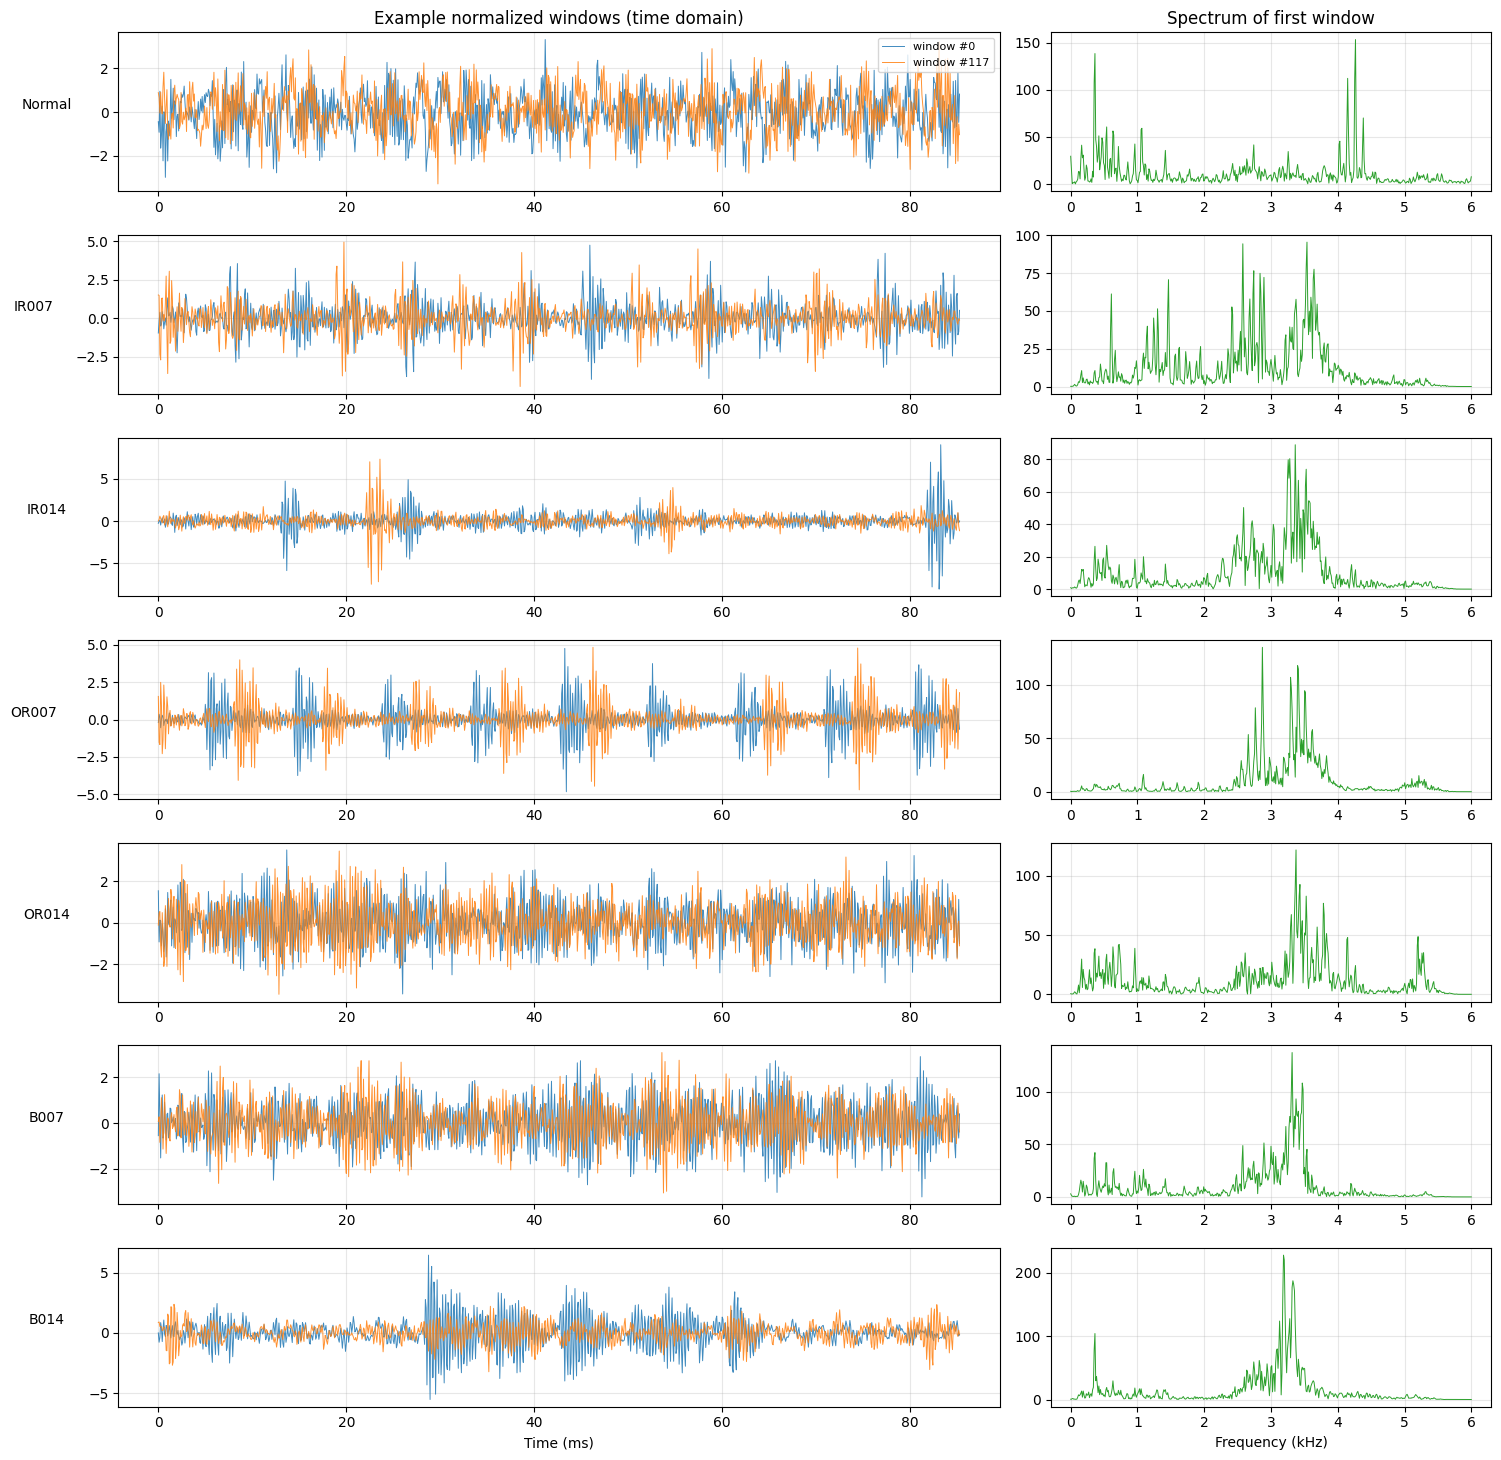

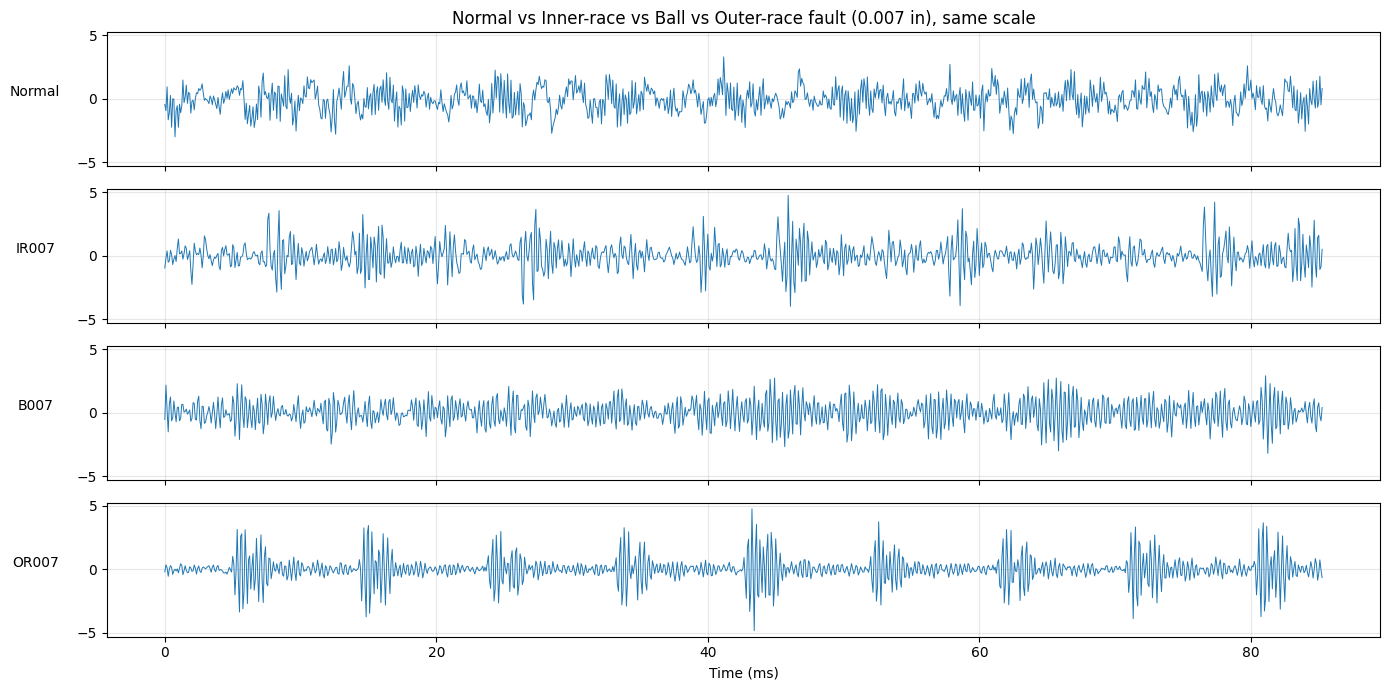

In [11]:
fig, axes = plt.subplots(len(KNOWN_CLASSES), 2, figsize=(15, 2.1 * len(KNOWN_CLASSES)),
                         gridspec_kw={"width_ratios": [2, 1]})
t_win = np.arange(WINDOW_SIZE) / FS * 1000
freqs = np.fft.rfftfreq(WINDOW_SIZE, d=1 / FS)
for i, label in enumerate(KNOWN_CLASSES):
    X = windowed[label]["X"]
    for j, idx in enumerate([0, len(X) // 2]):
        axes[i, 0].plot(t_win, X[idx], lw=0.7, alpha=0.85, label=f"window #{idx}")
    axes[i, 0].set_ylabel(label, rotation=0, labelpad=30)
    axes[i, 0].grid(alpha=0.3)
    spec = np.abs(np.fft.rfft(X[0] * np.hanning(WINDOW_SIZE)))
    axes[i, 1].plot(freqs / 1000, spec, lw=0.7, color="tab:green")
    axes[i, 1].grid(alpha=0.3)
axes[0, 0].set_title("Example normalized windows (time domain)")
axes[0, 1].set_title("Spectrum of first window")
axes[0, 0].legend(loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel("Time (ms)"); axes[-1, 1].set_xlabel("Frequency (kHz)")
plt.tight_layout(); savefig("A09_example_windows"); plt.show()

# Direct comparison Normal vs Inner race vs Ball vs Outer race (same axis scale)
fig, ax = plt.subplots(4, 1, figsize=(14, 7), sharex=True, sharey=True)
for a, label in zip(ax, ["Normal", "IR007", "B007", "OR007"]):
    a.plot(t_win, windowed[label]["X"][0], lw=0.7)
    a.set_ylabel(label, rotation=0, labelpad=30); a.grid(alpha=0.3)
ax[0].set_title("Normal vs Inner-race vs Ball vs Outer-race fault (0.007 in), same scale")
ax[-1].set_xlabel("Time (ms)")
plt.tight_layout(); savefig("A09_class_comparison"); plt.show()

## Step 10 — Combine all known-fault classes into one dataset

In [12]:
X_known = np.concatenate([windowed[c]["X"] for c in KNOWN_CLASSES])
y_known = np.concatenate([windowed[c]["y"] for c in KNOWN_CLASSES])
starts_known = np.concatenate([windowed[c]["starts"] for c in KNOWN_CLASSES])
siglen_known = np.concatenate([np.full(len(windowed[c]["X"]), windowed[c]["sig_len"]) for c in KNOWN_CLASSES])

print("X_known:", X_known.shape, "  y_known:", y_known.shape)

X_known: (1656, 1024)   y_known: (1656,)


## Step 11 — Check class balance

,windows,percent
Normal,235,14.19
IR007,237,14.31
IR014,236,14.25
OR007,238,14.37
OR014,237,14.31
B007,236,14.25
B014,237,14.31


Max/min class ratio: 1.01
Classes are roughly balanced (ratio <= 1.5). Still report macro-averaged metrics.


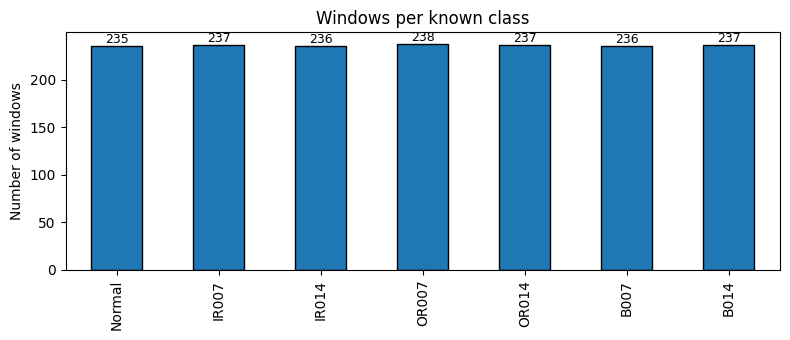

In [13]:
counts = pd.Series(y_known).value_counts().reindex(KNOWN_CLASSES)
balance_df = pd.DataFrame({"windows": counts, "percent": (100 * counts / counts.sum()).round(2)})
display(balance_df)
ratio = counts.max() / counts.min()
print(f"Max/min class ratio: {ratio:.2f}")
if ratio > 1.5:
    print("NOTE: noticeable imbalance -> use class weights and macro-averaged metrics.")
else:
    print("Classes are roughly balanced (ratio <= 1.5). Still report macro-averaged metrics.")

ax = counts.plot(kind="bar", figsize=(8, 3.5), color="tab:blue", edgecolor="k")
ax.set_ylabel("Number of windows"); ax.set_title("Windows per known class")
for i, v in enumerate(counts): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); savefig("A11_class_balance"); plt.show()

## Step 12 — Process the unseen fault files separately (IR021, B021)

Same normalize → window → label pipeline, stored in separate variables. This data is **never** used for training, validation, or model selection.

In [14]:
X_unseen = np.concatenate([windowed[c]["X"] for c in UNSEEN_CLASSES])
y_unseen = np.concatenate([windowed[c]["y"] for c in UNSEEN_CLASSES])
print("X_unseen:", X_unseen.shape)
print(pd.Series(y_unseen).value_counts())
assert not set(y_unseen) & set(y_known), "Unseen classes leaked into the known dataset!"
print("Confirmed: no unseen class present in the known dataset.")

X_unseen: (472, 1024)
IR021    236
B021     236
Name: count, dtype: int64
Confirmed: no unseen class present in the known dataset.


## Step 13 — Split the known-fault dataset into train (80%) and test (20%)

**Why not a plain random split?** With 50% overlap, neighbouring windows share half their points. A random split would put near-duplicate windows in both train and test, which inflates test accuracy (data leakage).

We therefore use a **blocked (time-based) stratified split**: for every class, windows from the first 80% of the recording go to train, windows from the last 20% go to test, and the one window that straddles the boundary is dropped. Class proportions stay the same in both sets. Set `SPLIT_MODE = "random"` to compare with the usual stratified random split.

In [15]:
SPLIT_MODE = "blocked"   # "blocked" (recommended, leakage-free) or "random"

if SPLIT_MODE == "blocked":
    boundary = TRAIN_FRAC * siglen_known
    train_mask = (starts_known + WINDOW_SIZE) <= boundary
    test_mask = starts_known >= boundary
    X_train, y_train = X_known[train_mask], y_known[train_mask]
    X_test, y_test = X_known[test_mask], y_known[test_mask]
    print(f"Dropped {np.sum(~train_mask & ~test_mask)} boundary windows to avoid overlap leakage.")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X_known, y_known, test_size=1 - TRAIN_FRAC, stratify=y_known, random_state=SEED)

split_df = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "test": pd.Series(y_test).value_counts(),
}).reindex(KNOWN_CLASSES)
split_df["test_%"] = (100 * split_df["test"] / (split_df["train"] + split_df["test"])).round(1)
display(split_df)
print(f"Train: {X_train.shape}   Test: {X_test.shape}   Unseen: {X_unseen.shape}")

np.savez_compressed(ART_DIR / "phaseA_dataset.npz",
                    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
                    X_unseen=X_unseen, y_unseen=y_unseen)
print("Saved processed dataset to", ART_DIR / "phaseA_dataset.npz")

Dropped 14 boundary windows to avoid overlap leakage.


,train,test,test_%
Normal,188,45,19.3
IR007,189,46,19.6
IR014,189,45,19.2
OR007,190,46,19.5
OR014,189,46,19.6
B007,188,46,19.7
B014,189,46,19.6


Train: (1322, 1024)   Test: (320, 1024)   Unseen: (472, 1024)
Saved processed dataset to artifacts/phaseA_dataset.npz


### Step 13b — Verify there is no overlap between train and test windows

For every class, the last sample used by any training window must come before the first sample used by any test window.

In [16]:
print(f"{'class':<7} {'last train sample':>18} {'first test sample':>18} {'gap':>6}")
for c in KNOWN_CLASSES:
    m = y_known == c
    tr = starts_known[train_mask & m]
    te = starts_known[test_mask & m]
    last_train_end = tr.max() + WINDOW_SIZE - 1      # last sample index used by train
    first_test = te.min()                            # first sample index used by test
    gap = first_test - last_train_end - 1
    print(f"{c:<7} {last_train_end:>18} {first_test:>18} {gap:>6}")
    assert last_train_end < first_test, f"Overlap in {c}!"
print("\nConfirmed: no train window shares any sample with a test window.")

class    last train sample  first test sample    gap
Normal               96767              97280    512
IR007                97279              97792    512
IR014                97279              97792    512
OR007                97791              98304    512
OR014                97279              97792    512
B007                 96767              97280    512
B014                 97279              97792    512

Confirmed: no train window shares any sample with a test window.


## Step 14 — (Optional) Feature-engineering baseline: Random Forest

The 1D-CNN learns features from raw windows, so manual features are not needed for it. As a simple point of comparison, we extract classic time-domain statistics and FFT band energies and train a Random Forest. Set `RUN_RF_BASELINE = False` to skip.

In [17]:
RUN_RF_BASELINE = True

def extract_features(X, n_bands=16):
    rms = np.sqrt(np.mean(X ** 2, axis=1))
    abs_mean = np.mean(np.abs(X), axis=1)
    peak = np.max(np.abs(X), axis=1)
    feats = [
        X.mean(axis=1), X.std(axis=1), rms, peak, X.max(axis=1) - X.min(axis=1),
        skew(X, axis=1), kurtosis(X, axis=1),
        peak / rms,          # crest factor
        rms / abs_mean,      # shape factor
        peak / abs_mean,     # impulse factor
    ]
    spec = np.abs(np.fft.rfft(X, axis=1)) ** 2
    bands = np.array_split(spec, n_bands, axis=1)
    band_energy = np.stack([b.sum(axis=1) for b in bands], axis=1)
    band_energy = band_energy / band_energy.sum(axis=1, keepdims=True)   # relative energy per band
    return np.column_stack(feats + [band_energy])

if RUN_RF_BASELINE:
    from sklearn.ensemble import RandomForestClassifier
    F_train, F_test = extract_features(X_train), extract_features(X_test)
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    rf.fit(F_train, y_train)
    rf_pred = rf.predict(F_test)
    rf_acc = accuracy_score(y_test, rf_pred)
    print(f"Random Forest baseline test accuracy: {rf_acc:.4f}  ({F_train.shape[1]} features)")
    print(classification_report(y_test, rf_pred, labels=KNOWN_CLASSES, digits=4, zero_division=0))

Random Forest baseline test accuracy: 1.0000  (26 features)
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000        45
       IR007     1.0000    1.0000    1.0000        46
       IR014     1.0000    1.0000    1.0000        45
       OR007     1.0000    1.0000    1.0000        46
       OR014     1.0000    1.0000    1.0000        46
        B007     1.0000    1.0000    1.0000        46
        B014     1.0000    1.0000    1.0000        46

    accuracy                         1.0000       320
   macro avg     1.0000    1.0000    1.0000       320
weighted avg     1.0000    1.0000    1.0000       320



### End of Phase A
We now have normalized, windowed and labeled **train**, **test** and a completely separate **unseen-fault** set.

---
# PHASE B: Baseline Neural Fault Detector + Uncertainty Scoring

## Step 15 — Encode text labels into numbers

We use a fixed, explicit mapping (instead of alphabetical order) so it is easy to read and stays identical in later phases. Unseen classes get **no** numeric label because the model has no output for them.

In [18]:
CLASS_TO_ID = {c: i for i, c in enumerate(KNOWN_CLASSES)}
ID_TO_CLASS = {i: c for c, i in CLASS_TO_ID.items()}
NUM_CLASSES = len(KNOWN_CLASSES)

y_train_id = np.array([CLASS_TO_ID[c] for c in y_train])
y_test_id = np.array([CLASS_TO_ID[c] for c in y_test])

print("Label mapping:", CLASS_TO_ID)
with open(ART_DIR / "label_mapping.json", "w") as f:
    json.dump(CLASS_TO_ID, f, indent=2)

Label mapping: {'Normal': 0, 'IR007': 1, 'IR014': 2, 'OR007': 3, 'OR014': 4, 'B007': 5, 'B014': 6}


## Step 16 — Reshape for the 1D-CNN

Keras `Conv1D` expects `(samples, time_steps, channels)`. We have one sensor channel, so the shape is `(n, 1024, 1)`.

We also need a **validation set** for monitoring training and for choosing the threshold later, so the test and unseen sets stay untouched. It is split **by time**, like the test set: in every recording, windows from **0–70%** are used for training and windows from **70–80%** for validation, and the windows that cross the 70% boundary are dropped. A random 10% split was used earlier, but because windows overlap by 50%, about 83% of those validation windows were made entirely of samples the model had trained on. That made validation confidence too high and pushed τ up.

Final layout of every recording: **train 0–70% | validation 70–80% | test 80–100%**, with no shared samples (checked in Step 16b).

In [19]:
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]
X_unseen_cnn = X_unseen[..., np.newaxis]

VAL_FRAC = 0.10                                    # fraction of each recording used for validation
if SPLIT_MODE == "blocked":
    tr_starts_all = starts_known[train_mask]       # same order as X_train / y_train
    tr_len_all = siglen_known[train_mask]
    val_boundary = (TRAIN_FRAC - VAL_FRAC) * tr_len_all          # 70% of each recording
    tr_mask2 = (tr_starts_all + WINDOW_SIZE) <= val_boundary     # windows fully before 70%
    val_mask2 = tr_starts_all >= val_boundary                    # windows fully between 70% and 80%
    X_tr, y_tr = X_train_cnn[tr_mask2], y_train_id[tr_mask2]
    X_val, y_val = X_train_cnn[val_mask2], y_train_id[val_mask2]
    print(f"Blocked validation split. Dropped {int(np.sum(~tr_mask2 & ~val_mask2))} boundary windows.")
else:
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_cnn, y_train_id, test_size=VAL_FRAC, stratify=y_train_id, random_state=SEED)
    print("WARNING: random validation split — validation windows overlap training windows.")

print("X_tr   :", X_tr.shape, " X_val:", X_val.shape)
print("X_test :", X_test_cnn.shape)
print("X_unseen:", X_unseen_cnn.shape)

Blocked validation split. Dropped 14 boundary windows.
X_tr   : (1154, 1024, 1)  X_val: (154, 1024, 1)
X_test : (320, 1024, 1)
X_unseen: (472, 1024, 1)


### Step 16b — Verify there is no overlap between train, validation and test

For every class, the last training sample must come before the first validation sample, and the last validation sample before the first test sample.

In [20]:
if SPLIT_MODE == "blocked":
    rows = []
    s_test_all = starts_known[test_mask]
    for c in KNOWN_CLASSES:
        cid = CLASS_TO_ID[c]
        s_tr = tr_starts_all[tr_mask2][y_tr == cid]
        s_val = tr_starts_all[val_mask2][y_val == cid]
        s_te = s_test_all[y_test == c]
        last_tr, first_val = s_tr.max() + WINDOW_SIZE - 1, s_val.min()
        last_val, first_te = s_val.max() + WINDOW_SIZE - 1, s_te.min()
        rows.append({"class": c, "train windows": len(s_tr), "val windows": len(s_val), "test windows": len(s_te),
                     "last train sample": last_tr, "first val sample": first_val,
                     "last val sample": last_val, "first test sample": first_te,
                     "gap train/val": first_val - last_tr - 1, "gap val/test": first_te - last_val - 1})
        assert last_tr < first_val and last_val < first_te, f"Overlap in {c}!"
    display(pd.DataFrame(rows).set_index("class"))
    val_overlap_ok = True
    print("Confirmed: train, validation and test windows share no samples.")
else:
    val_overlap_ok = False
    print("SPLIT_MODE is 'random': validation is not separated in time from training.")

,train windows,val windows,test windows,last train sample,first val sample,last val sample,first test sample,gap train/val,gap val/test
class,,,,,,,,,
Normal,164,22,45,84479,84992,96767,97280,512,512
IR007,165,22,46,84991,85504,97279,97792,512,512
IR014,165,22,45,84991,85504,97279,97792,512,512
OR007,166,22,46,85503,86016,97791,98304,512,512
OR014,165,22,46,84991,85504,97279,97792,512,512
B007,164,22,46,84479,84992,96767,97280,512,512
B014,165,22,46,84991,85504,97279,97792,512,512


Confirmed: train, validation and test windows share no samples.


## Step 17 — Build the 1D-CNN

Architecture inspired by WDCNN (Zhang et al., 2017), which is widely used on CWRU: a **wide first kernel** (64 points) acts like a learned filter bank and suppresses high-frequency noise, followed by small-kernel convolution blocks, global average pooling and a softmax output.

In [21]:
def build_cnn(input_len=WINDOW_SIZE, n_classes=NUM_CLASSES):
    inp = keras.Input(shape=(input_len, 1))
    x = layers.Conv1D(16, kernel_size=64, strides=8, padding="same")(inp)   # wide first kernel
    x = layers.BatchNormalization(momentum=0.9)(x); x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)
    for filters in (32, 64, 64):
        x = layers.Conv1D(filters, kernel_size=3, padding="same")(x)
        x = layers.BatchNormalization(momentum=0.9)(x); x = layers.ReLU()(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(100, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="fault_cnn_1d")

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "fault_cnn_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1024, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 16)        │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 32, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 16, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │         6,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,079 (113.59 KB)

 Trainable params: 28,727 (112.21 KB)

 Non-trainable params: 352 (1.38 KB)

## Step 18 — Train the model

Early stopping on validation loss (restoring the best weights) and learning-rate reduction on plateau. BatchNorm uses momentum 0.9 so its running statistics settle quickly on this small dataset (~40 steps per epoch); with the default 0.99 validation accuracy can lag far behind training accuracy for many epochs. Class weights are applied in case the classes are slightly imbalanced.

In [22]:
EPOCHS = 50
BATCH_SIZE = 32

cls_counts = np.bincount(y_tr, minlength=NUM_CLASSES)
class_weight = {i: len(y_tr) / (NUM_CLASSES * c) for i, c in enumerate(cls_counts)}
print("Class weights:", {ID_TO_CLASS[i]: round(w, 3) for i, w in class_weight.items()})

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                    callbacks=callbacks, shuffle=True, verbose=2)
model.save(ART_DIR / "fault_cnn_1d.keras")
print("Model saved to", ART_DIR / "fault_cnn_1d.keras")

Class weights: {'Normal': np.float64(1.005), 'IR007': np.float64(0.999), 'IR014': np.float64(0.999), 'OR007': np.float64(0.993), 'OR014': np.float64(0.999), 'B007': np.float64(1.005), 'B014': np.float64(0.999)}
Epoch 1/50
37/37 - 17s - 464ms/step - accuracy: 0.7210 - loss: 0.9907 - val_accuracy: 0.9935 - val_loss: 0.3586 - learning_rate: 0.0010
Epoch 2/50
37/37 - 3s - 75ms/step - accuracy: 0.9931 - loss: 0.1660 - val_accuracy: 1.0000 - val_loss: 0.0298 - learning_rate: 0.0010
Epoch 3/50
37/37 - 1s - 20ms/step - accuracy: 0.9983 - loss: 0.0656 - val_accuracy: 1.0000 - val_loss: 0.0131 - learning_rate: 0.0010
Epoch 4/50
37/37 - 1s - 21ms/step - accuracy: 0.9965 - loss: 0.0449 - val_accuracy: 1.0000 - val_loss: 0.0072 - learning_rate: 0.0010
Epoch 5/50
37/37 - 1s - 33ms/step - accuracy: 0.9983 - loss: 0.0293 - val_accuracy: 1.0000 - val_loss: 0.0051 - learning_rate: 0.0010
Epoch 6/50
37/37 - 1s - 33ms/step - accuracy: 1.0000 - loss: 0.0221 - val_accuracy: 1.0000 - val_loss: 0.0038 - learn

## Step 19 — Known-fault accuracy on the test set

In [23]:
test_loss, test_acc = model.evaluate(X_test_cnn, y_test_id, verbose=0)
probs_test = model.predict(X_test_cnn, verbose=0)
pred_test = probs_test.argmax(axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy (known faults): {test_acc:.4f}")
print(classification_report(y_test_id, pred_test, target_names=KNOWN_CLASSES, digits=4, zero_division=0))
if RUN_RF_BASELINE:
    print(f"For comparison, Random Forest baseline accuracy: {rf_acc:.4f}")

Test loss: 0.0001
Test accuracy (known faults): 1.0000
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000        45
       IR007     1.0000    1.0000    1.0000        46
       IR014     1.0000    1.0000    1.0000        45
       OR007     1.0000    1.0000    1.0000        46
       OR014     1.0000    1.0000    1.0000        46
        B007     1.0000    1.0000    1.0000        46
        B014     1.0000    1.0000    1.0000        46

    accuracy                         1.0000       320
   macro avg     1.0000    1.0000    1.0000       320
weighted avg     1.0000    1.0000    1.0000       320

For comparison, Random Forest baseline accuracy: 1.0000


## Step 20 — Training curves

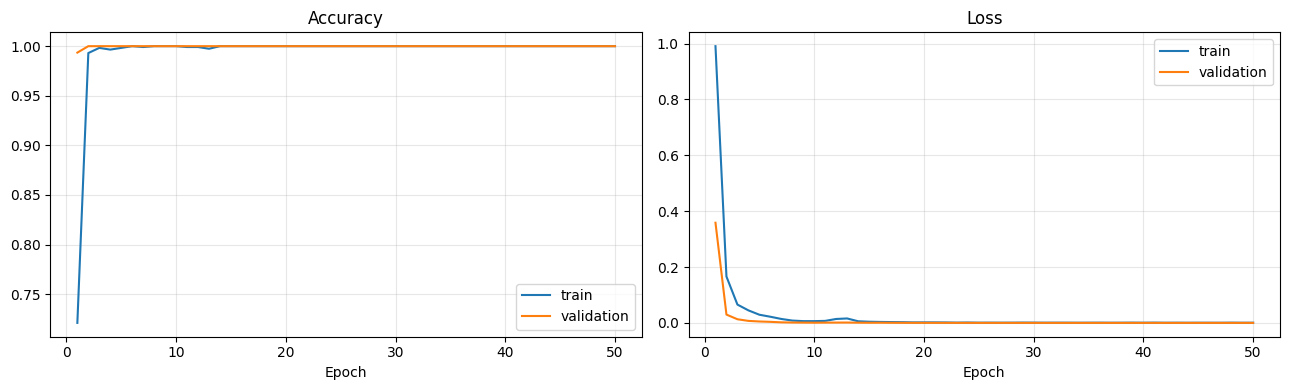

Best epoch: 50  train acc=1.0000  val acc=1.0000
Overfitting gap (train - val acc) at best epoch: 0.0


In [24]:
h = history.history
ep = np.arange(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ep, h["accuracy"], label="train"); ax[0].plot(ep, h["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, h["loss"], label="train"); ax[1].plot(ep, h["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); savefig("B20_training_curves"); plt.show()

best = int(np.argmin(h["val_loss"]))
print(f"Best epoch: {best + 1}  train acc={h['accuracy'][best]:.4f}  val acc={h['val_accuracy'][best]:.4f}")
gap = h["accuracy"][best] - h["val_accuracy"][best]
print("Overfitting gap (train - val acc) at best epoch:", round(gap, 4))

## Step 21 — Confusion matrix on the test set

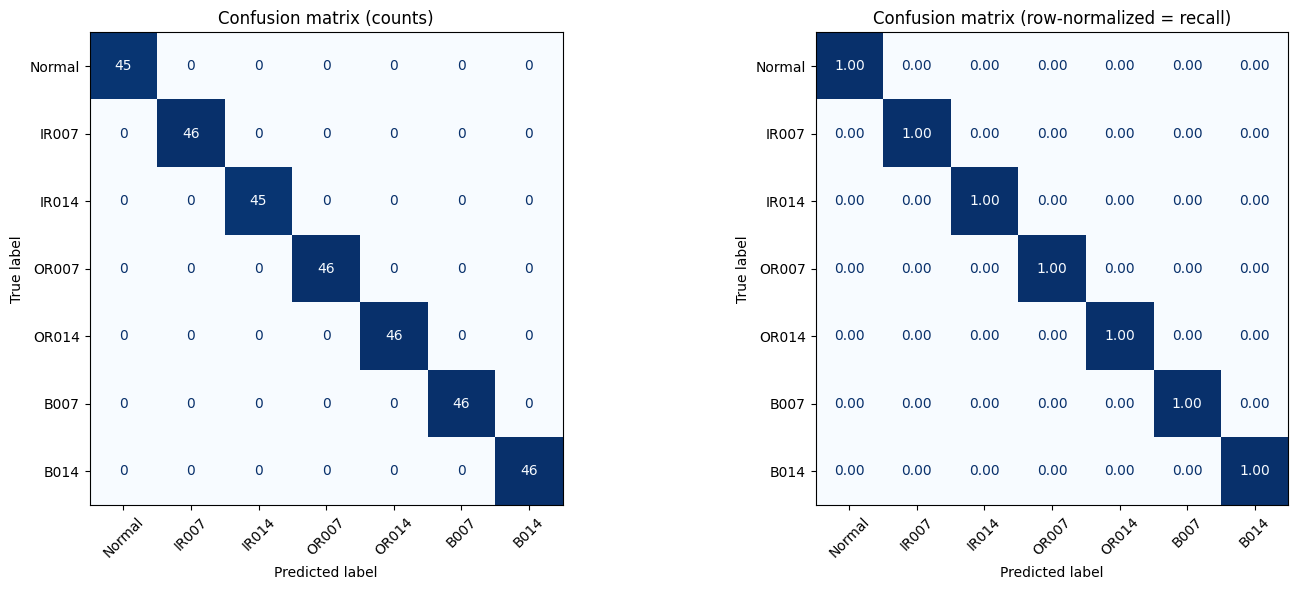

No misclassifications on the test set.


In [25]:
cm = confusion_matrix(y_test_id, pred_test, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=KNOWN_CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Confusion matrix (counts)")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm, display_labels=KNOWN_CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Confusion matrix (row-normalized = recall)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("B21_confusion_matrix"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
if off.sum() == 0:
    print("No misclassifications on the test set.")
else:
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Most frequent confusion: true {KNOWN_CLASSES[i]} -> predicted {KNOWN_CLASSES[j]} ({off[i, j]} windows)")

## Step 22 — Confidence score (maximum softmax probability)

$\text{conf}(x) = \max_k p_k(x)$ — ranges from $1/K$ (completely unsure) to $1$ (fully confident).

In [26]:
def confidence_score(probs):
    '''Maximum softmax probability per sample. Higher = more confident.'''
    return np.max(probs, axis=1)

## Step 23 — Entropy score

$H(x) = -\sum_k p_k \log p_k$ uses the whole probability vector, not only the top class. We also report the normalized version $H / \log K \in [0, 1]$ (0 = certain, 1 = uniform over all classes).

In [27]:
def entropy_score(probs, normalized=True, eps=1e-12):
    '''Predictive entropy per sample. Higher = more uncertain.'''
    p = np.clip(probs, eps, 1.0)
    H = -np.sum(p * np.log(p), axis=1)
    return H / np.log(probs.shape[1]) if normalized else H

# quick check on toy vectors
toy = np.array([[1.0] + [0.0] * 6, [1 / 7] * 7, [0.5, 0.5] + [0.0] * 5])
print("confidence:", confidence_score(toy).round(3))
print("entropy   :", entropy_score(toy).round(3))

confidence: [1.    0.143 0.5  ]
entropy   : [0.    1.    0.356]


## Step 24 — Scores on the KNOWN-fault test set

In [28]:
conf_known = confidence_score(probs_test)
ent_known = entropy_score(probs_test)

probs_val = model.predict(X_val, verbose=0)          # used later for the threshold
conf_val, ent_val = confidence_score(probs_val), entropy_score(probs_val)

correct = pred_test == y_test_id
print(f"Known test set ({len(conf_known)} windows)")
print(f"  mean confidence = {conf_known.mean():.4f}   median = {np.median(conf_known):.4f}")
print(f"  mean entropy    = {ent_known.mean():.4f}   median = {np.median(ent_known):.4f}")
if (~correct).any():
    print(f"  mean confidence on correct predictions = {conf_known[correct].mean():.4f}, "
          f"on wrong ones = {conf_known[~correct].mean():.4f}")

Known test set (320 windows)
  mean confidence = 0.9999   median = 1.0000
  mean entropy    = 0.0004   median = 0.0002


## Step 25 — Scores on the UNSEEN-fault set (IR021, B021)

We also look at which known class the model *thinks* the unseen windows belong to — a good explanation point for the report (e.g. IR021 is often mapped to an inner-race class, because it is physically similar).

In [29]:
probs_unseen = model.predict(X_unseen_cnn, verbose=0)
conf_unseen = confidence_score(probs_unseen)
ent_unseen = entropy_score(probs_unseen)
pred_unseen = np.array([ID_TO_CLASS[i] for i in probs_unseen.argmax(axis=1)])

print(f"Unseen set ({len(conf_unseen)} windows)")
print(f"  mean confidence = {conf_unseen.mean():.4f}   median = {np.median(conf_unseen):.4f}")
print(f"  mean entropy    = {ent_unseen.mean():.4f}   median = {np.median(ent_unseen):.4f}")

print("\nWhat the model predicts for unseen faults (fraction of windows):")
display(pd.crosstab(pd.Series(y_unseen, name="true unseen class"),
                    pd.Series(pred_unseen, name="predicted known class"), normalize="index").round(3))

summary_rows = [("Known test", conf_known, ent_known)]
summary_rows += [(c, conf_unseen[y_unseen == c], ent_unseen[y_unseen == c]) for c in UNSEEN_CLASSES]
summary_rows += [("Unseen (all)", conf_unseen, ent_unseen)]
score_summary = pd.DataFrame([{
    "set": n, "n": len(c),
    "conf_mean": c.mean(), "conf_median": np.median(c), "conf_std": c.std(),
    "entropy_mean": e.mean(), "entropy_median": np.median(e), "entropy_std": e.std(),
} for n, c, e in summary_rows]).set_index("set")
display(score_summary.round(4))
score_summary.to_csv(ART_DIR / "uncertainty_summary.csv")

Unseen set (472 windows)
  mean confidence = 0.8186   median = 0.9017
  mean entropy    = 0.2648   median = 0.2164

What the model predicts for unseen faults (fraction of windows):


predicted known class,B007,B014,IR007,IR014,OR007
true unseen class,,,,,
B021,0.936,0.047,0.000,0.017,0.000
IR021,0.000,0.788,0.025,0.000,0.186


,n,conf_mean,conf_median,conf_std,entropy_mean,entropy_median,entropy_std
set,,,,,,,
Known test,320,0.9999,1.0000,0.0002,0.0004,0.0002,0.0008
IR021,236,0.6576,0.6637,0.1618,0.4961,0.5168,0.1604
B021,236,0.9797,0.9986,0.0762,0.0336,0.0062,0.0882
Unseen (all),472,0.8186,0.9017,0.2048,0.2648,0.2164,0.2650


## Step 26 — Compare known vs unseen score distributions

Histograms and box plots, plus **AUROC** as a single number for how well each score separates known from unseen (0.5 = no separation, 1.0 = perfect).

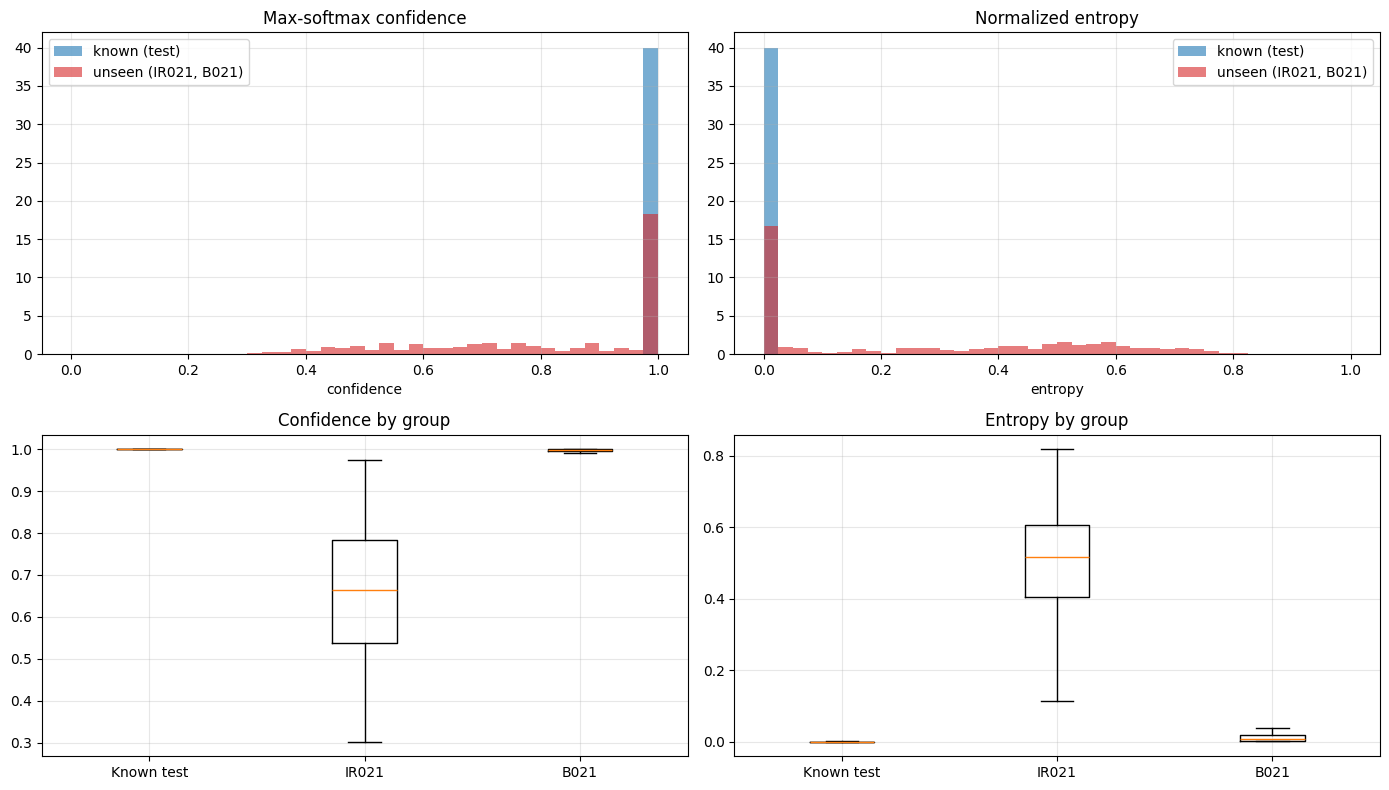

AUROC known-vs-unseen using (1 - confidence): 0.9941
AUROC known-vs-unseen using entropy         : 0.9944
Expected behaviour (lower confidence on unseen): YES
Expected behaviour (higher entropy on unseen)  : YES


In [30]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
bins = np.linspace(0, 1, 41)

ax[0, 0].hist(conf_known, bins=bins, alpha=0.6, density=True, label="known (test)")
ax[0, 0].hist(conf_unseen, bins=bins, alpha=0.6, density=True, label="unseen (IR021, B021)", color="tab:red")
ax[0, 0].set_title("Max-softmax confidence"); ax[0, 0].set_xlabel("confidence"); ax[0, 0].legend()

ax[0, 1].hist(ent_known, bins=bins, alpha=0.6, density=True, label="known (test)")
ax[0, 1].hist(ent_unseen, bins=bins, alpha=0.6, density=True, label="unseen (IR021, B021)", color="tab:red")
ax[0, 1].set_title("Normalized entropy"); ax[0, 1].set_xlabel("entropy"); ax[0, 1].legend()

groups = ["Known test"] + UNSEEN_CLASSES
conf_groups = [conf_known] + [conf_unseen[y_unseen == c] for c in UNSEEN_CLASSES]
ent_groups = [ent_known] + [ent_unseen[y_unseen == c] for c in UNSEEN_CLASSES]
ax[1, 0].boxplot(conf_groups, showfliers=False); ax[1, 0].set_xticks(range(1, len(groups) + 1), groups)
ax[1, 0].set_title("Confidence by group")
ax[1, 1].boxplot(ent_groups, showfliers=False); ax[1, 1].set_xticks(range(1, len(groups) + 1), groups)
ax[1, 1].set_title("Entropy by group")
for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout(); savefig("B26_known_vs_unseen_scores"); plt.show()

# Quantitative separation: label unseen = 1 (positive), known = 0
is_unseen = np.r_[np.zeros(len(conf_known)), np.ones(len(conf_unseen))]
unc_conf = np.r_[1 - conf_known, 1 - conf_unseen]      # higher = more uncertain
unc_ent = np.r_[ent_known, ent_unseen]
auroc_conf = roc_auc_score(is_unseen, unc_conf)
auroc_ent = roc_auc_score(is_unseen, unc_ent)
print(f"AUROC known-vs-unseen using (1 - confidence): {auroc_conf:.4f}")
print(f"AUROC known-vs-unseen using entropy         : {auroc_ent:.4f}")
print("Expected behaviour (lower confidence on unseen):",
      "YES" if conf_unseen.mean() < conf_known.mean() else "NO")
print("Expected behaviour (higher entropy on unseen)  :",
      "YES" if ent_unseen.mean() > ent_known.mean() else "NO")

## Step 27 — Select the threshold τ

**Primary method (no leakage):** τ is chosen **only from known data** (the validation split), as the 5th percentile of validation confidence. This means ~95% of known-fault windows are accepted and anything less confident than that triggers the fallback layer. The same idea is applied to entropy (95th percentile). This is the honest choice, because in real deployment you do not have samples of the unknown faults in advance.

**Reference method (for analysis only):** the ROC-optimal (Youden J) threshold computed with the unseen data. It shows the best separation possible with this score, but it uses the unseen set and is therefore optimistic. It should not be used as the deployed threshold.

Primary tau (from validation, 95% known acceptance):
  tau_conf    = 0.9998  -> uncertain if confidence < tau_conf
  tau_entropy = 0.0011  -> uncertain if entropy > tau_entropy
    known test flagged (conf)        5.9%
    unseen flagged (conf)           98.7%
    known test flagged (entropy)     5.3%
    unseen flagged (entropy)        98.7%
    IR021 flagged (conf)                100.0%
    B021 flagged (conf)                 97.5%

Reference (Youden J, optimistic): tau_conf=0.9998 (flags 98.7% unseen / 5.3% known), tau_entropy=0.0011 (flags 98.9% unseen / 5.3% known)


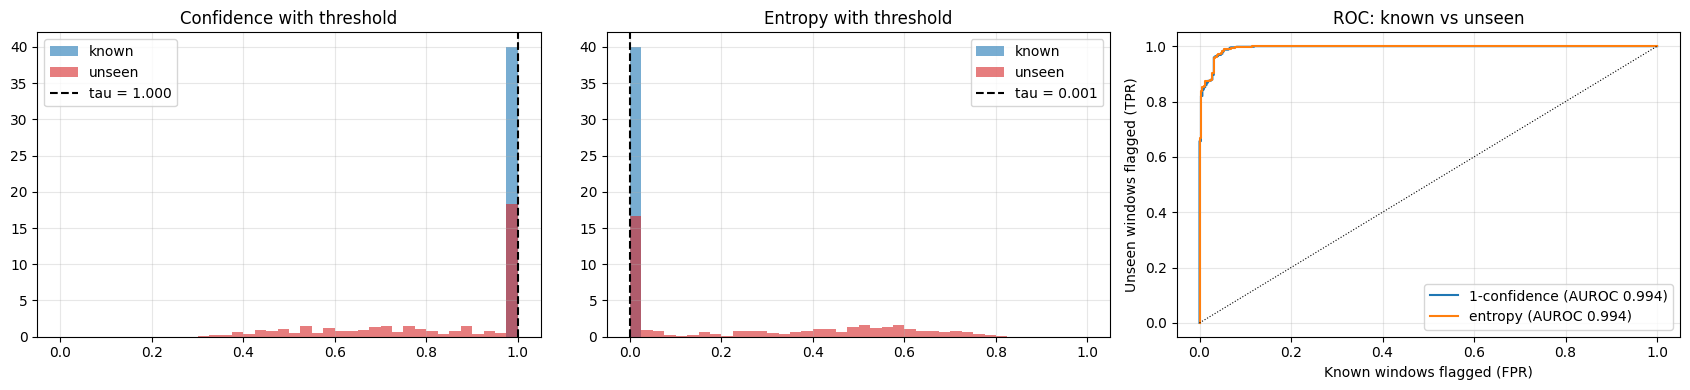


Saved thresholds to artifacts/uncertainty_thresholds.json


In [31]:
TARGET_KNOWN_ACCEPT = 0.95

tau_conf = float(np.quantile(conf_val, 1 - TARGET_KNOWN_ACCEPT))   # accept if conf >= tau_conf
tau_ent = float(np.quantile(ent_val, TARGET_KNOWN_ACCEPT))         # accept if entropy <= tau_ent

def flag_rates(tau_c, tau_e):
    return {
        "known test flagged (conf)": np.mean(conf_known < tau_c),
        "unseen flagged (conf)": np.mean(conf_unseen < tau_c),
        "known test flagged (entropy)": np.mean(ent_known > tau_e),
        "unseen flagged (entropy)": np.mean(ent_unseen > tau_e),
    }

print(f"Primary tau (from validation, {TARGET_KNOWN_ACCEPT:.0%} known acceptance):")
print(f"  tau_conf    = {tau_conf:.4f}  -> uncertain if confidence < tau_conf")
print(f"  tau_entropy = {tau_ent:.4f}  -> uncertain if entropy > tau_entropy")
for k, v in flag_rates(tau_conf, tau_ent).items():
    print(f"    {k:<30} {v:6.1%}")
for c in UNSEEN_CLASSES:
    m = y_unseen == c
    print(f"    {c} flagged (conf)                {np.mean(conf_unseen[m] < tau_conf):6.1%}")

# Reference: Youden-J optimal thresholds (uses unseen data -> optimistic)
fpr_c, tpr_c, thr_c = roc_curve(is_unseen, unc_conf)
fpr_e, tpr_e, thr_e = roc_curve(is_unseen, unc_ent)
j_c, j_e = np.argmax(tpr_c - fpr_c), np.argmax(tpr_e - fpr_e)
tau_conf_youden = float(1 - thr_c[j_c]); tau_ent_youden = float(thr_e[j_e])
print(f"\nReference (Youden J, optimistic): tau_conf={tau_conf_youden:.4f} "
      f"(flags {tpr_c[j_c]:.1%} unseen / {fpr_c[j_c]:.1%} known), "
      f"tau_entropy={tau_ent_youden:.4f} (flags {tpr_e[j_e]:.1%} unseen / {fpr_e[j_e]:.1%} known)")

# Visualize the chosen threshold
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(conf_known, bins=bins, alpha=0.6, density=True, label="known")
ax[0].hist(conf_unseen, bins=bins, alpha=0.6, density=True, label="unseen", color="tab:red")
ax[0].axvline(tau_conf, color="k", ls="--", label=f"tau = {tau_conf:.3f}")
ax[0].set_title("Confidence with threshold"); ax[0].legend()
ax[1].hist(ent_known, bins=bins, alpha=0.6, density=True, label="known")
ax[1].hist(ent_unseen, bins=bins, alpha=0.6, density=True, label="unseen", color="tab:red")
ax[1].axvline(tau_ent, color="k", ls="--", label=f"tau = {tau_ent:.3f}")
ax[1].set_title("Entropy with threshold"); ax[1].legend()
ax[2].plot(fpr_c, tpr_c, label=f"1-confidence (AUROC {auroc_conf:.3f})")
ax[2].plot(fpr_e, tpr_e, label=f"entropy (AUROC {auroc_ent:.3f})")
ax[2].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[2].set_xlabel("Known windows flagged (FPR)"); ax[2].set_ylabel("Unseen windows flagged (TPR)")
ax[2].set_title("ROC: known vs unseen"); ax[2].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); savefig("B27_threshold_selection"); plt.show()

thresholds = {
    "method": f"{TARGET_KNOWN_ACCEPT:.0%} acceptance on known validation set",
    "tau_confidence": tau_conf, "tau_entropy": tau_ent,
    "reference_youden_tau_confidence": tau_conf_youden,
    "reference_youden_tau_entropy": tau_ent_youden,
    "auroc_confidence": float(auroc_conf), "auroc_entropy": float(auroc_ent),
    "test_accuracy_known": float(test_acc),
}
with open(ART_DIR / "uncertainty_thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)
print("\nSaved thresholds to", ART_DIR / "uncertainty_thresholds.json")

## Uncertainty gate (ready for Phase C)

A small helper that combines the classifier with the threshold: confident predictions are returned directly, uncertain ones are routed to the fallback layer.

In [32]:
def predict_with_uncertainty(windows, model=model, tau=tau_conf, score="confidence"):
    '''windows: (n, 1024) or (n, 1024, 1) normalized windows.
    Returns predicted class names, the score, and a boolean "needs_fallback" flag.'''
    w = windows if windows.ndim == 3 else windows[..., np.newaxis]
    probs = model.predict(w, verbose=0)
    pred = np.array([ID_TO_CLASS[i] for i in probs.argmax(axis=1)])
    if score == "confidence":
        s = confidence_score(probs); needs_fallback = s < tau
    else:
        s = entropy_score(probs); needs_fallback = s > tau
    return pred, s, needs_fallback

pred, s, fb = predict_with_uncertainty(X_test[:5])
print("Known examples :", list(zip(pred, s.round(3), fb)))
pred, s, fb = predict_with_uncertainty(X_unseen[:5])
print("Unseen examples:", list(zip(pred, s.round(3), fb)))

Known examples : [(np.str_('Normal'), np.float32(1.0), np.False_), (np.str_('Normal'), np.float32(1.0), np.False_), (np.str_('Normal'), np.float32(1.0), np.True_), (np.str_('Normal'), np.float32(1.0), np.False_), (np.str_('Normal'), np.float32(1.0), np.False_)]
Unseen examples: [(np.str_('B014'), np.float32(0.96), np.True_), (np.str_('B014'), np.float32(0.888), np.True_), (np.str_('B014'), np.float32(0.797), np.True_), (np.str_('B014'), np.float32(0.8), np.True_), (np.str_('B014'), np.float32(0.786), np.True_)]


## Phase B summary

In [33]:
print("=" * 60)
print("PHASE A + B SUMMARY")
print("=" * 60)
print(f"Window size / stride        : {WINDOW_SIZE} / {STRIDE}")
print(f"Split mode                  : {SPLIT_MODE}")
print(f"Train / val / test / unseen : {len(X_tr)} / {len(X_val)} / {len(X_test)} / {len(X_unseen)} windows")
print(f"Known-fault test accuracy   : {test_acc:.4f}")
if RUN_RF_BASELINE:
    print(f"Random Forest baseline acc  : {rf_acc:.4f}")
print(f"Mean confidence known/unseen: {conf_known.mean():.4f} / {conf_unseen.mean():.4f}")
print(f"Mean entropy    known/unseen: {ent_known.mean():.4f} / {ent_unseen.mean():.4f}")
print(f"AUROC (confidence / entropy): {auroc_conf:.4f} / {auroc_ent:.4f}")
print(f"Chosen tau (confidence)     : {tau_conf:.4f}  -> flags {np.mean(conf_unseen < tau_conf):.1%} of unseen, "
      f"{np.mean(conf_known < tau_conf):.1%} of known")
print(f"\nFigures saved in  : {FIG_DIR.resolve()}")
print(f"Artifacts saved in: {ART_DIR.resolve()}")

PHASE A + B SUMMARY
Window size / stride        : 1024 / 512
Split mode                  : blocked
Train / val / test / unseen : 1154 / 154 / 320 / 472 windows
Known-fault test accuracy   : 1.0000
Random Forest baseline acc  : 1.0000
Mean confidence known/unseen: 0.9999 / 0.8186
Mean entropy    known/unseen: 0.0004 / 0.2648
AUROC (confidence / entropy): 0.9941 / 0.9944
Chosen tau (confidence)     : 0.9998  -> flags 98.7% of unseen, 5.9% of known

Figures saved in  : /content/figures
Artifacts saved in: /content/artifacts


### Notes for the report
- **Leakage-free split:** because windows overlap by 50%, all splits are done by time within each recording (train 0–70%, validation 70–80%, test 80–100%). A random split would put near-duplicate windows on both sides; in an earlier version, 83% of randomly chosen validation windows consisted entirely of training samples, which inflated τ.
- **Interpreting unseen results:** IR021 and B021 are *larger versions* of fault types the model already knows, so the model may still be quite confident on some of them (it maps them to IR014/B014-like patterns). If the confidence gap is small, that is an honest finding and a motivation for Phase C (fallback layer) and for stronger uncertainty methods (e.g. MC-dropout, temperature scaling, deep ensembles, or feature-space distance scores).
- **Threshold choice:** the deployed τ is taken from known validation data only; the Youden-J value is reported only as an upper-bound reference.

---
# PHASE B+ : Extended Uncertainty Analysis

Three additions based on the Phase B results:

1. **2 hp control test.** Is the detector flagging *new fault types*, or just *new recordings / operating conditions*? We test on the same seven known classes recorded at **2 hp load** (a different recording the model has never seen). These files are used **only for evaluation**, never for training or for choosing thresholds.
2. **Logit-based scores.** Softmax confidence is saturated near 1 (τ ≈ 0.9999), which makes the threshold fragile. We add the **logit margin** and the **log-residual score** −log(1 − confidence), which spread the same information over a wider, more stable range.
3. **Multi-window aggregation.** Instead of judging each 85 ms window alone, we combine the decision over K consecutive windows.

These cells use the model and variables from Phases A and B, so run them in the same session (or use *Runtime → Run all*).

## B+.1 — Download the 2 hp recordings

Same source and resampling as the first download cell. CWRU file numbers at 2 hp (12 kHz drive-end): Normal = 99 (48 kHz, resampled to 12 kHz), IR007 = 107, IR014 = 171, OR007@6 = 132, OR014@6 = 199, B007 = 120, B014 = 187. The unseen sizes at 2 hp (IR021 = 211, B021 = 224) are also downloaded, to check that unseen faults are still flagged under the new load.

In [34]:
import requests, urllib3
from scipy.io import savemat
from scipy.signal import resample_poly

base_url = "https://engineering.case.edu/sites/default/files/"
target_fs = 12_000

files_2hp = {
    "control_2hp/normal_2hp.mat":  ("99.mat",  48_000),
    "control_2hp/IR007_2.mat":     ("107.mat", 12_000),
    "control_2hp/IR014_2.mat":     ("171.mat", 12_000),
    "control_2hp/OR007@6_2.mat":   ("132.mat", 12_000),
    "control_2hp/OR014@6_2.mat":   ("199.mat", 12_000),
    "control_2hp/B007_2.mat":      ("120.mat", 12_000),
    "control_2hp/B014_2.mat":      ("187.mat", 12_000),
    "control_2hp/IR021_2.mat":     ("211.mat", 12_000),
    "control_2hp/B021_2.mat":      ("224.mat", 12_000),
}

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

for output, (source, source_fs) in files_2hp.items():
    path = Path("bearing_dataset") / output
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        print(f"{output} already exists, skipping download")
        continue
    print(f"Downloading {output}...")
    response = requests.get(base_url + source, timeout=120, verify=False)
    response.raise_for_status()
    path.write_bytes(response.content)

    if source_fs != target_fs:
        mat_data = loadmat(path)
        resampled_data = {}
        for key, value in mat_data.items():
            if key.startswith("__"):
                continue
            if key.endswith("_time"):
                value = resample_poly(value.squeeze(), target_fs, source_fs)
            resampled_data[key] = value
        savemat(path, resampled_data)
        print(f"Downloaded and resampled from {source_fs / 1000:g} kHz to {target_fs / 1000:g} kHz")
    else:
        print(f"Downloaded at {target_fs / 1000:g} kHz")

print("\n2 hp download complete.")

Downloaded and resampled from 48 kHz to 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz
Downloaded at 12 kHz

2 hp download complete.


## B+.2 — Preprocess the 2 hp files with exactly the same pipeline

Load → drive-end key → per-signal z-score → windows of 1024 with stride 512. Nothing from these files touches training or threshold selection.

,set,key,n_samples,mean,std,windows
class,,,,,,
Normal,known,X099_DE_time,121266,0.0123,0.0560,235
IR007,known,X107_DE_time,122136,0.0046,0.2995,237
IR014,known,X171_DE_time,121846,0.0037,0.1630,236
OR007,known,X132_DE_time,121410,0.0039,0.5702,236
OR014,known,X199_DE_time,121846,0.0032,0.0968,236
B007,known,X120_DE_time,121556,0.0046,0.1472,236
B014,known,X187_DE_time,121991,0.0046,0.1434,237
IR021,unseen,X211_DE_time,121846,0.0034,0.4889,236
B021,unseen,X224_DE_time,122136,0.0046,0.1072,237


Known 2 hp : (1653, 1024)   Unseen 2 hp: (473, 1024)


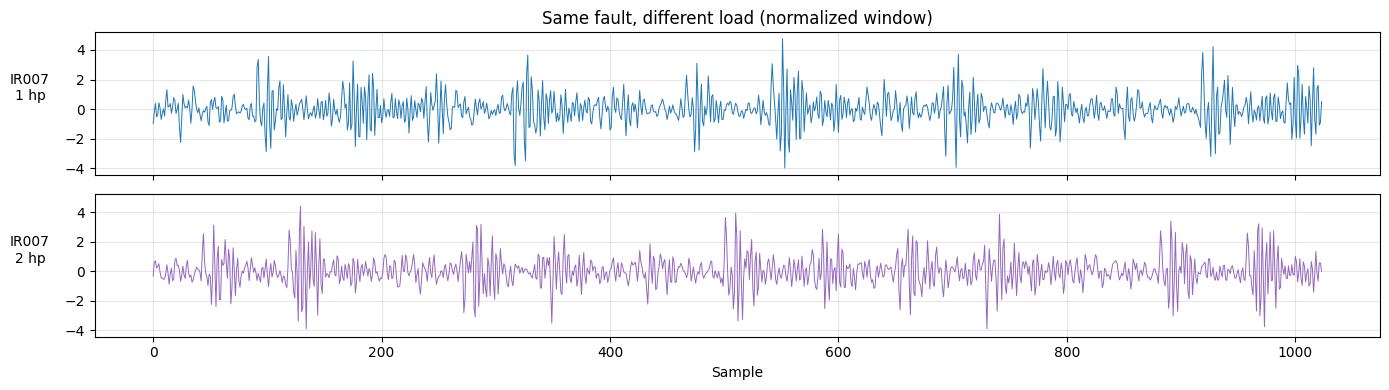

In [35]:
FILE_INFO_2HP = {
    "control_2hp/normal_2hp.mat": ("Normal", 99,  "known"),
    "control_2hp/IR007_2.mat":    ("IR007",  107, "known"),
    "control_2hp/IR014_2.mat":    ("IR014",  171, "known"),
    "control_2hp/OR007@6_2.mat":  ("OR007",  132, "known"),
    "control_2hp/OR014@6_2.mat":  ("OR014",  199, "known"),
    "control_2hp/B007_2.mat":     ("B007",   120, "known"),
    "control_2hp/B014_2.mat":     ("B014",   187, "known"),
    "control_2hp/IR021_2.mat":    ("IR021",  211, "unseen"),
    "control_2hp/B021_2.mat":     ("B021",   224, "unseen"),
}

win_2hp = {}
rows = []
for rel_path, (label, file_no, kind) in FILE_INFO_2HP.items():
    mat = loadmat(DATA_DIR / rel_path)
    key = find_de_key(mat, file_no)
    x = np.asarray(mat[key], dtype=np.float64).ravel()
    assert np.isfinite(x).all() and x.std() > 1e-8, f"{label} 2hp signal looks broken"
    w, _ = make_windows(zscore(x))
    win_2hp[label] = w
    rows.append({"class": label, "set": kind, "key": key, "n_samples": len(x),
                 "mean": x.mean(), "std": x.std(), "windows": len(w)})
display(pd.DataFrame(rows).set_index("class").round(4))

X_known2 = np.concatenate([win_2hp[c] for c in KNOWN_CLASSES])
y_known2 = np.concatenate([[c] * len(win_2hp[c]) for c in KNOWN_CLASSES])
X_unseen2 = np.concatenate([win_2hp[c] for c in UNSEEN_CLASSES])
y_unseen2 = np.concatenate([[c] * len(win_2hp[c]) for c in UNSEEN_CLASSES])
print("Known 2 hp :", X_known2.shape, "  Unseen 2 hp:", X_unseen2.shape)

# Compare 1 hp vs 2 hp raw signal for one class (visual check of the domain shift)
fig, ax = plt.subplots(2, 1, figsize=(14, 4), sharex=True, sharey=True)
ax[0].plot(windowed["IR007"]["X"][0], lw=0.7); ax[0].set_ylabel("IR007\n1 hp", rotation=0, labelpad=25)
ax[1].plot(win_2hp["IR007"][0], lw=0.7, color="tab:purple"); ax[1].set_ylabel("IR007\n2 hp", rotation=0, labelpad=25)
ax[0].set_title("Same fault, different load (normalized window)"); ax[1].set_xlabel("Sample")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); savefig("Bplus_1hp_vs_2hp_IR007"); plt.show()

## B+.3 — Logit-based uncertainty scores

The softmax squeezes very different logit vectors into probabilities that all look like 0.9999…, so we compute scores directly from the **logits** (the values before softmax), in float64:

- **Logit margin** = top logit − second logit. Large margin = confident.
- **Log-residual** = −log(1 − max softmax), computed stably from logits with log-sum-exp. Same ranking information as confidence but not saturated (0.9999 → 9.2, 0.999999 → 13.8).

For both, **higher = more confident**, so a window is uncertain when the score is **below** τ. Each τ is chosen exactly like before: 95% acceptance on the known **validation** set.

In [36]:
from scipy.special import logsumexp

# Sub-model up to the layer before the softmax Dense layer; logits = h @ W + b
feature_model = keras.Model(model.inputs, model.layers[-2].output)
W_out, b_out = [w.astype(np.float64) for w in model.layers[-1].get_weights()]

def get_logits(X):
    X = X if X.ndim == 3 else X[..., np.newaxis]
    h = feature_model.predict(X, verbose=0).astype(np.float64)
    return h @ W_out + b_out

def logit_margin(z):
    zs = np.sort(z, axis=1)
    return zs[:, -1] - zs[:, -2]

def log_residual(z):
    '''-log(1 - max softmax) = logsumexp(all logits) - logsumexp(all logits except the top one).'''
    zs = np.sort(z, axis=1)
    return logsumexp(zs, axis=1) - logsumexp(zs[:, :-1], axis=1)

# Sanity check: softmax(logits) must reproduce the model's probabilities
z_check = get_logits(X_test[:50])
p_check = np.exp(z_check - logsumexp(z_check, axis=1, keepdims=True))
print("max |softmax(logits) - model probs| =", float(np.abs(p_check - probs_test[:50]).max()))

EVAL_SETS = {
    "Known 1hp (test)":    (X_test,   y_test),
    "Unseen 1hp":          (X_unseen, y_unseen),
    "Known 2hp (control)": (X_known2, y_known2),
    "Unseen 2hp":          (X_unseen2, y_unseen2),
}

SCORE_FUNCS = {
    "confidence":   lambda z: np.exp(-(logsumexp(z, axis=1) - z.max(axis=1))),   # = max softmax, float64
    "logit_margin": logit_margin,
    "log_residual": log_residual,
}

z_val = get_logits(X_val)
TAU = {name: float(np.quantile(f(z_val), 1 - TARGET_KNOWN_ACCEPT)) for name, f in SCORE_FUNCS.items()}

scores = {}      # scores[set_name][score_name] -> array
preds = {}
for set_name, (X, y) in EVAL_SETS.items():
    z = get_logits(X)
    preds[set_name] = np.array([ID_TO_CLASS[i] for i in z.argmax(axis=1)])
    scores[set_name] = {name: f(z) for name, f in SCORE_FUNCS.items()}

print("\nThresholds (95% acceptance on known validation data):")
for name, t in TAU.items():
    print(f"  tau_{name:<13} = {t:.6g}")

max |softmax(logits) - model probs| = 2.3754095557215749e-07

Thresholds (95% acceptance on known validation data):
  tau_confidence    = 0.999802
  tau_logit_margin  = 9.14109
  tau_log_residual  = 8.52969


## B+.4 — Compare the scores on all four groups

Flag rate = fraction of windows with score < τ (sent to the fallback layer). AUROC is computed against the known 1 hp test set: for the **unseen** groups we want it high (easy to detect); for the **known 2 hp** control we want it close to 0.5 (the detector should not care about the load change).

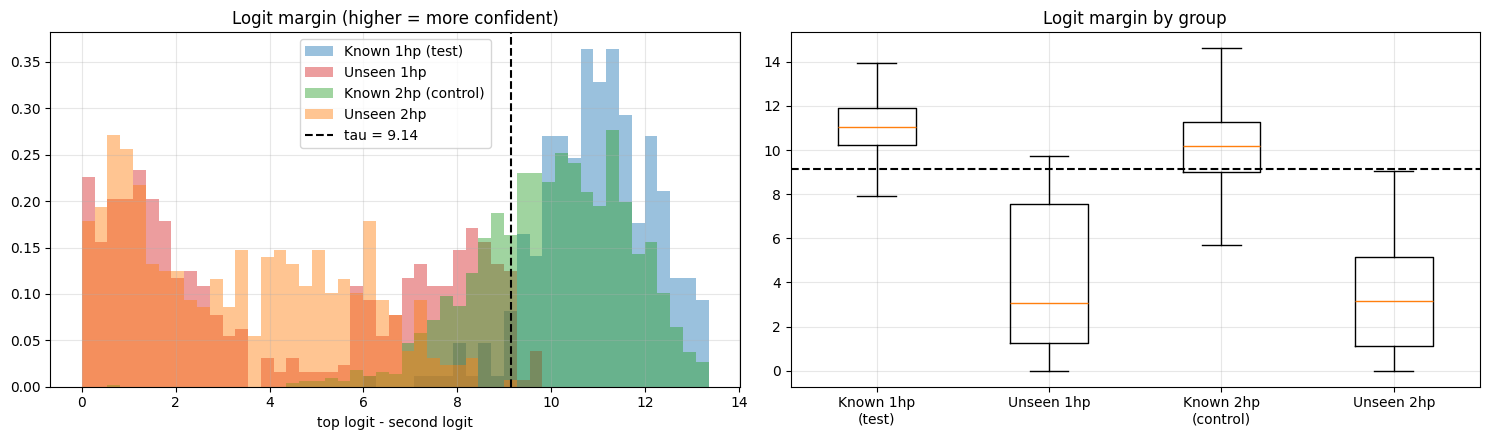

In [37]:
ref = "Known 1hp (test)"
rows = []
for score_name in SCORE_FUNCS:
    for set_name in EVAL_SETS:
        s = scores[set_name][score_name]
        row = {"score": score_name, "set": set_name,
               "median": np.median(s),
               "flag_rate": np.mean(s < TAU[score_name])}
        if set_name != ref:
            s_ref = scores[ref][score_name]
            lab = np.r_[np.zeros(len(s_ref)), np.ones(len(s))]
            row["AUROC_vs_known_test"] = roc_auc_score(lab, -np.r_[s_ref, s])   # low score = positive
        rows.append(row)
cmp_df = pd.DataFrame(rows).set_index(["score", "set"])
display(cmp_df.style.format({"median": "{:.5g}", "flag_rate": "{:.1%}", "AUROC_vs_known_test": "{:.4f}"}, na_rep="—"))
cmp_df.to_csv(ART_DIR / "extended_score_comparison.csv")

# Per-class flag rates (logit margin) — which classes trigger the fallback?
per_class = []
for set_name, (X, y) in EVAL_SETS.items():
    s = scores[set_name]["logit_margin"]
    for c in pd.unique(y):
        m = y == c
        per_class.append({"set": set_name, "class": c, "windows": int(m.sum()),
                          "flag_rate (margin)": np.mean(s[m] < TAU["logit_margin"]),
                          "most predicted as": pd.Series(preds[set_name][m]).mode()[0]})
display(pd.DataFrame(per_class).set_index(["set", "class"]).style.format({"flag_rate (margin)": "{:.1%}"}))

# Distributions of the logit margin
colors = {"Known 1hp (test)": "tab:blue", "Unseen 1hp": "tab:red",
          "Known 2hp (control)": "tab:green", "Unseen 2hp": "tab:orange"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
all_m = np.concatenate([scores[s]["logit_margin"] for s in EVAL_SETS])
bins_m = np.linspace(all_m.min(), np.quantile(all_m, 0.995), 50)
for set_name in EVAL_SETS:
    ax[0].hist(scores[set_name]["logit_margin"], bins=bins_m, alpha=0.45, density=True,
               label=set_name, color=colors[set_name])
ax[0].axvline(TAU["logit_margin"], color="k", ls="--", label=f"tau = {TAU['logit_margin']:.2f}")
ax[0].set_title("Logit margin (higher = more confident)"); ax[0].set_xlabel("top logit - second logit"); ax[0].legend()
ax[1].boxplot([scores[s]["logit_margin"] for s in EVAL_SETS], showfliers=False)
ax[1].set_xticks(range(1, len(EVAL_SETS) + 1), [s.replace(" (", "\n(") for s in EVAL_SETS])
ax[1].axhline(TAU["logit_margin"], color="k", ls="--")
ax[1].set_title("Logit margin by group")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); savefig("Bplus_logit_margin_groups"); plt.show()

## B+.5 — 2 hp control test: accuracy and interpretation

Accuracy on the 2 hp known classes also tells us how well the classifier generalizes to a new load. Combined with the flag rate, it shows whether the fallback is triggered for the right reason.

Classification accuracy on known classes at 2 hp (new load): 1.0000
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000       235
       IR007     1.0000    1.0000    1.0000       237
       IR014     1.0000    1.0000    1.0000       236
       OR007     1.0000    1.0000    1.0000       236
       OR014     1.0000    1.0000    1.0000       236
        B007     1.0000    1.0000    1.0000       236
        B014     1.0000    1.0000    1.0000       237

    accuracy                         1.0000      1653
   macro avg     1.0000    1.0000    1.0000      1653
weighted avg     1.0000    1.0000    1.0000      1653



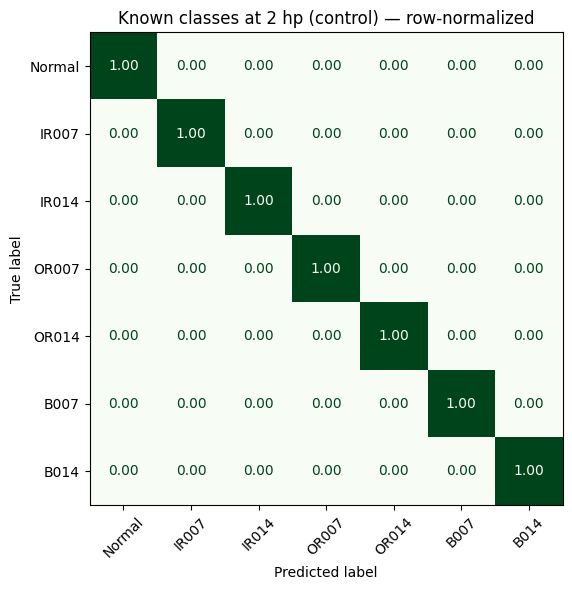

Flag rates (logit_margin): known 1hp 5.6% | known 2hp 27.9% | unseen 1hp 98.1% | unseen 2hp 100.0%
AUROC vs known test: known 2hp 0.676 | unseen 1hp 0.991

Relative position of the control group between known (0) and unseen (1): 0.24
Interpretation: The 2 hp known classes behave like the known test set: the uncertainty score reacts mainly to NEW FAULT TYPES, not to the change of recording/load. This supports the method.


In [38]:
y2_id = np.array([CLASS_TO_ID[c] for c in y_known2])
p2_id = np.array([CLASS_TO_ID[c] for c in preds["Known 2hp (control)"]])
acc_2hp = accuracy_score(y2_id, p2_id)
print(f"Classification accuracy on known classes at 2 hp (new load): {acc_2hp:.4f}")
print(classification_report(y2_id, p2_id, labels=range(NUM_CLASSES), target_names=KNOWN_CLASSES,
                            digits=4, zero_division=0))

cm2 = confusion_matrix(y2_id, p2_id, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm2 / cm2.sum(axis=1, keepdims=True), display_labels=KNOWN_CLASSES).plot(
    ax=ax, cmap="Greens", colorbar=False, values_format=".2f")
ax.set_title("Known classes at 2 hp (control) — row-normalized"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("Bplus_confusion_2hp"); plt.show()

# Interpretation based on the logit margin at the window level
s_name = "logit_margin"
r_known = np.mean(scores["Known 1hp (test)"][s_name] < TAU[s_name])
r_unseen = np.mean(scores["Unseen 1hp"][s_name] < TAU[s_name])
r_ctrl = np.mean(scores["Known 2hp (control)"][s_name] < TAU[s_name])
r_unseen2 = np.mean(scores["Unseen 2hp"][s_name] < TAU[s_name])
auc_ctrl = cmp_df.loc[(s_name, "Known 2hp (control)"), "AUROC_vs_known_test"]
auc_unseen = cmp_df.loc[(s_name, "Unseen 1hp"), "AUROC_vs_known_test"]

print(f"Flag rates ({s_name}): known 1hp {r_known:.1%} | known 2hp {r_ctrl:.1%} | "
      f"unseen 1hp {r_unseen:.1%} | unseen 2hp {r_unseen2:.1%}")
print(f"AUROC vs known test: known 2hp {auc_ctrl:.3f} | unseen 1hp {auc_unseen:.3f}\n")

gap = r_unseen - r_known
position = float(np.clip((r_ctrl - r_known) / gap, -1, 2)) if gap > 0.05 else float("nan")   # 0 = like known, 1 = like unseen
if np.isnan(position):
    verdict = ("Unseen faults are not flagged clearly more often than known faults at the window level, "
               "so the control test is inconclusive with this score. Check the aggregation results below.")
elif position < 0.33:
    verdict = ("The 2 hp known classes behave like the known test set: the uncertainty score reacts mainly "
               "to NEW FAULT TYPES, not to the change of recording/load. This supports the method.")
elif position < 0.67:
    verdict = ("The 2 hp known classes fall in between: the score reacts partly to fault novelty and partly "
               "to the change of operating condition. Report this as a limitation.")
else:
    verdict = ("The 2 hp known classes are flagged about as often as the unseen faults: the score mainly detects "
               "a CHANGE OF RECORDING/LOAD (domain shift), not specifically new fault types. Report this as a "
               "key limitation; the fallback would also fire when the load changes.")
print(f"Relative position of the control group between known (0) and unseen (1): {position:.2f}")
print("Interpretation:", verdict)
if acc_2hp < 0.9:
    print(f"Note: accuracy at 2 hp is only {acc_2hp:.1%}, so flagging these windows is partly *useful* — "
          "the classifier really is less reliable under the new load.")

## B+.6 — Multi-window aggregation

In a monitoring system, decisions do not need to be made from a single 85 ms window. We combine **K consecutive windows** (always from the same recording, in time order) in two ways, both using the *per-window* thresholds from above so no new tuning is needed:

- **Mean score:** average the score over the K windows, then compare with τ.
- **Majority vote:** flag the group if at least half of its K windows are flagged.

Groups are formed with a sliding window (step 1), so the rates are smooth but neighbouring groups are correlated. With 50% overlap, K windows cover `(K + 1) × 512` samples.


Flag rate by K — score: confidence (mean-score aggregation / majority vote)



Flag rate by K — score: logit_margin (mean-score aggregation / majority vote)


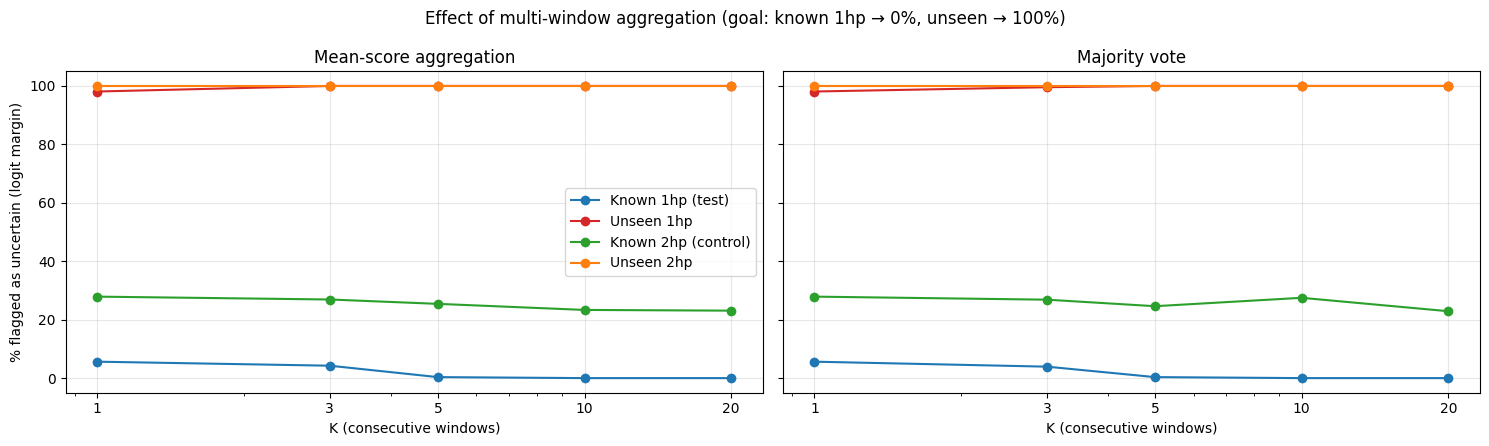

In [39]:
K_VALUES = [1, 3, 5, 10, 20]

def rolling_mean_per_class(values, labels, K):
    out = []
    for c in pd.unique(labels):
        v = values[labels == c].astype(np.float64)       # already in time order within each class
        if len(v) >= K:
            out.append(np.convolve(v, np.ones(K) / K, mode="valid"))
    return np.concatenate(out)

agg_rows = []
for s_name in ["confidence", "logit_margin"]:
    tau = TAU[s_name]
    for set_name, (X, y) in EVAL_SETS.items():
        s = scores[set_name][s_name]
        for K in K_VALUES:
            mean_s = rolling_mean_per_class(s, y, K)
            vote = rolling_mean_per_class((s < tau).astype(float), y, K)
            agg_rows.append({"score": s_name, "set": set_name, "K": K,
                             "duration_s": ((K + 1) * STRIDE) / FS,
                             "flag_rate_mean": np.mean(mean_s < tau),
                             "flag_rate_vote": np.mean(vote >= 0.5)})
agg_df = pd.DataFrame(agg_rows)
agg_df.to_csv(ART_DIR / "multiwindow_aggregation.csv", index=False)

for s_name in ["confidence", "logit_margin"]:
    print(f"\nFlag rate by K — score: {s_name} (mean-score aggregation / majority vote)")
    t = agg_df[agg_df.score == s_name].pivot(index="K", columns="set", values=["flag_rate_mean", "flag_rate_vote"])
    t = t.reindex(columns=list(EVAL_SETS), level=1)
    t.index = [f"K={k} ({((k + 1) * STRIDE) / FS:.2f}s)" for k in t.index]
    display(t.style.format("{:.1%}"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, method in zip(ax, ["flag_rate_mean", "flag_rate_vote"]):
    d = agg_df[agg_df.score == "logit_margin"]
    for set_name in EVAL_SETS:
        dd = d[d.set == set_name]
        a.plot(dd.K, 100 * dd[method], "o-", label=set_name, color=colors[set_name])
    a.set_xscale("log"); a.set_xticks(K_VALUES, [str(k) for k in K_VALUES])
    a.set_xlabel("K (consecutive windows)"); a.grid(alpha=0.3)
    a.set_title("Mean-score aggregation" if method == "flag_rate_mean" else "Majority vote")
ax[0].set_ylabel("% flagged as uncertain (logit margin)"); ax[0].legend()
plt.suptitle("Effect of multi-window aggregation (goal: known 1hp → 0%, unseen → 100%)")
plt.tight_layout(); savefig("Bplus_multiwindow_aggregation"); plt.show()

## B+.7 — Threshold stability (logit margin vs softmax confidence)

A good τ should not sit right against a hard limit. We compare how far each τ is from the scores of known windows using a bootstrap of the validation set: the relative spread of τ shows how sensitive each score's threshold is to which validation windows happen to be available.

In [40]:
rng = np.random.default_rng(SEED)
boot = {name: [] for name in SCORE_FUNCS}
val_scores = {name: f(z_val) for name, f in SCORE_FUNCS.items()}
for _ in range(1000):
    idx = rng.integers(0, len(z_val), len(z_val))
    for name in SCORE_FUNCS:
        boot[name].append(np.quantile(val_scores[name][idx], 1 - TARGET_KNOWN_ACCEPT))

rows = []
for name in SCORE_FUNCS:
    b = np.array(boot[name])
    lo, hi = np.quantile(b, [0.025, 0.975])
    unseen_s = scores["Unseen 1hp"][name]
    known_s = scores["Known 1hp (test)"][name]
    rows.append({"score": name, "tau": TAU[name], "tau 95% CI low": lo, "tau 95% CI high": hi,
                 "unseen flagged @ CI low": np.mean(unseen_s < lo), "unseen flagged @ CI high": np.mean(unseen_s < hi),
                 "known flagged @ CI low": np.mean(known_s < lo), "known flagged @ CI high": np.mean(known_s < hi)})
stab_df = pd.DataFrame(rows).set_index("score")
display(stab_df.style.format({c: "{:.6g}" for c in ["tau", "tau 95% CI low", "tau 95% CI high"]} |
                             {c: "{:.1%}" for c in stab_df.columns if "flagged" in c}))
print("Wide swings in the 'flagged' columns = the threshold is fragile; narrow = stable.")

,tau,tau 95% CI low,tau 95% CI high,unseen flagged @ CI low,unseen flagged @ CI high,known flagged @ CI low,known flagged @ CI high
score,,,,,,,
confidence,0.999802,0.999771,0.99985,97.9%,99.8%,5.0%,8.4%
logit_margin,9.14109,9.00987,9.48624,95.6%,98.9%,4.4%,10.6%
log_residual,8.52969,8.38612,8.80378,97.9%,99.8%,5.0%,8.4%


Wide swings in the 'flagged' columns = the threshold is fragile; narrow = stable.


## B+.8 — Save extended thresholds and summary

In [41]:
best_K_row = (agg_df[(agg_df.score == "logit_margin") & (agg_df.set == "Known 1hp (test)")]
              .set_index("K")["flag_rate_mean"])
ext = {
    "tau": TAU,
    "threshold_rule": f"score < tau -> uncertain; tau = {1 - TARGET_KNOWN_ACCEPT:.0%} quantile of known validation scores",
    "accuracy_known_2hp": float(acc_2hp),
    "flag_rates_logit_margin": {s: float(np.mean(scores[s]["logit_margin"] < TAU["logit_margin"])) for s in EVAL_SETS},
    "flag_rates_confidence": {s: float(np.mean(scores[s]["confidence"] < TAU["confidence"])) for s in EVAL_SETS},
    "control_position_0known_1unseen": float(position),
}
with open(ART_DIR / "uncertainty_thresholds_extended.json", "w") as f:
    json.dump(ext, f, indent=2)

print("=" * 70)
print("PHASE B+ SUMMARY")
print("=" * 70)
print(f"Accuracy, known classes at 2 hp (new load) : {acc_2hp:.4f}")
print(f"tau (logit margin)                         : {TAU['logit_margin']:.4f}")
print("Window-level flag rates (logit margin):")
for s in EVAL_SETS:
    print(f"   {s:<22} {ext['flag_rates_logit_margin'][s]:6.1%}")
print(f"Control group position (0 = like known, 1 = like unseen): {position:.2f}")
print("Interpretation:", verdict)
print("\nSaved:", ART_DIR / "uncertainty_thresholds_extended.json")

PHASE B+ SUMMARY
Accuracy, known classes at 2 hp (new load) : 1.0000
tau (logit margin)                         : 9.1411
Window-level flag rates (logit margin):
   Known 1hp (test)         5.6%
   Unseen 1hp              98.1%
   Known 2hp (control)     27.9%
   Unseen 2hp             100.0%
Control group position (0 = like known, 1 = like unseen): 0.24
Interpretation: The 2 hp known classes behave like the known test set: the uncertainty score reacts mainly to NEW FAULT TYPES, not to the change of recording/load. This supports the method.

Saved: artifacts/uncertainty_thresholds_extended.json


---
# PHASE C: Physics-Based Safety Rules & Fallback Layer

**Research question:** *Can the system fail safely instead of failing badly?* The goal is not to diagnose the fault, but to guarantee that the machine never keeps running in a dangerous state and never stops unnecessarily.

**Data use:**
- **1 hp** (train / test / unseen) is the primary data for building and calibrating everything in this phase.
- **2 hp** is used **only** in Step 31b as a robustness cross-check.
- **Uncertainty trigger:** mean **logit margin** over the last K = 5 windows (0.26 s), compared with `TAU["logit_margin"]` from Phase B+.

**Architecture (Simplex / runtime assurance):** the neural network is the *advanced controller*; the physics rule is the *verified-safe controller*. The physics layer reads **only** the vibration velocity and never looks at the network's output.

In [42]:
# ---- Phase C configuration ----
from scipy.integrate import cumulative_trapezoid
from scipy.signal import butter, sosfiltfilt
from scipy.stats import spearmanr

ACCEL_TO_MS2 = 9.80665     # CWRU acceleration is assumed to be in g (standard assumption in the literature)
ISO_BAND = (10.0, 1000.0)  # Hz — ISO 10816 / 20816 broadband velocity range
FILTER_ORDER = 4           # Butterworth-shaped band edges (applied zero-phase in the frequency domain)
SEGMENT_S = 1.0            # segment length for RMS statistics (Step 28b)
PHYS_WINDOW_S = 1.0        # the physics layer evaluates velocity RMS over the last 1 s
PHASE_C_K = 5              # uncertainty trigger aggregates the last 5 windows (0.26 s), from Phase B+
TAU_C = float(TAU["logit_margin"])

assert SPLIT_MODE == "blocked", "Phase C needs time-ordered test windows (SPLIT_MODE = 'blocked')."
print(f"Uncertainty trigger: mean logit margin over last {PHASE_C_K} windows < tau = {TAU_C:.4f}")
print(f"ISO velocity band: {ISO_BAND[0]:g}–{ISO_BAND[1]:g} Hz, acceleration unit assumed: g")

Uncertainty trigger: mean logit margin over last 5 windows < tau = 9.1411
ISO velocity band: 10–1000 Hz, acceleration unit assumed: g


## Step 28 — Physical safety limits (1 hp data)

### 28a — Convert acceleration to velocity (mm/s RMS)

CWRU records **acceleration**, but ISO 10816 / 20816 severity is defined as **broadband RMS velocity** on the bearing housing, normally in the **10–1000 Hz** band.

**Method: frequency-domain integration ("omega arithmetic")**, as described and compared with time-domain integration by Brandt & Brincker (2014):

1. Remove the mean and convert g → m/s².
2. FFT: $A(f)$.
3. Divide each bin by $j2\pi f$: $V(f) = A(f)/(j2\pi f)$.
4. Band-limit to 10–1000 Hz with Butterworth-shaped magnitude weights (4th order, zero phase). The 10 Hz high-pass removes the integration drift; the 1000 Hz low-pass matches the ISO measurement band.
5. Inverse FFT → velocity in m/s, then × 1000 → mm/s.

**Validation:** (i) pure sine waves with known analytic velocity RMS; (ii) comparison with an independent **time-domain** method (band-pass → trapezoidal integration → band-pass) on the real Normal signal.

*Reference:* A. Brandt, R. Brincker, "Integrating time signals in frequency domain – Comparison with time domain integration," *Measurement*, vol. 58, pp. 511–519, 2014.

,expected mm/s,frequency-domain,time-domain,FD error %
f (Hz),,,,
30.0,3.6788,3.6785,3.6142,-0.0076
100.0,1.1036,1.1036,1.1034,-0.0000
160.0,0.6898,0.6898,0.6893,-0.0000
300.0,0.3679,0.3679,0.3636,-0.0033


Sine-wave validation passed (< 1% error inside the pass band).
Normal 1 hp velocity RMS: frequency-domain 0.1757 mm/s, time-domain 0.1665 mm/s (ratio 1.055)


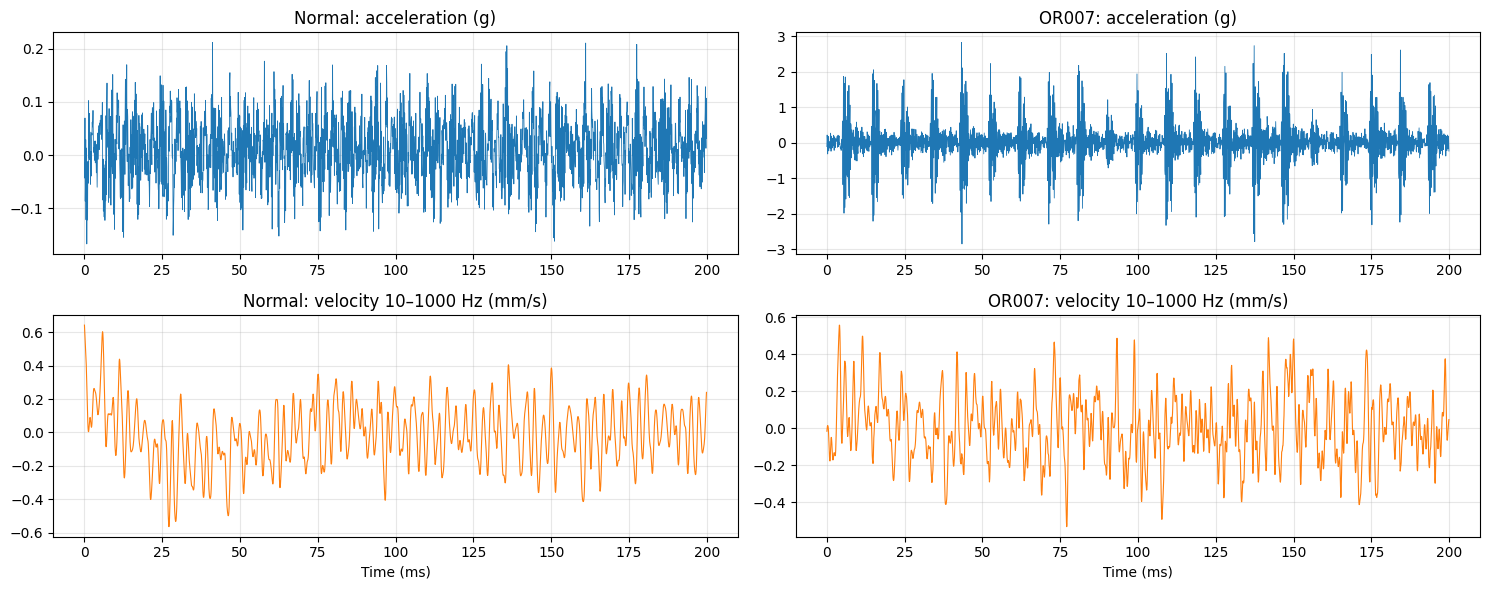

In [43]:
def accel_to_velocity(acc, fs=FS, band=ISO_BAND, order=FILTER_ORDER, to_ms2=ACCEL_TO_MS2):
    '''Acceleration (in g) -> velocity (mm/s) by frequency-domain integration with zero-phase band limiting.
    band = (f_low, f_high); f_high = None means high-pass only (up to Nyquist).'''
    a = (np.asarray(acc, dtype=np.float64) - np.mean(acc)) * to_ms2
    n = len(a)
    A = np.fft.rfft(a)
    f = np.fft.rfftfreq(n, d=1 / fs)
    V = np.zeros_like(A)
    nz = f > 0
    f_lo, f_hi = band
    H = 1.0 / np.sqrt(1.0 + (f_lo / f[nz]) ** (2 * order))              # high-pass (removes drift)
    if f_hi is not None:
        H = H / np.sqrt(1.0 + (f[nz] / f_hi) ** (2 * order))            # low-pass (ISO band)
    V[nz] = A[nz] * H / (1j * 2 * np.pi * f[nz])
    return np.fft.irfft(V, n) * 1000.0                                   # m/s -> mm/s

def accel_to_velocity_time_domain(acc, fs=FS, band=ISO_BAND, order=FILTER_ORDER, to_ms2=ACCEL_TO_MS2):
    '''Independent check: band-pass -> trapezoidal integration -> band-pass again (drift removal).'''
    sos = butter(order // 2, band, btype="bandpass", fs=fs, output="sos")   # filtfilt doubles the order
    a = sosfiltfilt(sos, (np.asarray(acc, dtype=np.float64) - np.mean(acc)) * to_ms2)
    v = cumulative_trapezoid(a, dx=1 / fs, initial=0.0)
    return sosfiltfilt(sos, v - v.mean()) * 1000.0

rms = lambda x: float(np.sqrt(np.mean(np.square(x))))

# (i) Validation with pure sine waves: a(t) = A_g * sin(2*pi*f*t)  ->  v_rms = A_g*9.80665 / (2*pi*f*sqrt(2))
t_val = np.arange(10 * FS) / FS
val_rows = []
for f0 in [30.0, 100.0, 160.0, 300.0]:
    a_g = 0.1 * np.sin(2 * np.pi * f0 * t_val)
    v_expected = 0.1 * ACCEL_TO_MS2 / (2 * np.pi * f0 * np.sqrt(2)) * 1000
    v_fd = rms(accel_to_velocity(a_g)[FS:-FS])                 # skip 1 s at each edge
    v_td = rms(accel_to_velocity_time_domain(a_g)[FS:-FS])
    val_rows.append({"f (Hz)": f0, "expected mm/s": v_expected, "frequency-domain": v_fd,
                     "time-domain": v_td, "FD error %": 100 * (v_fd / v_expected - 1)})
val_df = pd.DataFrame(val_rows).set_index("f (Hz)")
display(val_df.round(4))
assert (val_df["FD error %"].abs() < 1.0).all(), "Integration check failed (> 1% error on a pure sine)."
print("Sine-wave validation passed (< 1% error inside the pass band).")

# (ii) Cross-check the two methods on the real Normal signal
v_norm_fd = accel_to_velocity(raw_signals["Normal"])
v_norm_td = accel_to_velocity_time_domain(raw_signals["Normal"])
inner = slice(FS, -FS)
ratio = rms(v_norm_fd[inner]) / rms(v_norm_td[inner])
print(f"Normal 1 hp velocity RMS: frequency-domain {rms(v_norm_fd[inner]):.4f} mm/s, "
      f"time-domain {rms(v_norm_td[inner]):.4f} mm/s (ratio {ratio:.3f})")

# Velocity signals for all 1 hp recordings (known + unseen)
vel_1hp = {label: accel_to_velocity(x) for label, x in raw_signals.items()}

fig, ax = plt.subplots(2, 2, figsize=(15, 6))
n_show = int(0.2 * FS); tt = np.arange(n_show) / FS * 1000
for col, label in enumerate(["Normal", "OR007"]):
    ax[0, col].plot(tt, raw_signals[label][:n_show], lw=0.6)
    ax[0, col].set_title(f"{label}: acceleration (g)")
    ax[1, col].plot(tt, vel_1hp[label][:n_show], lw=0.8, color="tab:orange")
    ax[1, col].set_title(f"{label}: velocity 10–1000 Hz (mm/s)"); ax[1, col].set_xlabel("Time (ms)")
for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout(); savefig("C28a_accel_to_velocity"); plt.show()

### 28b — RMS velocity per fault class (1 hp)

Velocity RMS is computed for the whole recording and for **1-second segments** (to show the spread). For comparison, a second column uses the wide band 10 Hz – Nyquist, which includes the high-frequency bearing-impact energy that the ISO band excludes.

**Expectation:** an increasing trend Normal → 007 → 014 → 021 within each fault family. This is **not guaranteed**: seeded bearing faults mainly produce high-frequency impacts (several kHz), while ISO velocity is dominated by low-frequency content (1× running speed, structural response). Any deviation from the expected trend is reported, not hidden.

,set,family,accel_rms_g,v_rms_iso,seg_mean,seg_std,seg_min,seg_max,n_segments,v_rms_wideband
class,,,,,,,,,,
Normal,known,Normal,0.0616,0.1778,0.1766,0.0025,0.1727,0.1801,10,0.1800
IR007,known,Inner race,0.2929,0.2090,0.2090,0.0027,0.2040,0.2123,10,0.2788
IR014,known,Inner race,0.1655,0.1383,0.1379,0.0067,0.1299,0.1486,10,0.1617
IR021,unseen,Inner race,0.4418,0.2908,0.2907,0.0072,0.2802,0.3031,10,0.3753
OR007,known,Outer race,0.5919,0.1683,0.1684,0.0041,0.1608,0.1738,10,0.3367
OR014,known,Outer race,0.0936,0.1428,0.1426,0.0013,0.1407,0.1450,10,0.1495
B007,known,Ball,0.1391,0.1402,0.1398,0.0097,0.1232,0.1515,10,0.1571
B014,known,Ball,0.1409,0.2144,0.2143,0.0010,0.2129,0.2162,10,0.2258
B021,unseen,Ball,0.1291,0.1396,0.1394,0.0068,0.1305,0.1526,10,0.1540


Trend check (ISO-band velocity RMS):


,classes,values (mm/s),all above Normal,monotonic increase
family,,,,
Inner race,IR007 → IR014 → IR021,0.209 → 0.138 → 0.291,False,False
Outer race,OR007 → OR014,0.168 → 0.143,False,False
Ball,B007 → B014 → B021,0.140 → 0.214 → 0.140,False,False


NOTE: the expected Normal → 007 → 014 → 021 trend does NOT hold everywhere. Report this: ISO-band velocity measures overall machine vibration severity, not bearing-fault size.


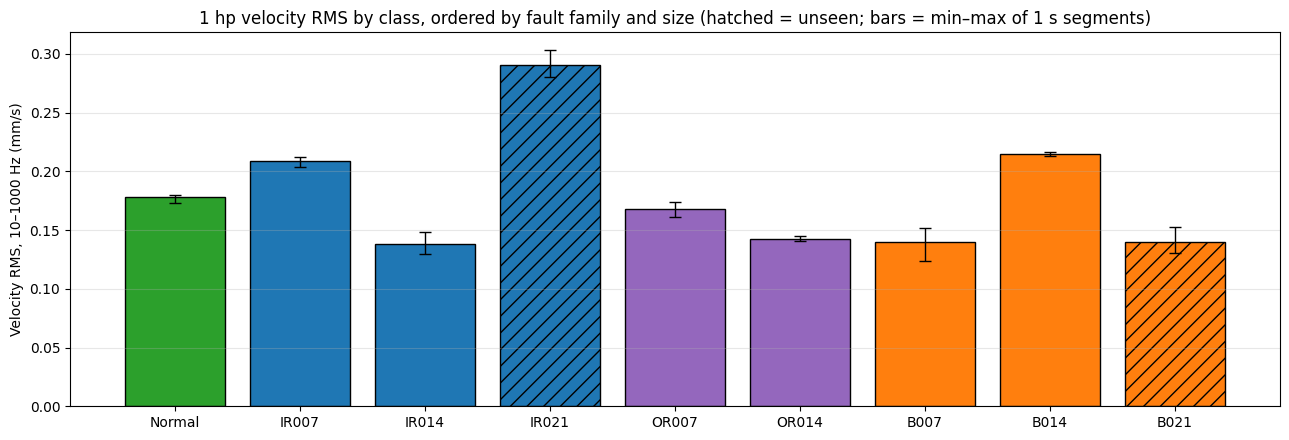

In [44]:
SEVERITY_ORDER = ["Normal", "IR007", "IR014", "IR021", "OR007", "OR014", "B007", "B014", "B021"]
FAMILY = {"Normal": "Normal", "IR007": "Inner race", "IR014": "Inner race", "IR021": "Inner race",
          "OR007": "Outer race", "OR014": "Outer race", "B007": "Ball", "B014": "Ball", "B021": "Ball"}
FAMILY_COLOR = {"Normal": "tab:green", "Inner race": "tab:blue", "Outer race": "tab:purple", "Ball": "tab:orange"}

def segment_rms(v, seg_s=SEGMENT_S, fs=FS):
    L = int(seg_s * fs)
    n = len(v) // L
    return np.sqrt(np.mean(v[: n * L].reshape(n, L) ** 2, axis=1))

def velocity_table(raw_dict, vel_dict, set_of):
    rows = []
    for label in [c for c in SEVERITY_ORDER if c in raw_dict]:
        v = vel_dict[label]
        seg = segment_rms(v)
        v_wide = accel_to_velocity(raw_dict[label], band=(ISO_BAND[0], None))
        rows.append({"class": label, "set": set_of(label), "family": FAMILY[label],
                     "accel_rms_g": rms(raw_dict[label]),
                     "v_rms_iso": rms(v), "seg_mean": seg.mean(), "seg_std": seg.std(),
                     "seg_min": seg.min(), "seg_max": seg.max(), "n_segments": len(seg),
                     "v_rms_wideband": rms(v_wide)})
    return pd.DataFrame(rows).set_index("class")

set_1hp = lambda c: "unseen" if c in UNSEEN_CLASSES else "known"
vel_df_1hp = velocity_table(raw_signals, vel_1hp, set_1hp)
display(vel_df_1hp.round(4))
vel_df_1hp.to_csv(ART_DIR / "phaseC_velocity_rms_1hp.csv")

# Trend check within each family
print("Trend check (ISO-band velocity RMS):")
trend_rows = []
v_normal = vel_df_1hp.loc["Normal", "v_rms_iso"]
for fam, members in [("Inner race", ["IR007", "IR014", "IR021"]),
                     ("Outer race", ["OR007", "OR014"]),
                     ("Ball", ["B007", "B014", "B021"])]:
    vals = vel_df_1hp.loc[members, "v_rms_iso"].values
    above_normal = bool(np.all(vals > v_normal))
    increasing = bool(np.all(np.diff(vals) > 0))
    trend_rows.append({"family": fam, "classes": " → ".join(members),
                       "values (mm/s)": " → ".join(f"{x:.3f}" for x in vals),
                       "all above Normal": above_normal, "monotonic increase": increasing})
trend_df = pd.DataFrame(trend_rows).set_index("family")
display(trend_df)
if not trend_df["monotonic increase"].all() or not trend_df["all above Normal"].all():
    print("NOTE: the expected Normal → 007 → 014 → 021 trend does NOT hold everywhere. Report this: ISO-band "
          "velocity measures overall machine vibration severity, not bearing-fault size.")
else:
    print("The expected increasing severity trend holds for all families.")

fig, ax = plt.subplots(figsize=(13, 4.5))
xs = np.arange(len(vel_df_1hp))
for i, (label, r) in enumerate(vel_df_1hp.iterrows()):
    ax.bar(i, r["v_rms_iso"], color=FAMILY_COLOR[r["family"]], edgecolor="k",
           hatch="//" if r["set"] == "unseen" else None)
    ax.errorbar(i, r["v_rms_iso"], yerr=[[r["v_rms_iso"] - r["seg_min"]], [r["seg_max"] - r["v_rms_iso"]]],
                color="k", capsize=4, lw=1)
ax.set_xticks(xs, vel_df_1hp.index)
ax.set_ylabel("Velocity RMS, 10–1000 Hz (mm/s)")
ax.set_title("1 hp velocity RMS by class, ordered by fault family and size (hatched = unseen; bars = min–max of 1 s segments)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); savefig("C28b_velocity_rms_by_class"); plt.show()

### 28c — Machine class and ISO zone boundaries

**The CWRU test rig:** 2 hp (≈ 1.5 kW) Reliance Electric induction motor, ~1772 rpm at 1 hp load; accelerometers magnetically mounted on the motor housing at 12 o'clock at the drive end.

**Correction to the roadmap.** In ISO 10816-3 (now ISO 20816-3), **Group 1 = large machines above 300 kW** and **Group 2 = medium machines 15–300 kW**. The standard applies only to machines **above 15 kW**, so the CWRU motor lies **outside its scope**. The values 2.3 / 4.5 / 7.1 mm/s used in the roadmap are the boundaries for *Group 1 rigid* or *Group 2 flexible* supports, not for a 15–75 kW machine.

**Chosen reference:** ISO 10816-1 (general guidelines), whose Annex B (Amendment 1:2009, Table B.1) notes that small machines such as **electric motors up to 15 kW** lie at the lower end of the typical boundary range, i.e. the classic **Class I** values:

| Zone | Class I boundary (mm/s RMS) | Meaning |
|---|---|---|
| A | < 0.71 | newly commissioned / excellent |
| B | 0.71 – 1.8 | acceptable for long-term operation |
| C | 1.8 – 4.5 | unsuitable for long-term operation, action required |
| D | ≥ 4.5 | dangerous, immediate action |

ISO 10816-1 has itself been superseded by ISO 20816-1:2016, so these values are used as **engineering reference values**, not as a certified acceptance criterion. The other presets are kept for comparison (Step 28d) and can be selected with `ZONE_PRESET`.

In [45]:
ZONE_PRESETS = {                                   # (A/B, B/C, C/D) in mm/s RMS
    "ISO 10816-1 Class I (<=15 kW)":                (0.71, 1.8, 4.5),
    "ISO 10816-3 Group 2 rigid (15-300 kW)":        (1.4, 2.8, 4.5),
    "ISO 10816-3 Group 1 rigid / Group 2 flexible": (2.3, 4.5, 7.1),    # values used in the roadmap
    "ISO 10816-3 Group 1 flexible (>300 kW)":       (3.5, 7.1, 11.0),
}
ZONE_PRESET = "ISO 10816-1 Class I (<=15 kW)"     # primary choice (see markdown above)

def iso_zone(v, bounds):
    ab, bc, cd = bounds
    v = np.asarray(v, dtype=float)
    z = np.select([v < ab, v < bc, v < cd], ["A", "B", "C"], default="D")
    return z.item() if z.ndim == 0 else z

print("Zone boundary presets (A/B, B/C, C/D):")
for name, b in ZONE_PRESETS.items():
    print(f"  {'->' if name == ZONE_PRESET else '  '} {name:<46} {b}")

Zone boundary presets (A/B, B/C, C/D):
  -> ISO 10816-1 Class I (<=15 kW)                  (0.71, 1.8, 4.5)
     ISO 10816-3 Group 2 rigid (15-300 kW)          (1.4, 2.8, 4.5)
     ISO 10816-3 Group 1 rigid / Group 2 flexible   (2.3, 4.5, 7.1)
     ISO 10816-3 Group 1 flexible (>300 kW)         (3.5, 7.1, 11.0)


### 28d — Map the real 1 hp data onto the ISO zones

Whole-recording velocity RMS and the share of 1-second segments in each zone. The mismatch check is automatic. If the small rig does not align with the chosen boundaries, an **optional, documented scaling** is available:

- `SCALING_MODE = "none"` (default): use the ISO boundaries unchanged.
- `SCALING_MODE = "anchor_normal"`: multiply all three boundaries by $s = v_{\text{Normal, p95}} / v_{A/B}$. This places the healthy machine's 95th-percentile level exactly at the top of Zone A (the ISO meaning of "newly commissioned"), while keeping ISO's boundary **ratios**. Use it only if the unscaled mapping is clearly inconsistent, and state it in the report.

Zone of each class (whole-recording RMS) under every preset:


,v_rms_iso (mm/s),ISO 10816-1 Class I (<=15 kW),ISO 10816-3 Group 2 rigid (15-300 kW),ISO 10816-3 Group 1 rigid / Group 2 flexible,ISO 10816-3 Group 1 flexible (>300 kW)
class,,,,,
Normal,0.178,A,A,A,A
IR007,0.209,A,A,A,A
IR014,0.138,A,A,A,A
IR021,0.291,A,A,A,A
OR007,0.168,A,A,A,A
OR014,0.143,A,A,A,A
B007,0.140,A,A,A,A
B014,0.214,A,A,A,A
B021,0.140,A,A,A,A



Preset: ISO 10816-1 Class I (<=15 kW)   scaling mode: none   scale factor: 1.000
Boundaries used in Phase C: A/B = 0.710, B/C = 1.800, C/D = 4.500 mm/s


,zone (whole),A,B,C,D
Normal,A,100%,0%,0%,0%
IR007,A,100%,0%,0%,0%
IR014,A,100%,0%,0%,0%
IR021,A,100%,0%,0%,0%
OR007,A,100%,0%,0%,0%
OR014,A,100%,0%,0%,0%
B007,A,100%,0%,0%,0%
B014,A,100%,0%,0%,0%
B021,A,100%,0%,0%,0%



Mismatch check:
  - No fault class reaches Zone C or D -> the physics layer would never reduce capacity on this data.
  Option: SCALING_MODE='anchor_normal' would use scale 0.254 -> boundaries (0.18, 0.456, 1.141); zones would be: Normal:A, IR007:B, IR014:A, IR021:B, OR007:A, OR014:A, B007:A, B014:B, B021:A


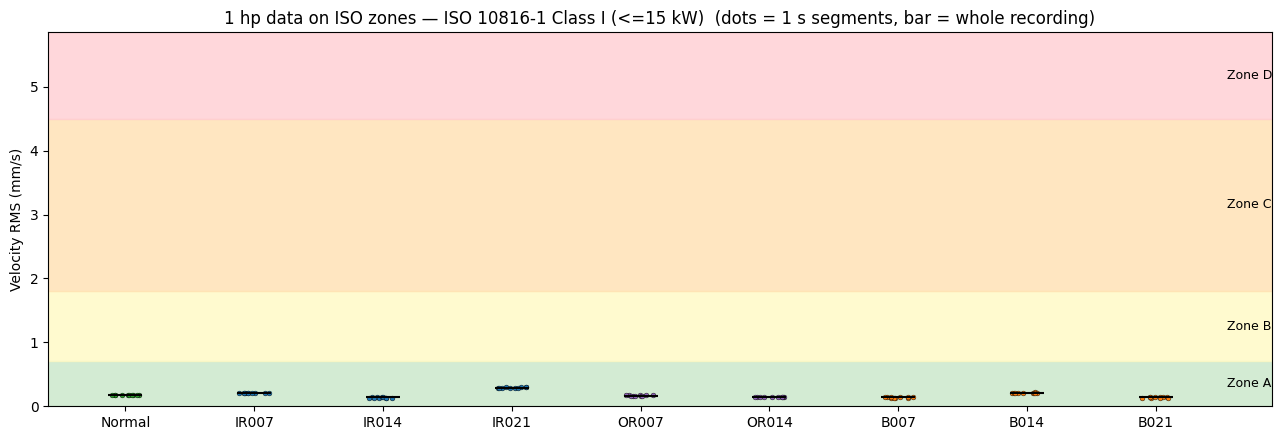

In [46]:
SCALING_MODE = "none"          # "none" or "anchor_normal"

seg_1hp = {c: segment_rms(vel_1hp[c]) for c in SEVERITY_ORDER}

# Whole-signal zone for every preset
zone_all = pd.DataFrame({name: iso_zone(vel_df_1hp["v_rms_iso"].values, b) for name, b in ZONE_PRESETS.items()},
                        index=vel_df_1hp.index)
zone_all.insert(0, "v_rms_iso (mm/s)", vel_df_1hp["v_rms_iso"].round(3))
print("Zone of each class (whole-recording RMS) under every preset:")
display(zone_all)

# Scaling
base_bounds = ZONE_PRESETS[ZONE_PRESET]
normal_p95 = float(np.quantile(seg_1hp["Normal"], 0.95))
scale = normal_p95 / base_bounds[0] if SCALING_MODE == "anchor_normal" else 1.0
V_AB, V_BC, V_CD = (b * scale for b in base_bounds)
BOUNDS = (V_AB, V_BC, V_CD)
print(f"\nPreset: {ZONE_PRESET}   scaling mode: {SCALING_MODE}   scale factor: {scale:.3f}")
print(f"Boundaries used in Phase C: A/B = {V_AB:.3f}, B/C = {V_BC:.3f}, C/D = {V_CD:.3f} mm/s")

# Share of 1 s segments per zone (primary boundaries)
share = pd.DataFrame({c: pd.Series(iso_zone(seg_1hp[c], BOUNDS)).value_counts(normalize=True)
                      .reindex(list("ABCD"), fill_value=0.0) for c in SEVERITY_ORDER}).T
share.insert(0, "zone (whole)", iso_zone(vel_df_1hp["v_rms_iso"].values, BOUNDS))
display(share.style.format({z: "{:.0%}" for z in "ABCD"}))

# Automatic mismatch report
issues = []
z_norm = share.loc["Normal", "zone (whole)"]
if z_norm not in ("A", "B"):
    issues.append(f"Normal is in Zone {z_norm} (expected A or B) -> boundaries are too strict for this rig.")
faults = [c for c in SEVERITY_ORDER if c != "Normal"]
n_CD = int(np.isin(share.loc[faults, "zone (whole)"], ["C", "D"]).sum())
if n_CD == 0:
    issues.append("No fault class reaches Zone C or D -> the physics layer would never reduce capacity on this data.")
alt = {c: iso_zone(vel_df_1hp.loc[c, 'v_rms_iso'], BOUNDS) for c in faults}
print("\nMismatch check:")
if issues:
    for s in issues: print("  -", s)
    alt_scale = normal_p95 / base_bounds[0]
    alt_b = tuple(b * alt_scale for b in base_bounds)
    print(f"  Option: SCALING_MODE='anchor_normal' would use scale {alt_scale:.3f} -> boundaries "
          f"{tuple(round(b, 3) for b in alt_b)}; zones would be: "
          + ", ".join(f"{c}:{iso_zone(vel_df_1hp.loc[c, 'v_rms_iso'], alt_b)}" for c in SEVERITY_ORDER))
else:
    print(f"  No major mismatch: Normal in Zone {z_norm}; {n_CD} of {len(faults)} fault classes reach Zone C/D.")

fig, ax = plt.subplots(figsize=(13, 4.5))
top = max(V_CD * 1.3, vel_df_1hp["seg_max"].max() * 1.1)
for lo, hi, z, col in [(0, V_AB, "A", "#c8e6c9"), (V_AB, V_BC, "B", "#fff9c4"),
                       (V_BC, V_CD, "C", "#ffe0b2"), (V_CD, top, "D", "#ffcdd2")]:
    ax.axhspan(lo, hi, color=col, alpha=0.8, zorder=0)
    ax.text(len(SEVERITY_ORDER) - 0.45, (lo + min(hi, top)) / 2, f"Zone {z}", va="center", fontsize=9)
for i, c in enumerate(SEVERITY_ORDER):
    ax.scatter(np.full(len(seg_1hp[c]), i) + np.random.uniform(-0.12, 0.12, len(seg_1hp[c])), seg_1hp[c],
               s=12, color=FAMILY_COLOR[FAMILY[c]], edgecolor="k", lw=0.3, zorder=3)
    ax.scatter(i, vel_df_1hp.loc[c, "v_rms_iso"], marker="_", s=600, color="k", zorder=4)
ax.set_xticks(range(len(SEVERITY_ORDER)), SEVERITY_ORDER); ax.set_xlim(-0.6, len(SEVERITY_ORDER) - 0.1)
ax.set_ylim(0, top); ax.set_ylabel("Velocity RMS (mm/s)")
ax.set_title(f"1 hp data on ISO zones — {ZONE_PRESET}" + (f" (scaled ×{scale:.2f})" if scale != 1 else "")
             + "  (dots = 1 s segments, bar = whole recording)")
plt.tight_layout(); savefig("C28d_iso_zone_mapping"); plt.show()

## Step 29 — Rule structure: "fail safely, not badly"

### 29a — Rule structure

| Condition | Action | Justification |
|---|---|---|
| Zone A/B (v < B/C boundary) | Keep full capacity | Nominal operation |
| Zone C (B/C ≤ v < C/D) | Reduce capacity **proportionally** to vibration | Smooth correction near a safety boundary (CBF-inspired); graceful degradation |
| Zone D (v ≥ C/D) | **Full stop**, regardless of model confidence | Hard override at the true danger boundary; matches alarm/trip practice |

**How it combines with the neural network (Simplex / runtime assurance):**

1. **Zone D override, always active:** if $v \ge v_{C/D}$ → capacity 0, whatever the network says.
2. **Network trusted** (mean logit margin over the last K windows ≥ τ): the network stays in control. Its diagnosis is reported for maintenance and the machine runs at full capacity.
3. **Network not trusted** (margin < τ): the **physics controller takes over** and sets capacity = capacity(v).

### 29b — The rule as a continuous function

$$
\text{capacity}(v) =
\begin{cases}
1 & v < v_{B/C} \\[4pt]
1 - \dfrac{v - v_{B/C}}{v_{C/D} - v_{B/C}} & v_{B/C} \le v < v_{C/D} \\[10pt]
0 & v \ge v_{C/D}
\end{cases}
$$

Capacity is continuous and non-increasing. It stays at 1 while the machine is in a recoverable zone, falls linearly through Zone C, and reaches exactly 0 at the Zone D boundary. No percentage is chosen by hand; both breakpoints come from the ISO boundaries of Step 28.

**Theoretical grounding (and its limits):**
- **Control Barrier Functions** (Ames et al., 2017; 2019) formalize the difference between smooth correction as a system approaches a safe-set boundary and intervention at the boundary. The linear rule is **CBF-inspired**, not a formal CBF: there is no dynamic model of the machine, and no forward-invariance proof. State it this way in the report.
- **Graceful degradation** (e.g. Shelton & Koopman, 2003): under partial failure the system continues at reduced, *deliberate and visible* capacity instead of stopping completely.
- **Simplex architecture / runtime assurance** (Seto et al., 1998; Sha, 2001): an unverified high-performance controller hands control to a simple verified-safe controller when it cannot be trusted. This is why the fallback uses physics only and is independent of the network.
- **Industrial practice:** ISO 20816-3 describes alarm limits relative to the baseline and trip limits tied to the C/D boundary. This supports the "warn/reduce, then stop" shape; the numbers come from our own data mapping.

*References:* A. D. Ames, X. Xu, J. W. Grizzle, P. Tabuada, "Control barrier function based quadratic programs for safety critical systems," *IEEE TAC*, 62(8), 2017. A. D. Ames et al., "Control barrier functions: theory and applications," *European Control Conference*, 2019. C. Shelton, P. Koopman, "Using architectural properties to model and measure graceful degradation," *Architecting Dependable Systems*, LNCS 2677, 2003. D. Seto, B. Krogh, L. Sha, A. Chutinan, "The Simplex architecture for safe online control system upgrades," *American Control Conference*, 1998. L. Sha, "Using simplicity to control complexity," *IEEE Software*, 18(4), 2001.

### How the policies are evaluated

Each **decision step** covers K = 5 consecutive windows of one recording, in time order. At each step we know:
- the mean logit margin (trusted or not),
- the network's majority prediction and whether it is correct (unseen classes are always wrong, because the network has no output for them),
- the velocity RMS over the last 1 s of signal.

**Final design.** Two graceful variants are compared. The *Simplex switch* hands capacity control to the physics rule only when the network is not trusted. The fault-injection sweep (31c) showed that this lets a trusted prediction keep full capacity through Zone C and then drop from 1 to 0 at the C/D boundary, an abrupt change the rule was meant to avoid. The **final design keeps the physics envelope active at all times**: capacity = capacity(v); the network provides the diagnosis; the logit-margin trigger marks untrusted diagnoses as *unknown condition — inspect*. On the real CWRU data both variants give identical results.

Four policies are compared:

| Policy | Capacity |
|---|---|
| NN only (no fallback) | always 1 |
| Hard stop on uncertainty | 0 if not trusted or in Zone D, else 1 |
| Graceful (Simplex switch) | 0 in Zone D; capacity(v) if not trusted; 1 if trusted |
| **Graceful + physics envelope (final)** | capacity(v) always (0 from Zone D); the network gives the diagnosis, and the trigger flags untrusted diagnoses |

Metrics (safety truth = the ISO C/D boundary of Step 28d):
- **Unsafe operation:** running (capacity > 0) while truly in Zone D.
- **Silent failure:** the system trusts a wrong diagnosis and keeps running at full capacity with no fallback.
- **Unnecessary stop:** capacity 0 while not in Zone D.
- **Downtime:** share of steps at capacity 0.
- **Availability:** mean capacity.
- **False fallback:** fallback activated although the network was correct.
- **Safe operation:** no unsafe operation and no silent failure.

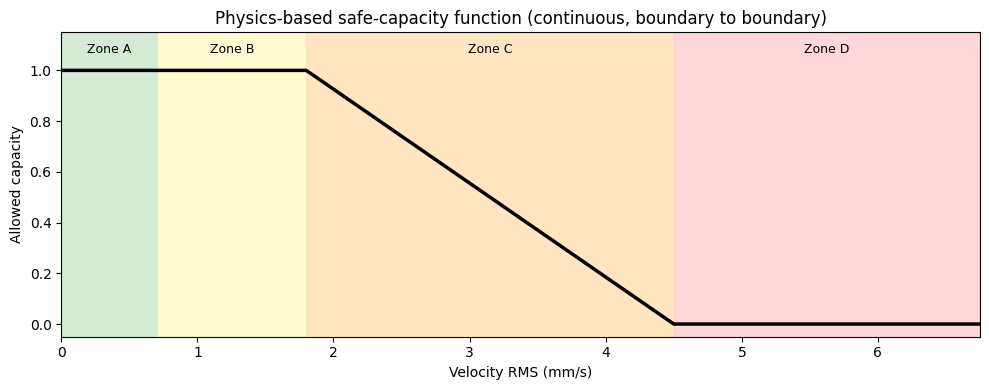

In [47]:
def capacity_fn(v, v_bc, v_cd):
    '''Formal rule of 29b (vectorized): 1 below B/C, linear decay through Zone C, 0 from C/D on.'''
    v = np.asarray(v, dtype=float)
    return np.clip(1.0 - (v - v_bc) / (v_cd - v_bc), 0.0, 1.0)

vv = np.linspace(0, V_CD * 1.5, 1000)
fig, ax = plt.subplots(figsize=(10, 4))
for lo, hi, z, col in [(0, V_AB, "A", "#c8e6c9"), (V_AB, V_BC, "B", "#fff9c4"),
                       (V_BC, V_CD, "C", "#ffe0b2"), (V_CD, vv[-1], "D", "#ffcdd2")]:
    ax.axvspan(lo, hi, color=col, alpha=0.8, zorder=0)
    ax.text((lo + hi) / 2, 1.07, f"Zone {z}", ha="center", fontsize=9)
ax.plot(vv, capacity_fn(vv, V_BC, V_CD), lw=2.5, color="k")
ax.set_ylim(-0.05, 1.15); ax.set_xlim(0, vv[-1])
ax.set_xlabel("Velocity RMS (mm/s)"); ax.set_ylabel("Allowed capacity")
ax.set_title("Physics-based safe-capacity function (continuous, boundary to boundary)")
plt.tight_layout(); savefig("C29b_capacity_function"); plt.show()

In [48]:
# ---- Build time-ordered decision steps (used by 29c and 31b) ----
def windows_and_starts(x):
    return make_windows(zscore(x))

def build_steps(group, classes, X_by_class, starts_by_class, vel_by_class, known):
    L = int(PHYS_WINDOW_S * FS)
    rows = []
    for c in classes:
        Xc, s, vel = X_by_class[c], starts_by_class[c], vel_by_class[c]
        z = get_logits(Xc)
        m = logit_margin(z)
        p = z.argmax(axis=1)
        csum = np.concatenate([[0.0], np.cumsum(vel ** 2)])
        for i in range(PHASE_C_K - 1, len(Xc)):
            lo = i - PHASE_C_K + 1
            e = int(s[i] + WINDOW_SIZE)
            b = max(0, e - L)
            pred_c = ID_TO_CLASS[int(np.bincount(p[lo:i + 1], minlength=NUM_CLASSES).argmax())]
            rows.append({"group": group, "cls": c, "step": i, "end_sample": e,
                         "margin_mean": float(m[lo:i + 1].mean()), "pred": pred_c,
                         "nn_correct": bool(known and pred_c == c),
                         "v_rms": float(np.sqrt((csum[e] - csum[b]) / (e - b)))})
    return pd.DataFrame(rows)

test_starts = starts_known[test_mask]
X_test_by_c = {c: X_test[y_test == c] for c in KNOWN_CLASSES}
S_test_by_c = {c: test_starts[y_test == c] for c in KNOWN_CLASSES}
for c in KNOWN_CLASSES:
    assert np.all(np.diff(S_test_by_c[c]) > 0), "test windows must be in time order"

X_uns_by_c = {c: windowed[c]["X"] for c in UNSEEN_CLASSES}
S_uns_by_c = {c: windowed[c]["starts"] for c in UNSEEN_CLASSES}

steps_1hp = pd.concat([
    build_steps("Known 1hp (test)", KNOWN_CLASSES, X_test_by_c, S_test_by_c, vel_1hp, known=True),
    build_steps("Unseen 1hp", UNSEEN_CLASSES, X_uns_by_c, S_uns_by_c, vel_1hp, known=False),
], ignore_index=True)
steps_1hp["zone"] = iso_zone(steps_1hp["v_rms"], BOUNDS)
print(steps_1hp.groupby("group").agg(steps=("step", "size"),
                                     trusted=("margin_mean", lambda m: np.mean(m >= TAU_C)),
                                     nn_correct=("nn_correct", "mean"),
                                     v_mean=("v_rms", "mean")).round(3))
print("\nZone of decision steps:")
display(pd.crosstab(steps_1hp["cls"], steps_1hp["zone"]).reindex(
    [c for c in SEVERITY_ORDER if c in steps_1hp["cls"].unique()]))

POLICIES = ["NN only (no fallback)", "Hard stop on uncertainty", "Graceful (Simplex switch)", "Graceful + physics envelope (final)"]

def policy_capacities(steps, v_bc, v_cd, tau=TAU_C):
    v = steps["v_rms"].to_numpy()
    trusted = steps["margin_mean"].to_numpy() >= tau
    phys = capacity_fn(v, v_bc, v_cd)
    zone_d = v >= v_cd
    caps = {
        "NN only (no fallback)":    np.ones_like(v),
        "Hard stop on uncertainty": np.where(~trusted | zone_d, 0.0, 1.0),
        "Graceful (Simplex switch)":      np.where(zone_d, 0.0, np.where(trusted, 1.0, phys)),
        "Graceful + physics envelope (final)":     phys,
    }
    fallback = {"NN only (no fallback)": np.zeros_like(trusted), "Hard stop on uncertainty": ~trusted,
                "Graceful (Simplex switch)": ~trusted, "Graceful + physics envelope (final)": ~trusted}
    return caps, fallback

def policy_metrics(steps, caps, fallback, v_cd_true=V_CD):
    v = steps["v_rms"].to_numpy()
    truly_d = v >= v_cd_true
    nn_wrong = ~steps["nn_correct"].to_numpy()
    out = {}
    for name, cap in caps.items():
        fb = fallback[name]
        unsafe = (cap > 0) & truly_d
        silent = (nn_wrong & ~fb & (cap >= 1.0)) if fb is not None else np.zeros_like(unsafe)
        out[name] = {
            "availability": cap.mean(),
            "downtime": np.mean(cap == 0),
            "unsafe_operation": unsafe.mean(),
            "unnecessary_stop": np.mean((cap == 0) & ~truly_d),
            "silent_failure": silent.mean() if fb is not None else np.nan,
            "false_fallback": np.mean(fb & ~nn_wrong) if fb is not None else np.nan,
            "safe_operation": np.mean(~unsafe & ~silent),
        }
    return pd.DataFrame(out).T

def evaluate(steps, v_bc=V_BC, v_cd=V_CD, v_cd_true=V_CD, by_group=True):
    frames = []
    groups = list(steps["group"].unique()) if by_group else []
    for g in groups + ["All"]:
        s = steps if g == "All" else steps[steps["group"] == g]
        caps, fb = policy_capacities(s, v_bc, v_cd)
        m = policy_metrics(s, caps, fb, v_cd_true)
        m.insert(0, "group", g)
        frames.append(m)
    return pd.concat(frames).rename_axis("policy").reset_index().set_index(["group", "policy"])

PCT = lambda df: df.style.format("{:.1%}", na_rep="—")

                  steps  trusted  nn_correct  v_mean
group                                               
Known 1hp (test)    292    0.997         1.0   0.170
Unseen 1hp          464    0.000         0.0   0.215

Zone of decision steps:


zone,A
cls,
Normal,41
IR007,42
IR014,41
IR021,232
OR007,42
OR014,42
B007,42
B014,42
B021,232


### 29c — Nominal comparison and sensitivity analysis (1 hp)

First, the four policies at the nominal boundaries. Then the controller's two parameters ($v_{B/C}$, $v_{C/D}$) are varied independently by **±20%** (5 × 5 grid). The **safety truth stays at the nominal ISO boundary**, because the boundaries are design parameters of the controller, not a change of the physical danger limit.

Nominal boundaries — 1 hp:


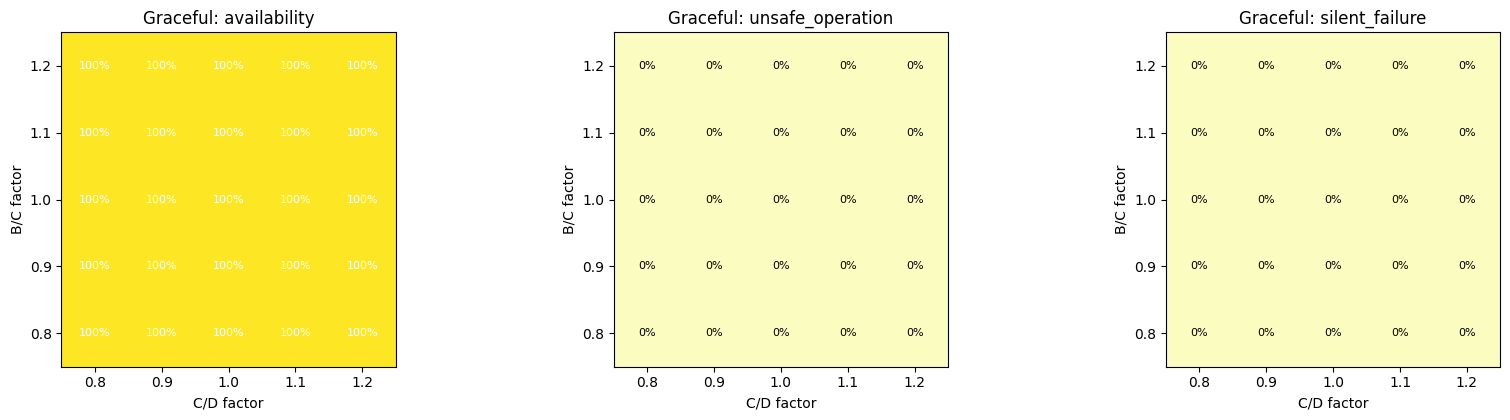

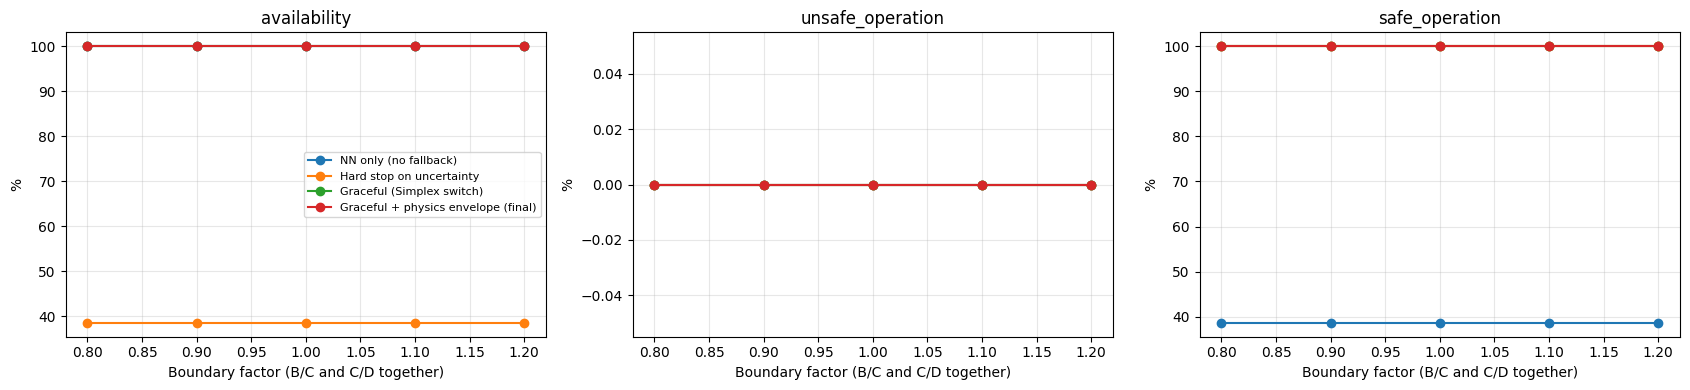

Share of the sensitivity grid where each statement holds:


,share of grid
graceful availability >= hard stop,100%
graceful safe_operation >= NN only,100%
graceful silent failures <= NN only,100%
graceful unsafe = 0,100%


In [49]:
nominal_1hp = evaluate(steps_1hp)
print("Nominal boundaries — 1 hp:")
display(PCT(nominal_1hp))
nominal_1hp.to_csv(ART_DIR / "phaseC_policy_comparison_1hp.csv")

FACTORS = [0.8, 0.9, 1.0, 1.1, 1.2]
sens_rows = []
for fb_ in FACTORS:
    for fd_ in FACTORS:
        v_bc, v_cd = V_BC * fb_, V_CD * fd_
        if v_bc >= v_cd:
            continue
        caps, fbk = policy_capacities(steps_1hp, v_bc, v_cd)
        m = policy_metrics(steps_1hp, caps, fbk, v_cd_true=V_CD)
        for pol, r in m.iterrows():
            sens_rows.append({"f_BC": fb_, "f_CD": fd_, "policy": pol, **r.to_dict()})
sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(ART_DIR / "phaseC_sensitivity_1hp.csv", index=False)

# Heatmaps for the proposed policy
g = sens_df[sens_df.policy == "Graceful (Simplex switch)"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for a, metric in zip(ax, ["availability", "unsafe_operation", "silent_failure"]):
    piv = g.pivot(index="f_BC", columns="f_CD", values=metric)
    im = a.imshow(piv.values, cmap="viridis" if metric == "availability" else "magma_r", vmin=0, vmax=1, origin="lower")
    a.set_xticks(range(len(piv.columns)), [f"{c:.1f}" for c in piv.columns])
    a.set_yticks(range(len(piv.index)), [f"{i:.1f}" for i in piv.index])
    for (i, j), val in np.ndenumerate(piv.values):
        if not np.isnan(val):
            a.text(j, i, f"{val:.0%}", ha="center", va="center", color="w" if metric == "availability" else "k", fontsize=8)
    a.set_xlabel("C/D factor"); a.set_ylabel("B/C factor"); a.set_title(f"Graceful: {metric}")
plt.tight_layout(); savefig("C29c_sensitivity_heatmaps"); plt.show()

# Joint scaling of both boundaries: all policies
joint = sens_df[sens_df.f_BC == sens_df.f_CD]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, metric in zip(ax, ["availability", "unsafe_operation", "safe_operation"]):
    for pol in POLICIES:
        d = joint[joint.policy == pol]
        a.plot(d.f_BC, 100 * d[metric], "o-", label=pol)
    a.set_xlabel("Boundary factor (B/C and C/D together)"); a.set_ylabel("%"); a.set_title(metric); a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); savefig("C29c_sensitivity_joint"); plt.show()

# Is the qualitative conclusion robust?
piv = sens_df.pivot_table(index=["f_BC", "f_CD"], columns="policy",
                          values=["availability", "unsafe_operation", "silent_failure", "safe_operation"])
gr, hs, nn = "Graceful (Simplex switch)", "Hard stop on uncertainty", "NN only (no fallback)"
checks = pd.DataFrame({
    "graceful availability >= hard stop": piv["availability"][gr] >= piv["availability"][hs] - 1e-12,
    "graceful safe_operation >= NN only": piv["safe_operation"][gr] >= piv["safe_operation"][nn] - 1e-12,
    "graceful silent failures <= NN only": piv["silent_failure"][gr] <= piv["silent_failure"][nn] + 1e-12,
    "graceful unsafe = 0": piv["unsafe_operation"][gr] <= 1e-12,
})
print("Share of the sensitivity grid where each statement holds:")
display(checks.mean().to_frame("share of grid").style.format("{:.0%}"))
not_zero = checks.index[~checks["graceful unsafe = 0"]].tolist()
if not_zero:
    print("Graceful policy has unsafe steps at (f_BC, f_CD):", not_zero,
          "-> setting the controller's C/D limit ABOVE the true ISO limit is unsafe; err on the low side.")

## Step 30 — The fallback function in code

A direct translation of 29b, with **fail-safe input handling**: a missing, non-finite or negative velocity reading means the sensor or the signal chain has failed, so the function returns capacity 0 (stop) instead of guessing. The supervisor combines it with the uncertainty trigger exactly as in 29a.

In [50]:
def fallback_capacity(v_rms, v_bc=V_BC, v_cd=V_CD):
    '''Physics-based safe capacity (0..1) from velocity RMS in mm/s.
    - v < v_bc               -> 1.0 (full capacity)
    - v_bc <= v < v_cd       -> linear decay 1 -> 0
    - v >= v_cd              -> 0.0 (full stop)
    - invalid reading        -> 0.0 (fail-safe)'''
    if not (0 < v_bc < v_cd):
        raise ValueError("Boundaries must satisfy 0 < v_bc < v_cd")
    v = np.asarray(v_rms, dtype=float)
    cap = capacity_fn(np.where(np.isfinite(v), v, 0.0), v_bc, v_cd)
    cap = np.where(np.isfinite(v) & (v >= 0), cap, 0.0)
    return cap if cap.ndim else float(cap)

def safety_supervisor(v_rms, margin_mean, tau=TAU_C, v_bc=V_BC, v_cd=V_CD):
    '''Simplex supervisor: returns (capacity, mode) for one decision step.'''
    cap_phys = fallback_capacity(v_rms, v_bc, v_cd)
    if not np.isfinite(v_rms) or v_rms < 0:
        return 0.0, "SENSOR FAULT -> STOP"
    if v_rms >= v_cd:
        return 0.0, "ZONE D OVERRIDE -> STOP"
    if margin_mean >= tau:
        return 1.0, "NN IN CONTROL"
    return cap_phys, "PHYSICS FALLBACK" + (" (derated)" if cap_phys < 1 else "")

def raw_to_decision(raw_segment, windows, fs=FS):
    '''End-to-end helper: raw acceleration (g) of the last PHYS_WINDOW_S seconds + the last K normalized
    windows -> (capacity, mode, predicted class).'''
    v = rms(accel_to_velocity(raw_segment, fs=fs))
    z = get_logits(windows)
    m = float(logit_margin(z).mean())
    pred = ID_TO_CLASS[int(np.bincount(z.argmax(axis=1), minlength=NUM_CLASSES).argmax())]
    cap, mode = safety_supervisor(v, m)
    return cap, mode, pred, v, m

# Demo on one real known and one unseen recording
for label in ["IR007", "IR021"]:
    x = raw_signals[label]
    e = len(x) - 1
    seg = x[e - int(PHYS_WINDOW_S * FS): e]
    w = windowed[label]["X"][-PHASE_C_K:]
    cap, mode, pred, v, m = raw_to_decision(seg, w)
    print(f"{label:<6} v = {v:.3f} mm/s  margin = {m:6.2f}  NN says {pred:<6} -> capacity {cap:.2f}  [{mode}]")

IR007  v = 0.214 mm/s  margin =  10.56  NN says IR007  -> capacity 1.00  [NN IN CONTROL]
IR021  v = 0.284 mm/s  margin =   0.92  NN says OR007  -> capacity 1.00  [PHYSICS FALLBACK]


## Step 31 — Testing the fallback function

### 31a — Sample values across all zones (1 hp boundaries)

Values in Zone A, at every boundary, in mid-Zone C, just below and at the C/D boundary, deep in Zone D, and invalid readings. Then automatic checks on a fine grid: **monotonic** (never increases with vibration), **continuous** (no jumps), **exactly 1 at B/C** and **exactly 0 at C/D**.

,v (mm/s),zone,expected,capacity,pass
case,,,,,
Zone A (zero),0.0000,A,1.0000,1.0000,True
Zone A (mid),0.3550,A,1.0000,1.0000,True
A/B boundary,0.7100,B,1.0000,1.0000,True
Zone B (mid),1.2550,B,1.0000,1.0000,True
B/C boundary,1.8000,C,1.0000,1.0000,True
Zone C 25%,2.4750,C,0.7500,0.7500,True
Zone C mid,3.1500,C,0.5000,0.5000,True
Zone C 75%,3.8250,C,0.2500,0.2500,True
just below C/D,4.5000,C,0.0000,0.0000,True


  [PASS] monotonic non-increasing
  [PASS] continuous (max jump <= slope * step)
  [PASS] capacity(B/C) == 1
  [PASS] capacity(C/D) == 0
  [PASS] capacity == 1 everywhere below B/C
  [PASS] capacity == 0 everywhere from C/D
Max change between neighbouring grid points: 1.67e-05 (step 4.50e-05 mm/s)


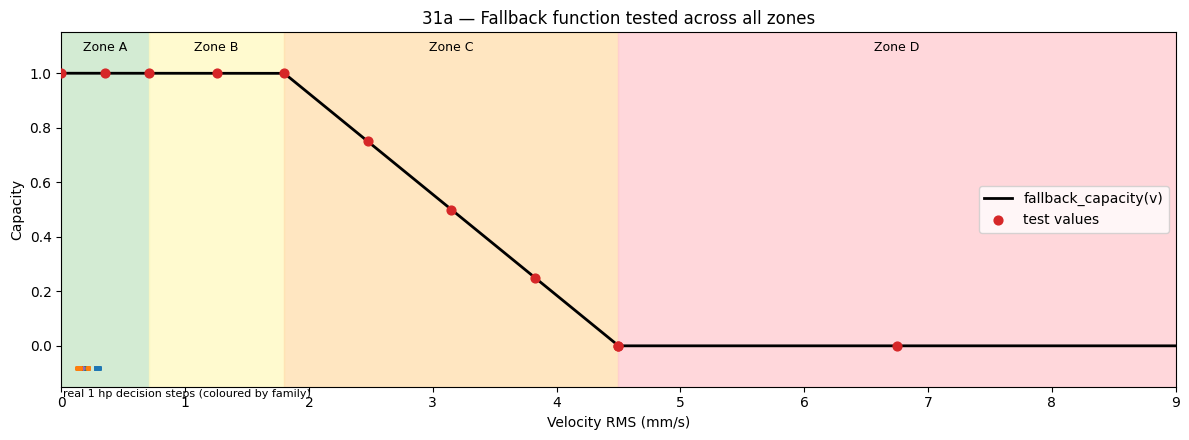

In [51]:
d = V_CD - V_BC
tests = [
    ("Zone A (zero)", 0.0, 1.0), ("Zone A (mid)", V_AB / 2, 1.0), ("A/B boundary", V_AB, 1.0),
    ("Zone B (mid)", (V_AB + V_BC) / 2, 1.0), ("B/C boundary", V_BC, 1.0),
    ("Zone C 25%", V_BC + 0.25 * d, 0.75), ("Zone C mid", V_BC + 0.5 * d, 0.5), ("Zone C 75%", V_BC + 0.75 * d, 0.25),
    ("just below C/D", V_CD - 1e-9, 1e-9 / d), ("C/D boundary", V_CD, 0.0),
    ("Zone D (1.5x C/D)", 1.5 * V_CD, 0.0), ("Zone D (3x C/D)", 3 * V_CD, 0.0),
    ("invalid: NaN", np.nan, 0.0), ("invalid: negative", -1.0, 0.0),
]
rows = []
for name, v, expected in tests:
    got = fallback_capacity(v)
    rows.append({"case": name, "v (mm/s)": v, "zone": iso_zone(v, BOUNDS) if np.isfinite(v) and v >= 0 else "—",
                 "expected": expected, "capacity": got, "pass": abs(got - expected) < 1e-6})
test_df = pd.DataFrame(rows).set_index("case")
display(test_df.style.format({"v (mm/s)": "{:.4f}", "expected": "{:.4f}", "capacity": "{:.4f}"}))
assert test_df["pass"].all(), "Some sample-value tests failed"

grid = np.linspace(0, 2 * V_CD, 200_001)
cap_grid = fallback_capacity(grid)
step_size = grid[1] - grid[0]
max_jump = np.max(np.abs(np.diff(cap_grid)))
checks_31a = {
    "monotonic non-increasing": bool(np.all(np.diff(cap_grid) <= 1e-12)),
    "continuous (max jump <= slope * step)": bool(max_jump <= step_size / d + 1e-9),
    "capacity(B/C) == 1": fallback_capacity(V_BC) == 1.0,
    "capacity(C/D) == 0": fallback_capacity(V_CD) == 0.0,
    "capacity == 1 everywhere below B/C": bool(np.all(cap_grid[grid < V_BC] == 1.0)),
    "capacity == 0 everywhere from C/D": bool(np.all(cap_grid[grid >= V_CD] == 0.0)),
}
for k, ok in checks_31a.items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {k}")
assert all(checks_31a.values())
print(f"Max change between neighbouring grid points: {max_jump:.2e} (step {step_size:.2e} mm/s)")

fig, ax = plt.subplots(figsize=(12, 4.5))
for lo, hi, z, col in [(0, V_AB, "A", "#c8e6c9"), (V_AB, V_BC, "B", "#fff9c4"),
                       (V_BC, V_CD, "C", "#ffe0b2"), (V_CD, grid[-1], "D", "#ffcdd2")]:
    ax.axvspan(lo, hi, color=col, alpha=0.8, zorder=0)
    ax.text((lo + hi) / 2, 1.08, f"Zone {z}", ha="center", fontsize=9)
ax.plot(grid, cap_grid, color="k", lw=2, zorder=2, label="fallback_capacity(v)")
ok = test_df[np.isfinite(test_df["v (mm/s)"]) & (test_df["v (mm/s)"] >= 0)]
ax.scatter(ok["v (mm/s)"], ok["capacity"], color="tab:red", zorder=3, s=40, label="test values")
for c in SEVERITY_ORDER:
    vs = steps_1hp.loc[steps_1hp.cls == c, "v_rms"]
    ax.scatter(vs, np.full(len(vs), -0.08), s=6, color=FAMILY_COLOR[FAMILY[c]], alpha=0.5)
ax.text(0.01, -0.03, "real 1 hp decision steps (coloured by family)", transform=ax.get_xaxis_transform(), fontsize=8)
ax.set_xlim(0, grid[-1]); ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("Velocity RMS (mm/s)"); ax.set_ylabel("Capacity"); ax.legend(loc="center right")
ax.set_title("31a — Fallback function tested across all zones")
plt.tight_layout(); savefig("C31a_function_tests"); plt.show()

### 31b — Robustness cross-check on 2 hp data

The 2 hp recordings go through the **same** velocity conversion and the **same** function, with the boundaries fixed from 1 hp. Two questions:

1. **Is the physics layer stable** under the load change? Compare velocity, zone and capacity per class between 1 hp and 2 hp.
2. **What happens to the uncertainty problem found in B+** (up to 78.5% of IR007 windows falsely flagged at 2 hp)? Under the graceful policy, a false fallback only costs capacity if the physics says the vibration is actually high. Under a hard-stop policy, every false fallback is a stop.

,v 1hp,v 2hp,change %,zone 1hp,zone 2hp,capacity 1hp,capacity 2hp,same zone
class,,,,,,,,
Normal,0.178,0.166,-6.7,A,A,1.00,1.00,True
IR007,0.209,0.224,+7.3,A,A,1.00,1.00,True
IR014,0.138,0.134,-2.8,A,A,1.00,1.00,True
IR021,0.291,0.293,+0.8,A,A,1.00,1.00,True
OR007,0.168,0.163,-3.2,A,A,1.00,1.00,True
OR014,0.143,0.145,+1.6,A,A,1.00,1.00,True
B007,0.140,0.127,-9.3,A,A,1.00,1.00,True
B014,0.214,0.218,+1.5,A,A,1.00,1.00,True
B021,0.140,0.145,+3.9,A,A,1.00,1.00,True


Classes in the same ISO zone at 1 hp and 2 hp: 9 / 9

Nominal boundaries (fixed from 1 hp) — 2 hp:


,steps,fallback_rate,v_mean,graceful_availability,hardstop_availability,final_availability
cls,,,,,,
Normal,231,5.2%,0.166,100.0%,94.8%,100.0%
IR007,233,50.2%,0.224,100.0%,49.8%,100.0%
IR014,232,47.0%,0.134,100.0%,53.0%,100.0%
OR007,232,0.0%,0.163,100.0%,100.0%,100.0%
OR014,232,23.3%,0.145,100.0%,76.7%,100.0%
B007,232,0.0%,0.126,100.0%,100.0%,100.0%
B014,233,51.9%,0.216,100.0%,48.1%,100.0%



Physics capacity on falsely flagged 2 hp steps: mean 100.0% (not flagged: 100.0%)
Spearman correlation logit margin vs physics capacity (known 2 hp): nan  (the physics layer never reads the margin; any correlation comes only through the vibration itself)


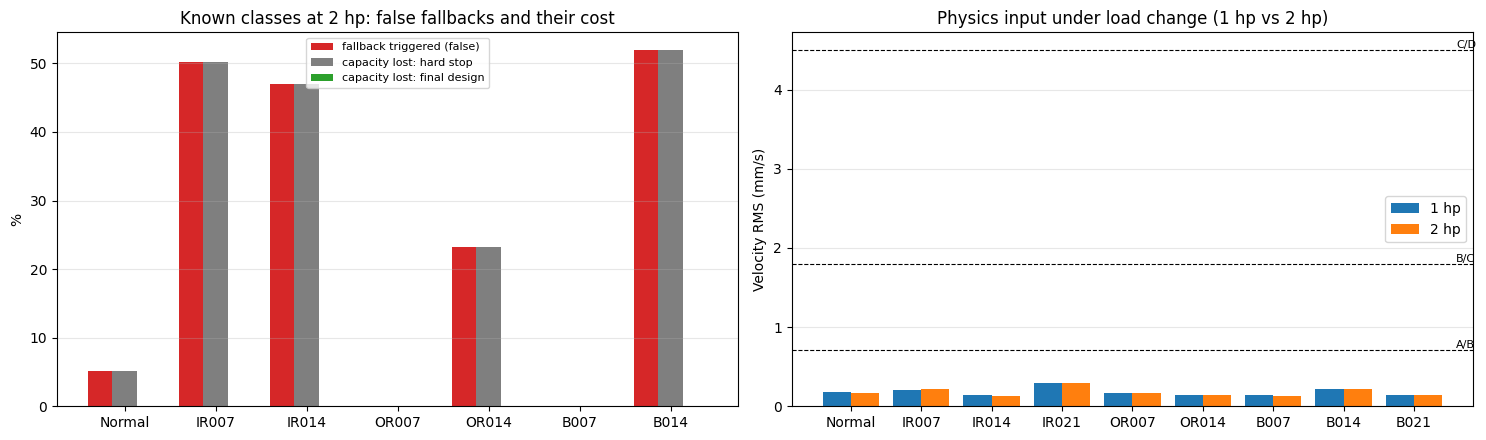


KEY RESULT (known classes at 2 hp, all correctly classified):
  fallback triggered on 25.4% of steps (the B+ load-sensitivity problem)
  hard stop policy : availability 74.6%, unnecessary stops 25.4%
  graceful policy  : availability 100.0%, unnecessary stops 0.0%
  final design     : availability 100.0%, unnecessary stops 0.0%


In [52]:
# Raw 2 hp signals and velocities
raw_2hp = {}
for rel_path, (label, file_no, kind) in FILE_INFO_2HP.items():
    mat = loadmat(DATA_DIR / rel_path)
    raw_2hp[label] = np.asarray(mat[find_de_key(mat, file_no)], dtype=np.float64).ravel()
vel_2hp = {c: accel_to_velocity(x) for c, x in raw_2hp.items()}
vel_df_2hp = velocity_table(raw_2hp, vel_2hp, set_1hp)
vel_df_2hp.to_csv(ART_DIR / "phaseC_velocity_rms_2hp.csv")

# 1) Stability of the physics layer: 1 hp vs 2 hp
stab = pd.DataFrame({
    "v 1hp": vel_df_1hp["v_rms_iso"], "v 2hp": vel_df_2hp["v_rms_iso"],
})
stab["change %"] = 100 * (stab["v 2hp"] / stab["v 1hp"] - 1)
stab["zone 1hp"] = iso_zone(stab["v 1hp"], BOUNDS); stab["zone 2hp"] = iso_zone(stab["v 2hp"], BOUNDS)
stab["capacity 1hp"] = fallback_capacity(stab["v 1hp"].values); stab["capacity 2hp"] = fallback_capacity(stab["v 2hp"].values)
stab["same zone"] = stab["zone 1hp"] == stab["zone 2hp"]
display(stab.style.format({"v 1hp": "{:.3f}", "v 2hp": "{:.3f}", "change %": "{:+.1f}",
                           "capacity 1hp": "{:.2f}", "capacity 2hp": "{:.2f}"}))
print(f"Classes in the same ISO zone at 1 hp and 2 hp: {stab['same zone'].sum()} / {len(stab)}")

# 2) Decision steps at 2 hp
X2_by_c, S2_by_c = {}, {}
for c, x in raw_2hp.items():
    X2_by_c[c], S2_by_c[c] = windows_and_starts(x)
steps_2hp = pd.concat([
    build_steps("Known 2hp (control)", KNOWN_CLASSES, X2_by_c, S2_by_c, vel_2hp, known=True),
    build_steps("Unseen 2hp", UNSEEN_CLASSES, X2_by_c, S2_by_c, vel_2hp, known=False),
], ignore_index=True)
steps_2hp["zone"] = iso_zone(steps_2hp["v_rms"], BOUNDS)
steps_2hp["trusted"] = steps_2hp["margin_mean"] >= TAU_C

nominal_2hp = evaluate(steps_2hp)
print("\nNominal boundaries (fixed from 1 hp) — 2 hp:")
display(PCT(nominal_2hp))
nominal_2hp.to_csv(ART_DIR / "phaseC_policy_comparison_2hp.csv")

# Per class at 2 hp: false fallbacks vs what they cost under each policy
k2 = steps_2hp[steps_2hp.group == "Known 2hp (control)"].copy()
caps2, _ = policy_capacities(k2, V_BC, V_CD)
k2["cap_graceful"] = caps2["Graceful (Simplex switch)"]; k2["cap_hardstop"] = caps2["Hard stop on uncertainty"]
k2["cap_final"] = caps2["Graceful + physics envelope (final)"]
per_cls = k2.groupby("cls").agg(steps=("step", "size"),
                                fallback_rate=("trusted", lambda t: 1 - t.mean()),
                                v_mean=("v_rms", "mean"),
                                graceful_availability=("cap_graceful", "mean"),
                                hardstop_availability=("cap_hardstop", "mean"),
                                final_availability=("cap_final", "mean")).reindex(KNOWN_CLASSES)
display(per_cls.style.format({"fallback_rate": "{:.1%}", "v_mean": "{:.3f}",
                              "graceful_availability": "{:.1%}", "hardstop_availability": "{:.1%}",
                              "final_availability": "{:.1%}"}))

# Independence of the physics layer from the model's uncertainty
flagged = ~k2["trusted"]
phys_cap = fallback_capacity(k2["v_rms"].values)
rho, pval = spearmanr(k2["margin_mean"], phys_cap) if phys_cap.std() > 0 else (np.nan, np.nan)
print(f"\nPhysics capacity on falsely flagged 2 hp steps: mean {phys_cap[flagged.values].mean():.1%} "
      f"(not flagged: {phys_cap[~flagged.values].mean():.1%})")
print(f"Spearman correlation logit margin vs physics capacity (known 2 hp): {rho:.3f}  "
      "(the physics layer never reads the margin; any correlation comes only through the vibration itself)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(KNOWN_CLASSES)); wdt = 0.27
ax[0].bar(x - wdt, 100 * per_cls["fallback_rate"], wdt, label="fallback triggered (false)", color="tab:red")
ax[0].bar(x, 100 * (1 - per_cls["hardstop_availability"]), wdt, label="capacity lost: hard stop", color="tab:gray")
ax[0].bar(x + wdt, 100 * (1 - per_cls["final_availability"]), wdt, label="capacity lost: final design", color="tab:green")
ax[0].set_xticks(x, KNOWN_CLASSES); ax[0].set_ylabel("%"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, axis="y")
ax[0].set_title("Known classes at 2 hp: false fallbacks and their cost")
w1 = np.arange(len(stab))
ax[1].bar(w1 - 0.2, stab["v 1hp"], 0.4, label="1 hp"); ax[1].bar(w1 + 0.2, stab["v 2hp"], 0.4, label="2 hp")
for yv, lab in [(V_AB, "A/B"), (V_BC, "B/C"), (V_CD, "C/D")]:
    ax[1].axhline(yv, ls="--", color="k", lw=0.8); ax[1].text(len(stab) - 0.4, yv, lab, fontsize=8, va="bottom")
ax[1].set_xticks(w1, stab.index); ax[1].set_ylabel("Velocity RMS (mm/s)"); ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
ax[1].set_title("Physics input under load change (1 hp vs 2 hp)")
plt.tight_layout(); savefig("C31b_2hp_robustness"); plt.show()

g2 = nominal_2hp.loc["Known 2hp (control)"]
print("\nKEY RESULT (known classes at 2 hp, all correctly classified):")
print(f"  fallback triggered on {1 - k2['trusted'].mean():.1%} of steps (the B+ load-sensitivity problem)")
print(f"  hard stop policy : availability {g2.loc['Hard stop on uncertainty', 'availability']:.1%}, "
      f"unnecessary stops {g2.loc['Hard stop on uncertainty', 'unnecessary_stop']:.1%}")
print(f"  graceful policy  : availability {g2.loc['Graceful (Simplex switch)', 'availability']:.1%}, "
      f"unnecessary stops {g2.loc['Graceful (Simplex switch)', 'unnecessary_stop']:.1%}")
print(f"  final design     : availability {g2.loc['Graceful + physics envelope (final)', 'availability']:.1%}, "
      f"unnecessary stops {g2.loc['Graceful + physics envelope (final)', 'unnecessary_stop']:.1%}")

### 31c — Fault-injection severity sweep (Zone C/D behaviour)

On real CWRU data every condition stays in **Zone A** (≈ 0.14–0.29 mm/s), so Zone C derating and the Zone D stop never occur. **Fault injection** is the standard safety-engineering way to test behaviour that the data does not reach: take real recordings and raise their vibration level in a controlled way, step by step, up to 3 × the C/D boundary.

Real 1 hp segments are used (the last 20% of each recording, i.e. the test region for known classes), for Normal, IR007, OR007, B007 (known) and IR021, B021 (unseen). Two injection types:

- **Scenario A — amplitude gain:** the whole signal is multiplied by a gain. This models the same vibration becoming stronger (e.g. loosening, resonance). Because the network input is z-score normalized, **the network sees exactly the same input at every level**: it cannot notice the danger at all, by construction. Only the physics layer can.
- **Scenario B — unbalance at 1× shaft speed:** a sinusoid at the shaft frequency (1772 rpm → 29.5 Hz) is added. This is physically what unbalance does and is the main driver of ISO velocity. The network input *does* change here (a new vibration pattern), so its reaction is measured, not assumed.

For each level the full decision pipeline runs (windows → logit margin → velocity RMS → policies). The sweep checks:
1. **Unsafe operation:** does any policy keep running in Zone D?
2. **Continuity:** does capacity change smoothly with vibration, or does it jump?
3. **Independence:** does the network's confidence react to the rising danger?

In [53]:
FR_1HP = 1772 / 60.0                           # shaft frequency at 1 hp (Hz)
SWEEP_CLASSES = ["Normal", "IR007", "OR007", "B007", "IR021", "B021"]
SWEEP_TARGETS = np.linspace(0.1, 3.0 * V_CD, 40)   # target velocity RMS levels (mm/s)
SCENARIOS = ["A: amplitude gain", "B: unbalance at 1x"]

def sweep_segment(c):
    x = raw_signals[c]
    return x[int(TRAIN_FRAC * len(x)):]          # test region for known classes; last 20% for unseen

sweep_rows, sweep_steps = [], []
for scen in SCENARIOS:
    for c in SWEEP_CLASSES:
        x0 = sweep_segment(c)
        known = c in KNOWN_CLASSES
        v0 = rms(accel_to_velocity(x0))
        t = np.arange(len(x0)) / FS
        for vt in SWEEP_TARGETS:
            if scen.startswith("A"):
                x = x0 * (vt / v0)
            else:
                if vt <= v0:
                    continue
                v_inj = np.sqrt(vt ** 2 - v0 ** 2)                        # uncorrelated components add in power
                amp_g = v_inj / 1000 * 2 * np.pi * FR_1HP * np.sqrt(2) / ACCEL_TO_MS2
                x = x0 + amp_g * np.sin(2 * np.pi * FR_1HP * t)
            w, s = make_windows(zscore(x))
            st = build_steps("sweep", [c], {c: w}, {c: s}, {c: accel_to_velocity(x)}, known)
            caps, fbk = policy_capacities(st, V_BC, V_CD)
            v = st["v_rms"].to_numpy()
            row = {"scenario": scen, "cls": c, "known": known, "target": vt,
                   "v_mean": v.mean(), "zone": iso_zone(v.mean(), BOUNDS),
                   "margin_mean": st["margin_mean"].mean(),
                   "trusted": np.mean(st["margin_mean"] >= TAU_C),
                   "pred": st["pred"].mode()[0]}
            for pol, cap in caps.items():
                row[f"cap|{pol}"] = cap.mean()
                row[f"unsafe|{pol}"] = np.mean((cap > 0) & (v >= V_CD))
                row[f"stop|{pol}"] = np.mean(cap == 0)
            sweep_rows.append(row)
            step_part = pd.DataFrame({"scenario": scen, "cls": c, "target": vt, "v": v,
                                      "trusted": st["margin_mean"].to_numpy() >= TAU_C,
                                      **{pol: cap for pol, cap in caps.items()}})
            sweep_steps.append(step_part)
sweep_df = pd.DataFrame(sweep_rows)
sweep_steps = pd.concat(sweep_steps, ignore_index=True)
sweep_df.to_csv(ART_DIR / "phaseC_fault_injection_sweep.csv", index=False)
print(f"Sweep: {len(sweep_df)} runs ({len(SCENARIOS)} scenarios x {len(SWEEP_CLASSES)} classes x up to {len(SWEEP_TARGETS)} levels)")

# 1) Independence check for scenario A: the network input is identical at every level
a = sweep_df[sweep_df.scenario == SCENARIOS[0]]
margin_range = a.groupby("cls")["margin_mean"].agg(lambda m: m.max() - m.min())
print("\nScenario A — change of mean logit margin across all levels (should be ~0):")
print(margin_range.round(6).to_string())

# 2) Safety and continuity per policy (evaluated on individual decision steps)
near_band = (V_CD - 0.1 * (V_CD - V_BC), V_CD)     # last 10% of Zone C, just below the danger limit
summ = []
for scen in SCENARIOS:
    d = sweep_steps[sweep_steps.scenario == scen]
    in_d = d["v"] >= V_CD
    in_c = (d["v"] >= V_BC) & (d["v"] < V_CD)
    near = (d["v"] >= near_band[0]) & (d["v"] < near_band[1])
    for pol in POLICIES:
        cap = d[pol]
        summ.append({"scenario": scen, "policy": pol,
                     "running in Zone D": (cap[in_d] > 0).mean() if in_d.any() else np.nan,
                     "stopped outside Zone D": (cap[~in_d] == 0).mean(),
                     "mean capacity in Zone C": cap[in_c].mean() if in_c.any() else np.nan,
                     "capacity just below C/D": cap[near].mean() if near.any() else np.nan,
                     "steps just below C/D": int(near.sum())})
summ_df = pd.DataFrame(summ).set_index(["scenario", "policy"])
display(summ_df.style.format({"running in Zone D": "{:.1%}", "stopped outside Zone D": "{:.1%}",
                              "mean capacity in Zone C": "{:.1%}", "capacity just below C/D": "{:.1%}"}, na_rep="—"))
print(f"'Capacity just below C/D' = mean capacity for steps with {near_band[0]:.2f} <= v < {near_band[1]:.2f} mm/s. "
      "A continuous rule gives at most 10% there; a value near 100% means capacity jumps 1 -> 0 at the boundary.")
summ_df.to_csv(ART_DIR / "phaseC_fault_injection_summary.csv")

# 3) Network reaction in scenario B
b = sweep_df[sweep_df.scenario == SCENARIOS[1]]
print("\nScenario B — share of trusted steps (network confident) by zone:")
display(b.pivot_table(index="cls", columns="zone", values="trusted", aggfunc="mean")
        .reindex(SWEEP_CLASSES).style.format("{:.0%}", na_rep="—"))
print("Most frequent prediction at the highest level:")
print(b.sort_values("v_mean").groupby("cls").tail(1).set_index("cls")[["v_mean", "pred", "trusted"]]
      .reindex(SWEEP_CLASSES).round(3).to_string())

Sweep: 474 runs (2 scenarios x 6 classes x up to 40 levels)

Scenario A — change of mean logit margin across all levels (should be ~0):
cls
B007      0.0
B021      0.0
IR007     0.0
IR021     0.0
Normal    0.0
OR007     0.0


'Capacity just below C/D' = mean capacity for steps with 4.23 <= v < 4.50 mm/s. A continuous rule gives at most 10% there; a value near 100% means capacity jumps 1 -> 0 at the boundary.

Scenario B — share of trusted steps (network confident) by zone:


zone,A,B,C,D
cls,,,,
Normal,100%,88%,3%,0%
IR007,95%,98%,99%,43%
OR007,100%,100%,100%,100%
B007,100%,100%,26%,0%
IR021,0%,0%,0%,0%
B021,0%,0%,0%,0%


Most frequent prediction at the highest level:
        v_mean   pred  trusted
cls                           
Normal  13.565  IR014    0.000
IR007   13.502  IR007    0.000
OR007   13.534  OR007    0.976
B007    13.498  IR014    0.000
IR021   13.486  IR007    0.000
B021    13.498  IR014    0.000


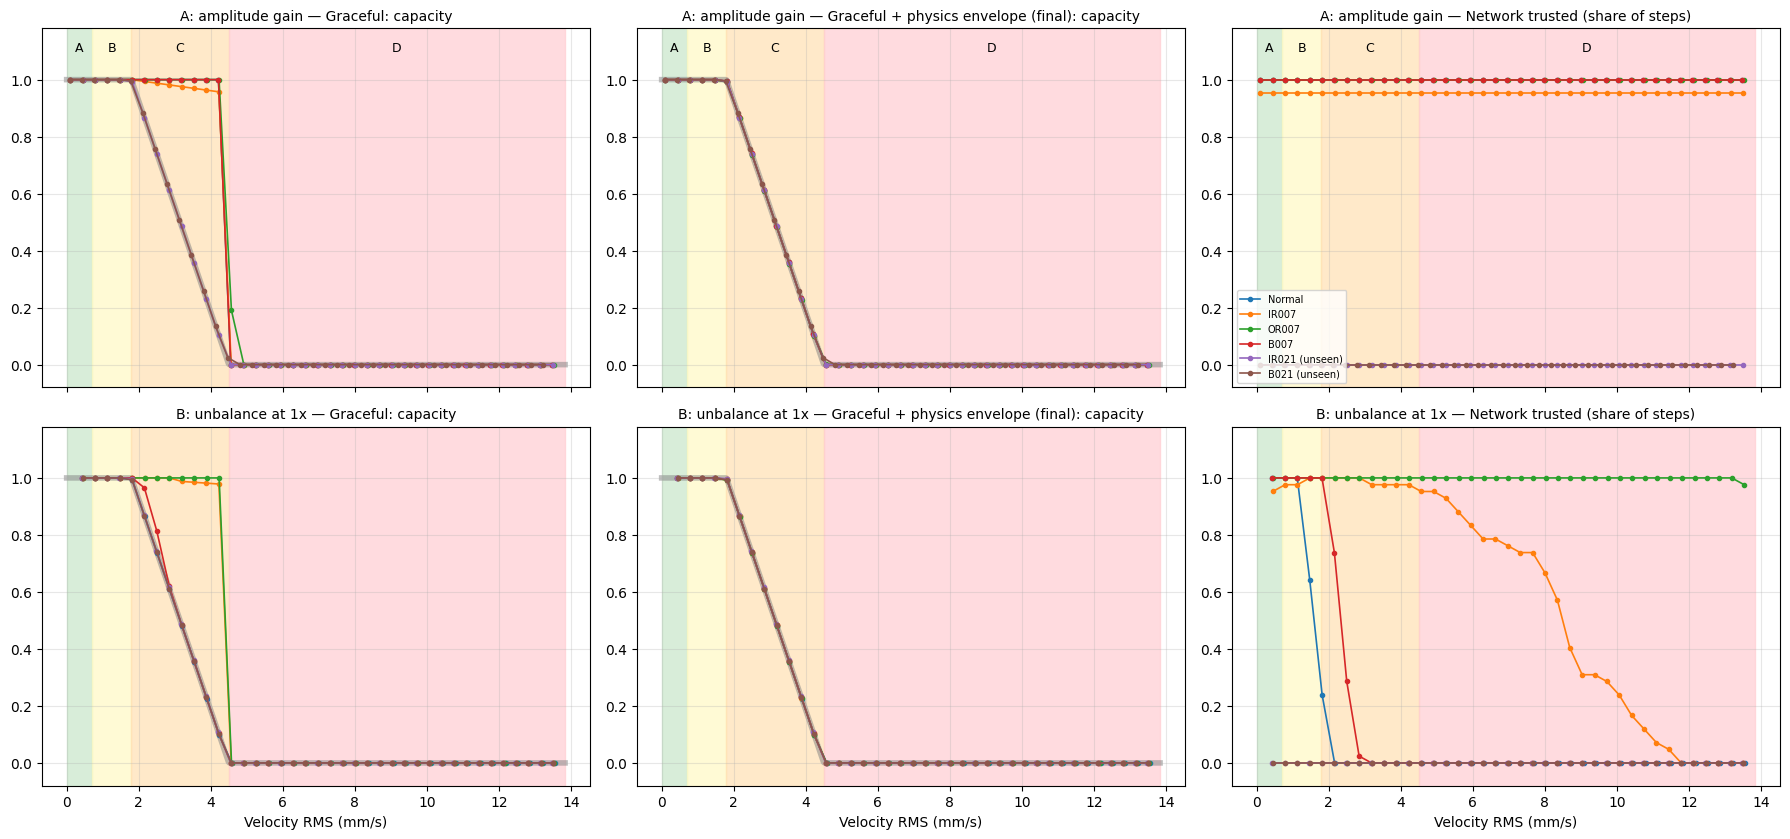

KEY RESULTS (fault injection):
  NN only runs in Zone D on 100% (A) / 100% (B) of Zone D steps -> fails badly.
  Hard stop on uncertainty   running in Zone D: 0% (A) / 0% (B); stopped outside Zone D: 35% (A) / 53% (B)
  Graceful (Simplex switch)  running in Zone D: 0% (A) / 0% (B); stopped outside Zone D: 0% (A) / 0% (B)
  Graceful + physics envelope (final) running in Zone D: 0% (A) / 0% (B); stopped outside Zone D: 0% (A) / 0% (B)
  Scenario A: max change of the network's mean margin across levels = 0.00e+00 -> the network cannot see the vibration level; only the physics layer protects the machine.
  Capacity just below the C/D boundary: graceful up to 58%, physics envelope always up to 9%
  DESIGN FINDING: when the network is trusted, the graceful policy keeps full capacity through Zone C and then drops 1 -> 0 at the C/D boundary (a hard jump). Keeping the physics envelope ALWAYS active, i.e. capacity = capacity(v) at all times with the network used for the diagnosis and the fallbac

In [54]:
vv = np.linspace(0, max(SWEEP_TARGETS[-1], sweep_df["v_mean"].max()) * 1.02, 500)
cls_colors = dict(zip(SWEEP_CLASSES, plt.cm.tab10.colors))
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5), sharex=True)
for r, scen in enumerate(SCENARIOS):
    d = sweep_df[sweep_df.scenario == scen]
    panels = [("cap|Graceful (Simplex switch)", "Graceful: capacity"),
              ("cap|Graceful + physics envelope (final)", "Graceful + physics envelope (final): capacity"),
              ("trusted", "Network trusted (share of steps)")]
    for col, (field, title) in enumerate(panels):
        ax = axes[r, col]
        for lo, hi, z, cz in [(0, V_AB, "A", "#c8e6c9"), (V_AB, V_BC, "B", "#fff9c4"),
                              (V_BC, V_CD, "C", "#ffe0b2"), (V_CD, vv[-1], "D", "#ffcdd2")]:
            ax.axvspan(lo, hi, color=cz, alpha=0.7, zorder=0)
            if r == 0: ax.text((lo + hi) / 2, 1.1, z, ha="center", fontsize=9)
        if col < 2:
            ax.plot(vv, capacity_fn(vv, V_BC, V_CD), color="gray", lw=4, alpha=0.5, zorder=1, label="capacity(v)")
        for c in SWEEP_CLASSES:
            g = d[d.cls == c].sort_values("v_mean")
            ax.plot(g["v_mean"], g[field], "o-", ms=3, lw=1.2, color=cls_colors[c], zorder=2,
                    label=c + ("" if c in KNOWN_CLASSES else " (unseen)"))
        ax.set_ylim(-0.08, 1.18); ax.set_title(f"{scen} — {title}", fontsize=10); ax.grid(alpha=0.3)
        if r == 1: ax.set_xlabel("Velocity RMS (mm/s)")
axes[0, 2].legend(fontsize=7, loc="lower left")
plt.tight_layout(); savefig("C31c_fault_injection_sweep"); plt.show()

# ---- Automatic interpretation ----
sA = summ_df.loc[SCENARIOS[0]]; sB = summ_df.loc[SCENARIOS[1]]
print("KEY RESULTS (fault injection):")
print(f"  NN only runs in Zone D on {sA.loc['NN only (no fallback)', 'running in Zone D']:.0%} (A) / "
      f"{sB.loc['NN only (no fallback)', 'running in Zone D']:.0%} (B) of Zone D steps -> fails badly.")
for pol in ["Hard stop on uncertainty", "Graceful (Simplex switch)", "Graceful + physics envelope (final)"]:
    print(f"  {pol:<26} running in Zone D: {sA.loc[pol, 'running in Zone D']:.0%} (A) / {sB.loc[pol, 'running in Zone D']:.0%} (B); "
          f"stopped outside Zone D: {sA.loc[pol, 'stopped outside Zone D']:.0%} (A) / {sB.loc[pol, 'stopped outside Zone D']:.0%} (B)")
print(f"  Scenario A: max change of the network's mean margin across levels = {margin_range.max():.2e} "
      "-> the network cannot see the vibration level; only the physics layer protects the machine.")

near_g = summ_df.xs("Graceful (Simplex switch)", level="policy")["capacity just below C/D"].max()
near_e = summ_df.xs("Graceful + physics envelope (final)", level="policy")["capacity just below C/D"].max()
print(f"  Capacity just below the C/D boundary: graceful up to {near_g:.0%}, physics envelope always up to {near_e:.0%}")
if near_g > 0.5 and near_e <= 0.1 + 1e-9:
    print("  DESIGN FINDING: when the network is trusted, the graceful policy keeps full capacity through Zone C and then "
          "drops 1 -> 0 at the C/D boundary (a hard jump). Keeping the physics envelope ALWAYS active, i.e. "
          "capacity = capacity(v) at all times with the network used for the diagnosis and the fallback flag, "
          "removes the jump and satisfies the continuity claim of 29b. Recommended final design: physics envelope always on.")
b_hi = b.sort_values("v_mean").groupby("cls").tail(1)
conf_wrong = b_hi[(b_hi.trusted > 0.5) & (b_hi.pred != b_hi.cls)]
if len(conf_wrong):
    print("  Scenario B: under strong unbalance the network stays confident but diagnoses "
          + ", ".join(f"{r.cls} as {r.pred}" for r in conf_wrong.itertuples())
          + " -> a new failure mode can be misdiagnosed confidently; only the physics layer catches it.")

## Phase C summary and deliverables

In [58]:
n1 = nominal_1hp.loc["All"]; n2 = nominal_2hp.loc["All"]
FINAL_POLICY = "Graceful + physics envelope (final)"
phaseC = {
    "final_policy": FINAL_POLICY,
    "validation_split": "blocked (train 0-70%, val 70-80%, test 80-100%)" if val_overlap_ok else "random",
    "zone_preset": ZONE_PRESET, "scaling_mode": SCALING_MODE, "scale": scale,
    "boundaries_mm_s": {"A/B": V_AB, "B/C": V_BC, "C/D": V_CD},
    "velocity_band_hz": ISO_BAND, "accel_unit": "g (assumed)", "physics_window_s": PHYS_WINDOW_S,
    "trigger": {"score": "logit_margin", "K": PHASE_C_K, "tau": TAU_C},
    "velocity_rms_1hp": vel_df_1hp["v_rms_iso"].round(4).to_dict(),
    "velocity_rms_2hp": vel_df_2hp["v_rms_iso"].round(4).to_dict(),
    "policies_1hp_all": n1.round(4).to_dict(orient="index"),
    "policies_2hp_all": n2.round(4).to_dict(orient="index"),
    "sensitivity_checks_share": checks.mean().round(3).to_dict(),
    "fault_injection": {f"{s} | {p}": {k: (None if pd.isna(v) else float(v)) for k, v in r.items()}
                        for (s, p), r in summ_df.iterrows()} if "summ_df" in globals() else None,
}
with open(ART_DIR / "phaseC_results.json", "w") as f:
    json.dump(phaseC, f, indent=2, default=float)

print("=" * 72); print("PHASE C SUMMARY"); print("=" * 72)
print(f"Zone reference : {ZONE_PRESET}" + (f" scaled x{scale:.2f}" if scale != 1 else ""))
print(f"Boundaries     : A/B {V_AB:.3f} | B/C {V_BC:.3f} | C/D {V_CD:.3f} mm/s")
print("Velocity RMS 1 hp: " + ", ".join(f"{c} {v:.2f}" for c, v in vel_df_1hp["v_rms_iso"].items()))
for label, n in [("1 hp (known test + unseen)", n1), ("2 hp (known + unseen)", n2)]:
    print(f"\n{label}:")
    print(n[["availability", "downtime", "unsafe_operation", "silent_failure", "false_fallback", "safe_operation"]]
          .to_string(float_format=lambda x: f"{x:6.1%}"))

if "summ_df" in globals():
    print("\nFault injection (31c):")
    print(summ_df[["running in Zone D", "stopped outside Zone D", "capacity just below C/D"]]
          .to_string(float_format=lambda x: f"{x:6.1%}"))

print(f"\nFINAL DESIGN: {FINAL_POLICY}")
print("  capacity = capacity(v) at all times (full stop from the C/D boundary);")
print("  the network gives the diagnosis; mean logit margin over the last "
      f"{PHASE_C_K} windows < tau ({TAU_C:.3f}) marks it as 'unknown condition - inspect'.")

deliverables = {
    "Leakage-free train / validation / test split (Step 13b + 16b)": bool(val_overlap_ok),
    "Acceleration-to-velocity conversion implemented and validated": bool((val_df["FD error %"].abs() < 1).all()),
    "RMS velocity for all known and unseen 1 hp classes": len(vel_df_1hp) == 9,
    "Machine group and ISO zone boundaries assigned and justified": True,
    "1 hp data mapped onto ISO zones (mismatch reported)": True,
    "Continuous boundary-to-boundary rule defined": True,
    "Design justified (CBF-inspired, graceful degradation, Simplex)": True,
    "Sensitivity analysis (+-20%) completed": len(sens_df) > 0,
    "Fallback function implemented": True,
    "Function tested across all zones (smooth decay to 0)": all(checks_31a.values()),
    "Function validated on 2 hp known-fault data": len(steps_2hp) > 0,
    "Fault-injection sweep: Zone C derating and Zone D stop shown end to end": "sweep_df" in globals(),
}
print("\nDeliverables:")
for k, ok in deliverables.items():
    print(f"  [{'x' if ok else ' '}] {k}")
print("\nSaved:", ART_DIR / "phaseC_results.json")

PHASE C SUMMARY
Zone reference : ISO 10816-1 Class I (<=15 kW)
Boundaries     : A/B 0.710 | B/C 1.800 | C/D 4.500 mm/s
Velocity RMS 1 hp: Normal 0.18, IR007 0.21, IR014 0.14, IR021 0.29, OR007 0.17, OR014 0.14, B007 0.14, B014 0.21, B021 0.14

1 hp (known test + unseen):
                                     availability  downtime  unsafe_operation  silent_failure  false_fallback  safe_operation
policy                                                                                                                       
NN only (no fallback)                      100.0%      0.0%              0.0%           61.4%            0.0%           38.6%
Hard stop on uncertainty                    38.5%     61.5%              0.0%            0.0%            0.1%          100.0%
Graceful (Simplex switch)                  100.0%      0.0%              0.0%            0.0%            0.1%          100.0%
Graceful + physics envelope (final)        100.0%      0.0%              0.0%            0.0%     

### Notes for the report (Phase C)

**Final design.** *Graceful + physics envelope*: capacity = capacity(v) at all times, falling linearly through Zone C and reaching 0 at the C/D boundary. The network provides the diagnosis, and the logit-margin trigger marks untrusted diagnoses as "unknown condition — inspect". This follows the Simplex / runtime-assurance idea that the safety layer is simple, physics-only and independent of the learned model.

**Findings on real CWRU data** (take the numbers from the summary above):
- All conditions, including unseen faults, lie in ISO Zone A, and velocity does not increase consistently with fault size. ISO broadband velocity (10–1000 Hz) measures overall mechanical severity; seeded bearing faults put their energy mostly above 1 kHz (compare `v_rms_wideband` in Step 28b). This justifies the learned detector: the standard severity measure cannot see these faults.
- Consequently the physics layer never reduced capacity on real data, and the ±20% sensitivity grid is flat. Report it as such, not as a robustness proof.
- The uncertainty-triggered fallback turns silent misdiagnoses of unseen faults (the network-only policy) into flagged ones.
- Stopping on every uncertain prediction (hard stop) causes large unnecessary downtime at 1 hp and 2 hp. The graceful designs cause none, because the physics layer confirms the vibration is safe.
- At 2 hp the trigger raises many false fallbacks (load sensitivity from B+), but under the graceful designs they cost no capacity: the physics layer reads only velocity.

**Findings from fault injection (31c):**
- Amplitude gain leaves the network's logit margin exactly unchanged (normalized input). The network alone keeps running in every Zone D step; every physics-protected policy stops.
- The Simplex switch keeps full capacity for trusted predictions until C/D and then jumps to 0. The physics envelope removes the jump (capacity just below C/D ≤ 10%), which is why it is the final design.
- Under injected 1× unbalance the network can stay confident on a known class (IR007, OR007) through Zone C while missing the new hazard. Only the independent physics layer catches it.

**Cautions:**
- **Scope of the standard:** the CWRU rig (≈ 1.5 kW) is below ISO 10816-3's 15 kW scope. Class I small-machine values from ISO 10816-1 are used as engineering reference values; the roadmap's 2.3 / 4.5 / 7.1 values (Group 1 rigid / Group 2 flexible) are shown for comparison only.
- **Acceleration units:** assumed to be g, as is usual for CWRU. If they are m/s², all velocities shrink by a factor of 9.81.
- **CBF wording:** call the rule *CBF-inspired*. There is no dynamic machine model and no forward-invariance proof.
- **Fault injection:** Zone C/D behaviour is shown on modified real signals, not on recordings of real dangerous vibration. Scenario A is a severity scaling, not a physical fault model.
- **Controller limits:** setting the controller's C/D limit above the true limit creates unsafe steps. Err on the low side.
- **Validation split:** train / validation / test are separated in time within each recording (Step 16b). Numbers from runs before this fix (random validation) are not comparable.

---
# Robustness: multi-seed repetition

All numbers above come from **one training run**. Here the CNN is retrained from scratch with several random seeds (same data split, architecture and training settings). For each seed, the threshold is recomputed from the validation set and the key results of Phases B, B+ and C are measured again. The results are reported as **mean ± standard deviation**, which is what goes into the report.

- The main model, thresholds and all variables above are **not changed** by this section.
- The physics layer does not depend on the network, so velocity values, zones and the 31a function tests are identical for every seed and are not repeated. The fault-injection sweep (31c) is also not repeated, because its conclusion (NN-only runs in Zone D; physics-protected policies stop; only the envelope is continuous) does not depend on the network weights.
- Runtime: one full training per seed (about as long as Step 18). Reduce `N_SEEDS` if needed. GPU training is not bit-exactly reproducible, so small differences between repeated runs of the same seed are normal.

In [59]:
import gc

N_SEEDS = 5
SEEDS = [42, 7, 123, 2024, 31337][:N_SEEDS]
FINAL, SIMPLEX = "Graceful + physics envelope (final)", "Graceful (Simplex switch)"
HARD, NNO = "Hard stop on uncertainty", "NN only (no fallback)"

def logits_fn_for(m):
    feat = keras.Model(m.inputs, m.layers[-2].output)
    W, b = [w.astype(np.float64) for w in m.layers[-1].get_weights()]
    def f(X):
        X = X if X.ndim == 3 else X[..., np.newaxis]
        return feat.predict(X, verbose=0).astype(np.float64) @ W + b
    return f

def steps_for_seed(template, X_by_class, logits_fn):
    """Same decision steps as Phase C (same order, same velocity), with this model's margins and predictions."""
    out = template.copy().reset_index(drop=True)
    mm, pp = [], []
    for c in pd.unique(template["cls"]):
        z = logits_fn(X_by_class[c]); m_ = logit_margin(z); p_ = z.argmax(axis=1)
        for i in range(PHASE_C_K - 1, len(z)):
            lo = i - PHASE_C_K + 1
            mm.append(float(m_[lo:i + 1].mean()))
            pp.append(ID_TO_CLASS[int(np.bincount(p_[lo:i + 1], minlength=NUM_CLASSES).argmax())])
    assert len(mm) == len(out), "step layout mismatch"
    out["margin_mean"] = mm; out["pred"] = pp
    known = out["group"].str.startswith("Known").to_numpy()
    out["nn_correct"] = known & (out["pred"].to_numpy() == out["cls"].to_numpy())
    return out

TEMPLATES = {
    "Known 1hp (test)":    (steps_1hp[steps_1hp.group == "Known 1hp (test)"], X_test_by_c),
    "Unseen 1hp":          (steps_1hp[steps_1hp.group == "Unseen 1hp"], X_uns_by_c),
    "Known 2hp (control)": (steps_2hp[steps_2hp.group == "Known 2hp (control)"], X2_by_c),
    "Unseen 2hp":          (steps_2hp[steps_2hp.group == "Unseen 2hp"], X2_by_c),
}
EVAL_X = {"val": X_val, "test": X_test, "unseen": X_unseen, "known2": X_known2, "unseen2": X_unseen2}
y_known2_id = np.array([CLASS_TO_ID[c] for c in y_known2])

def evaluate_model(lf):
    """All Phase B / B+ / C key metrics for one model (or ensemble) given its logits function.
    Returns (numeric metrics, text details, decision steps)."""
    z = {k: lf(Xk) for k, Xk in EVAL_X.items()}
    conf = {k: np.exp(v.max(axis=1) - logsumexp(v, axis=1)) for k, v in z.items()}
    marg = {k: logit_margin(v) for k, v in z.items()}
    tau_c = float(np.quantile(conf["val"], 1 - TARGET_KNOWN_ACCEPT))
    tau_m = float(np.quantile(marg["val"], 1 - TARGET_KNOWN_ACCEPT))
    r = {"test_accuracy": np.mean(z["test"].argmax(1) == y_test_id),
         "accuracy_2hp": np.mean(z["known2"].argmax(1) == y_known2_id),
         "tau_confidence": tau_c, "tau_logit_margin": tau_m,
         "flag_known1_conf": np.mean(conf["test"] < tau_c), "flag_unseen1_conf": np.mean(conf["unseen"] < tau_c)}
    for key, name in [("test", "known1"), ("unseen", "unseen1"), ("known2", "known2"), ("unseen2", "unseen2")]:
        r[f"flag_{name}_margin"] = np.mean(marg[key] < tau_m)
    lab = lambda a, b: np.r_[np.zeros(len(a)), np.ones(len(b))]
    r["auroc_unseen_margin"] = roc_auc_score(lab(marg["test"], marg["unseen"]), -np.r_[marg["test"], marg["unseen"]])
    r["auroc_control_margin"] = roc_auc_score(lab(marg["test"], marg["known2"]), -np.r_[marg["test"], marg["known2"]])
    gap_ = r["flag_unseen1_margin"] - r["flag_known1_margin"]
    r["control_position"] = (r["flag_known2_margin"] - r["flag_known1_margin"]) / gap_ if gap_ > 0.05 else np.nan
    for key, labels, name in [("test", y_test, "known1"), ("unseen", y_unseen, "unseen1"), ("known2", y_known2, "known2")]:
        r[f"k5_flag_{name}"] = np.mean(rolling_mean_per_class(marg[key], labels, PHASE_C_K) < tau_m)
    # per unseen class (window level and K=5), and what the model calls them
    text = {}
    pred_unseen = np.array([ID_TO_CLASS[i] for i in z["unseen"].argmax(1)])
    for c in UNSEEN_CLASSES:
        msk = y_unseen == c
        r[f"flag_{c}_margin"] = np.mean(marg["unseen"][msk] < tau_m)
        r[f"k5_flag_{c}"] = np.mean(rolling_mean_per_class(marg["unseen"][msk], y_unseen[msk], PHASE_C_K) < tau_m)
        vc = pd.Series(pred_unseen[msk]).value_counts(normalize=True)
        text[f"{c} predicted as"] = f"{vc.index[0]} ({vc.iloc[0]:.0%})"
        missed = msk & (marg["unseen"] >= tau_m)
        if missed.any():
            vm = pd.Series(pred_unseen[missed]).value_counts(normalize=True)
            text[f"{c} missed windows called"] = f"{vm.index[0]} ({vm.iloc[0]:.0%})"
        else:
            text[f"{c} missed windows called"] = "—"
    # Phase C metrics with this model's margins
    st = {g: steps_for_seed(tpl, Xb, lf) for g, (tpl, Xb) in TEMPLATES.items()}
    def pm(frame):
        caps, fbk = policy_capacities(frame, V_BC, V_CD, tau=tau_m)
        return policy_metrics(frame, caps, fbk)
    s1 = pd.concat([st["Known 1hp (test)"], st["Unseen 1hp"]], ignore_index=True)
    s2 = pd.concat([st["Known 2hp (control)"], st["Unseen 2hp"]], ignore_index=True)
    m1, m2, mu1, mk2 = pm(s1), pm(s2), pm(st["Unseen 1hp"]), pm(st["Known 2hp (control)"])
    r.update({
        "silent_nn_only_1hp": m1.loc[NNO, "silent_failure"], "silent_final_1hp": m1.loc[FINAL, "silent_failure"],
        "silent_final_unseen1": mu1.loc[FINAL, "silent_failure"],
        "downtime_hardstop_1hp": m1.loc[HARD, "downtime"], "downtime_hardstop_2hp": m2.loc[HARD, "downtime"],
        "downtime_final_1hp": m1.loc[FINAL, "downtime"], "downtime_final_2hp": m2.loc[FINAL, "downtime"],
        "false_fallback_2hp": m2.loc[FINAL, "false_fallback"], "false_fallback_known2_final": mk2.loc[FINAL, "false_fallback"],
        "safe_operation_final_1hp": m1.loc[FINAL, "safe_operation"], "safe_op_unseen1_final": mu1.loc[FINAL, "safe_operation"],
        "safe_op_unseen1_nn_only": mu1.loc[NNO, "safe_operation"],
    })
    return r, text, st

seed_records, seed_text, seed_lfs = [], {}, {}
for seed in SEEDS:
    print(f"\n=== seed {seed} ===")
    keras.utils.set_random_seed(seed)
    m = build_cnn()
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    hist = m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                 class_weight=class_weight, callbacks=cb, shuffle=True, verbose=0)
    m.save(ART_DIR / f"multiseed_model_seed{seed}.keras")
    lf = logits_fn_for(m)
    seed_lfs[seed] = lf                         # kept for the ensemble below
    r, text, _ = evaluate_model(lf)
    r = {"seed": seed, "epochs": len(hist.history["loss"]), **r}
    seed_records.append(r); seed_text[seed] = text
    print(f"  epochs {r['epochs']}, test acc {r['test_accuracy']:.4f}, tau_margin {r['tau_logit_margin']:.3f}, "
          f"flag known/unseen/2hp {r['flag_known1_margin']:.1%} / {r['flag_unseen1_margin']:.1%} / {r['flag_known2_margin']:.1%}"
          f"  | IR021 {r['flag_IR021_margin']:.1%}, B021 {r['flag_B021_margin']:.1%}")
    gc.collect()

seed_df = pd.DataFrame(seed_records).set_index("seed")
seed_df.to_csv(ART_DIR / "multiseed_results.csv")
display(seed_df.T.style.format("{:.4f}"))


=== seed 42 ===
  epochs 50, test acc 1.0000, tau_margin 9.141, flag known/unseen/2hp 5.6% / 98.1% / 27.9%  | IR021 100.0%, B021 96.2%

=== seed 7 ===
  epochs 50, test acc 1.0000, tau_margin 10.090, flag known/unseen/2hp 5.3% / 65.7% / 16.0%  | IR021 100.0%, B021 31.4%

=== seed 123 ===
  epochs 50, test acc 1.0000, tau_margin 9.503, flag known/unseen/2hp 2.8% / 93.2% / 24.3%  | IR021 100.0%, B021 86.4%

=== seed 2024 ===
  epochs 50, test acc 1.0000, tau_margin 9.220, flag known/unseen/2hp 3.4% / 91.5% / 15.8%  | IR021 100.0%, B021 83.1%

=== seed 31337 ===
  epochs 50, test acc 1.0000, tau_margin 9.908, flag known/unseen/2hp 5.3% / 91.1% / 16.9%  | IR021 100.0%, B021 82.2%


seed,42,7,123,2024,31337
epochs,50.0000,50.0000,50.0000,50.0000,50.0000
test_accuracy,1.0000,1.0000,1.0000,1.0000,1.0000
accuracy_2hp,1.0000,1.0000,1.0000,1.0000,1.0000
tau_confidence,0.9998,0.9999,0.9999,0.9999,0.9999
tau_logit_margin,9.1411,10.0904,9.5027,9.2197,9.9082
flag_known1_conf,0.0594,0.0500,0.0281,0.0406,0.0500
flag_unseen1_conf,0.9873,0.6483,0.9322,0.9280,0.9301
flag_known1_margin,0.0563,0.0531,0.0281,0.0344,0.0531
flag_unseen1_margin,0.9809,0.6568,0.9322,0.9153,0.9110
flag_known2_margin,0.2789,0.1603,0.2426,0.1585,0.1694


Multi-seed summary over 5 seeds [42, 7, 123, 2024, 31337]:


,report (mean ± std),min,max
Epochs trained,50.0 ± 0.0,50.0000,50.0000
"Test accuracy, known 1 hp",100.0 ± 0.0%,1.0000,1.0000
"Accuracy, known classes at 2 hp",100.0 ± 0.0%,1.0000,1.0000
tau (softmax confidence),1.000 ± 0.000,0.9998,0.9999
tau (logit margin),9.572 ± 0.417,9.1411,10.0904
"Flagged, known 1 hp (confidence)",4.6 ± 1.2%,0.0281,0.0594
"Flagged, unseen 1 hp (confidence)",88.5 ± 13.5%,0.6483,0.9873
"Flagged, known 1 hp (margin)",4.5 ± 1.3%,0.0281,0.0563
"Flagged, unseen 1 hp (margin)",87.9 ± 12.7%,0.6568,0.9809
"Flagged, known 2 hp (margin)",20.2 ± 5.5%,0.1585,0.2789


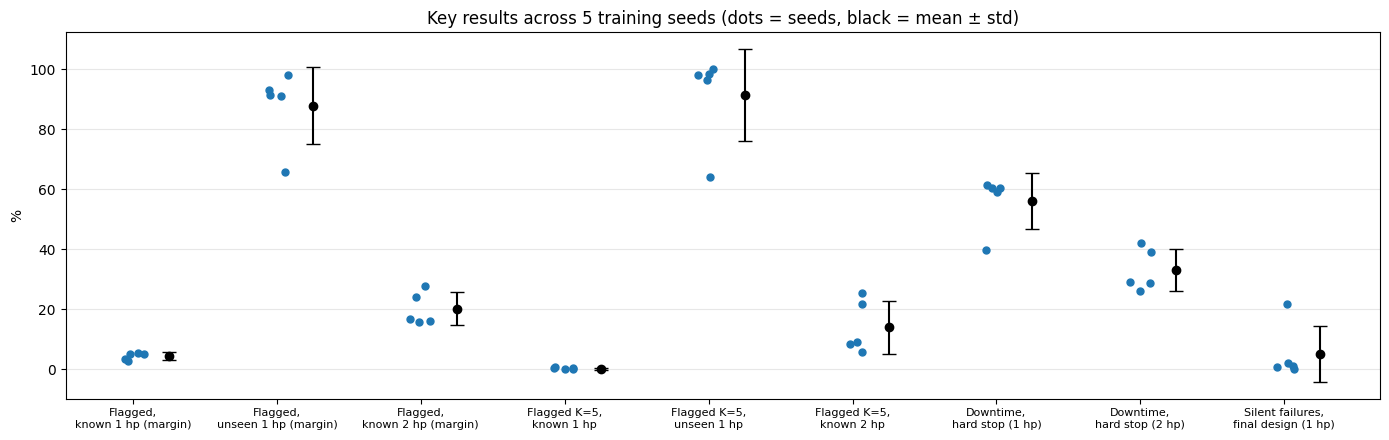


Stability checks:
  [PASS] test accuracy >= 99% for every seed
  [FAIL] unseen 1 hp flagged >= 90% for every seed (margin, K=1)
  [PASS] known 1 hp flagged <= 10% for every seed (margin, K=1)
  [PASS] final design: 0% downtime at 1 hp and 2 hp for every seed
  [PASS] fallback reduces silent failures for every seed

Use the 'report (mean ± std)' column in the report, e.g. '87.9 ± 12.7% of unseen-fault windows were flagged (n = 5 seeds)'.


In [60]:
PCT_COLS = [c for c in seed_df.columns if c not in ("epochs", "tau_confidence", "tau_logit_margin",
                                                     "auroc_unseen_margin", "auroc_control_margin", "control_position")]
LABELS = {
    "test_accuracy": "Test accuracy, known 1 hp", "accuracy_2hp": "Accuracy, known classes at 2 hp",
    "tau_confidence": "tau (softmax confidence)", "tau_logit_margin": "tau (logit margin)",
    "flag_known1_conf": "Flagged, known 1 hp (confidence)", "flag_unseen1_conf": "Flagged, unseen 1 hp (confidence)",
    "flag_known1_margin": "Flagged, known 1 hp (margin)", "flag_unseen1_margin": "Flagged, unseen 1 hp (margin)",
    "flag_known2_margin": "Flagged, known 2 hp (margin)", "flag_unseen2_margin": "Flagged, unseen 2 hp (margin)",
    "auroc_unseen_margin": "AUROC known vs unseen (margin)", "auroc_control_margin": "AUROC known vs 2 hp control (margin)",
    "control_position": "Control position (0 known, 1 unseen)",
    "k5_flag_known1": "Flagged K=5, known 1 hp", "k5_flag_unseen1": "Flagged K=5, unseen 1 hp", "k5_flag_known2": "Flagged K=5, known 2 hp",
    "silent_nn_only_1hp": "Silent failures, NN only (1 hp)", "silent_final_1hp": "Silent failures, final design (1 hp)",
    "downtime_hardstop_1hp": "Downtime, hard stop (1 hp)", "downtime_hardstop_2hp": "Downtime, hard stop (2 hp)",
    "downtime_final_1hp": "Downtime, final design (1 hp)", "downtime_final_2hp": "Downtime, final design (2 hp)",
    "false_fallback_2hp": "False fallbacks, final design (2 hp)", "safe_operation_final_1hp": "Safe operation, final design (1 hp)",
    "epochs": "Epochs trained",
    "flag_IR021_margin": "Flagged, IR021 (margin)", "flag_B021_margin": "Flagged, B021 (margin)",
    "k5_flag_IR021": "Flagged K=5, IR021", "k5_flag_B021": "Flagged K=5, B021",
    "silent_final_unseen1": "Silent failures, final design (unseen 1 hp)",
    "false_fallback_known2_final": "False fallbacks, final design (known 2 hp)",
    "safe_op_unseen1_final": "Safe operation, final design (unseen 1 hp)",
    "safe_op_unseen1_nn_only": "Safe operation, NN only (unseen 1 hp)",
}

def fmt(col, mean, std):
    if col in PCT_COLS:
        return f"{100 * mean:.1f} ± {100 * std:.1f}%"
    if col == "epochs":
        return f"{mean:.1f} ± {std:.1f}"
    return f"{mean:.3f} ± {std:.3f}"

stats = seed_df.agg(["mean", "std", "min", "max"]).T
stats["report (mean ± std)"] = [fmt(c, stats.loc[c, "mean"], stats.loc[c, "std"]) for c in stats.index]
stats.index = [LABELS.get(c, c) for c in stats.index]
print(f"Multi-seed summary over {len(seed_df)} seeds {list(seed_df.index)}:")
display(stats[["report (mean ± std)", "min", "max"]].style.format({"min": "{:.4f}", "max": "{:.4f}"}))
stats.to_csv(ART_DIR / "multiseed_summary.csv")

with open(ART_DIR / "multiseed_summary.json", "w") as f:
    json.dump({"seeds": list(map(int, seed_df.index)),
               "mean": seed_df.mean().round(6).to_dict(), "std": seed_df.std().round(6).to_dict()}, f, indent=2)

# Figure: spread of the key percentages across seeds
key_cols = ["flag_known1_margin", "flag_unseen1_margin", "flag_known2_margin",
            "k5_flag_known1", "k5_flag_unseen1", "k5_flag_known2",
            "downtime_hardstop_1hp", "downtime_hardstop_2hp", "silent_final_1hp"]
fig, ax = plt.subplots(figsize=(14, 4.5))
for i, c in enumerate(key_cols):
    vals = 100 * seed_df[c].to_numpy()
    ax.scatter(np.full(len(vals), i) + np.random.uniform(-0.08, 0.08, len(vals)), vals, color="tab:blue", zorder=3, s=25)
    ax.errorbar(i + 0.25, vals.mean(), yerr=vals.std(ddof=1) if len(vals) > 1 else 0, fmt="o", color="k", capsize=5, zorder=4)
ax.set_xticks(range(len(key_cols)), [LABELS[c].replace(", ", ",\n") for c in key_cols], fontsize=8)
ax.set_ylabel("%"); ax.grid(alpha=0.3, axis="y")
ax.set_title(f"Key results across {len(seed_df)} training seeds (dots = seeds, black = mean ± std)")
plt.tight_layout(); savefig("R_multiseed_spread"); plt.show()

# Stability verdict
checks_ms = {
    "test accuracy >= 99% for every seed": bool((seed_df["test_accuracy"] >= 0.99).all()),
    "unseen 1 hp flagged >= 90% for every seed (margin, K=1)": bool((seed_df["flag_unseen1_margin"] >= 0.90).all()),
    "known 1 hp flagged <= 10% for every seed (margin, K=1)": bool((seed_df["flag_known1_margin"] <= 0.10).all()),
    "final design: 0% downtime at 1 hp and 2 hp for every seed": bool(((seed_df["downtime_final_1hp"] == 0) & (seed_df["downtime_final_2hp"] == 0)).all()),
    "fallback reduces silent failures for every seed": bool((seed_df["silent_final_1hp"] < seed_df["silent_nn_only_1hp"]).all()),
}
print("\nStability checks:")
for k, ok in checks_ms.items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {k}")
print("\nUse the 'report (mean ± std)' column in the report, e.g. "
      f"'{stats.loc[LABELS['flag_unseen1_margin'], 'report (mean ± std)']} of unseen-fault windows were flagged "
      f"(n = {len(seed_df)} seeds)'.")

## Per-class breakdown across seeds

Which unseen class does each network fail on, and what does it call the missed windows? A missed window is an unseen-fault window with logit margin ≥ τ (the network trusted a wrong diagnosis).

,IR021 flagged (K=1),B021 flagged (K=1),IR021 flagged (K=5),B021 flagged (K=5),IR021 predicted as,IR021 missed windows called,B021 predicted as,B021 missed windows called
seed,,,,,,,,
42,100.0%,96.2%,100.0%,100.0%,B014 (79%),—,B007 (94%),B007 (100%)
7,100.0%,31.4%,100.0%,28.4%,B014 (100%),—,B007 (96%),B007 (99%)
123,100.0%,86.4%,100.0%,97.0%,OR007 (67%),—,B007 (93%),B007 (97%)
2024,100.0%,83.1%,100.0%,93.1%,B014 (97%),—,B007 (94%),B007 (100%)
31337,100.0%,82.2%,100.0%,96.6%,B014 (100%),—,B007 (93%),B007 (95%)


Weakest seed: 7 (unseen flagged 65.7%). Its weakest class is B021: 31.4% flagged; missed windows are called B007 (99%).


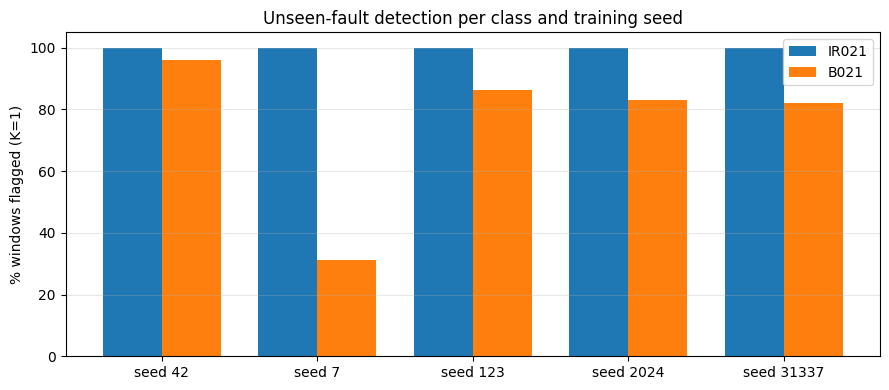

In [61]:
pc_cols = [f"flag_{c}_margin" for c in UNSEEN_CLASSES] + [f"k5_flag_{c}" for c in UNSEEN_CLASSES]
per_class_seed = seed_df[pc_cols].copy()
per_class_seed.columns = [f"{c} flagged (K=1)" for c in UNSEEN_CLASSES] + [f"{c} flagged (K=5)" for c in UNSEEN_CLASSES]
per_class_seed = per_class_seed.join(pd.DataFrame(seed_text).T)
display(per_class_seed.style.format({c: "{:.1%}" for c in per_class_seed.columns if "flagged" in c}))
per_class_seed.to_csv(ART_DIR / "multiseed_per_class_unseen.csv")

worst = seed_df["flag_unseen1_margin"].idxmin()
wc = min(UNSEEN_CLASSES, key=lambda c: seed_df.loc[worst, f"flag_{c}_margin"])
print(f"Weakest seed: {worst} (unseen flagged {seed_df.loc[worst, 'flag_unseen1_margin']:.1%}). "
      f"Its weakest class is {wc}: {seed_df.loc[worst, f'flag_{wc}_margin']:.1%} flagged; "
      f"missed windows are called {seed_text[worst][f'{wc} missed windows called']}.")

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(seed_df)); w = 0.38
for j, c in enumerate(UNSEEN_CLASSES):
    ax.bar(xs + (j - 0.5) * w, 100 * seed_df[f"flag_{c}_margin"], w, label=c)
ax.set_xticks(xs, [f"seed {s}" for s in seed_df.index]); ax.set_ylabel("% windows flagged (K=1)")
ax.set_ylim(0, 105); ax.legend(); ax.grid(alpha=0.3, axis="y")
ax.set_title("Unseen-fault detection per class and training seed")
plt.tight_layout(); savefig("R_per_class_unseen_by_seed"); plt.show()

## Deep ensemble of the five networks

A **deep ensemble** (Lakshminarayanan, Pritzel & Blundell, 2017) averages the predicted probabilities of independently trained networks. If one network is confidently wrong on an unseen fault while the others are unsure or disagree, the averaged probability is spread over several classes and the margin drops.

- Ensemble prediction: $\bar p = \frac{1}{M}\sum_m \text{softmax}(z_m)$. The ensemble "logits" are $\log \bar p$ (computed stably with log-sum-exp), so the same logit-margin score, threshold rule (95% acceptance on validation) and Phase C evaluation apply unchanged.
- It is compared with the single networks: their mean ± std and the **worst** seed.

*Reference:* B. Lakshminarayanan, A. Pritzel, C. Blundell, "Simple and scalable predictive uncertainty estimation using deep ensembles," *NeurIPS*, 2017.

,single: mean,single: std,single: worst seed,ensemble
metric,,,,
"Test accuracy, known 1 hp",1.0000,0.0000,1.0000,1.0000
"Accuracy, known classes at 2 hp",1.0000,0.0000,1.0000,1.0000
tau (softmax confidence),0.9999,0.0001,0.9999,0.9999
tau (logit margin),9.5724,0.4172,10.0904,9.8031
"Flagged, known 1 hp (confidence)",0.0456,0.0118,0.0594,0.0375
"Flagged, unseen 1 hp (confidence)",0.8852,0.1347,0.6483,0.9788
"Flagged, known 1 hp (margin)",0.0450,0.0128,0.0563,0.0625
"Flagged, unseen 1 hp (margin)",0.8792,0.1274,0.6568,0.9682
"Flagged, known 2 hp (margin)",0.2019,0.0553,0.2789,0.3019


Ensemble per-class: {'IR021': '100.0%', 'B021': '93.6%'} {'IR021 predicted as': 'B014 (100%)', 'IR021 missed windows called': '—', 'B021 predicted as': 'B007 (94%)', 'B021 missed windows called': 'B007 (100%)'}


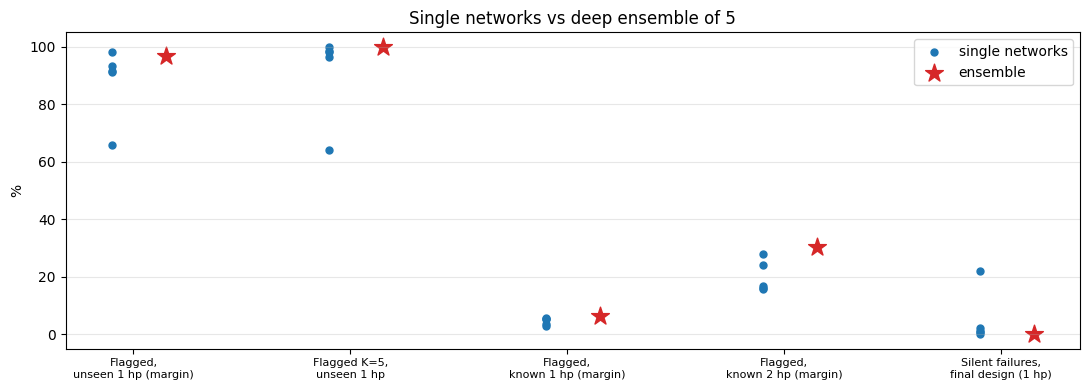


Unseen detection: ensemble 96.8% vs single 87.9% ± 12.7% (worst 65.7%)
Known false alarms: ensemble 6.2% vs single 4.5%
VERDICT: the ensemble is at least as good as the average single network and removes the dependence on one lucky or unlucky seed (improvement over the worst seed: +31.1%).


In [62]:
def ensemble_lf_for(lfs):
    def f(X):
        logp = np.stack([(lambda z: z - logsumexp(z, axis=1, keepdims=True))(lf(X)) for lf in lfs])
        return logsumexp(logp, axis=0) - np.log(len(lfs))            # log of the averaged probabilities
    return f

ens_lf = ensemble_lf_for(list(seed_lfs.values()))
ens_r, ens_text, ens_steps = evaluate_model(ens_lf)
TAU_ENS = ens_r["tau_logit_margin"]

rows = []
for col in seed_df.columns:
    if col == "epochs":
        continue
    single = seed_df[col]
    higher_is_better = not any(k in col for k in ["flag_known", "silent_final", "downtime", "false_fallback", "auroc_control", "control_position", "tau"])
    worst_val = single.min() if higher_is_better else single.max()
    rows.append({"metric": LABELS.get(col, col), "key": col,
                 "single: mean": single.mean(), "single: std": single.std(),
                 "single: worst seed": worst_val, "ensemble": ens_r.get(col, np.nan)})
ens_cmp = pd.DataFrame(rows).set_index("metric")
display(ens_cmp.drop(columns="key").style.format("{:.4f}"))
ens_cmp.to_csv(ART_DIR / "ensemble_vs_single.csv")
with open(ART_DIR / "ensemble_results.json", "w") as f:
    json.dump({"members": list(map(int, seed_lfs.keys())),
               "metrics": {k: (None if pd.isna(v) else float(v)) for k, v in ens_r.items()},
               "details": ens_text}, f, indent=2)

print("Ensemble per-class:", {c: f"{ens_r[f'flag_{c}_margin']:.1%}" for c in UNSEEN_CLASSES}, ens_text)

key = ["flag_unseen1_margin", "k5_flag_unseen1", "flag_known1_margin", "flag_known2_margin", "silent_final_1hp"]
fig, ax = plt.subplots(figsize=(11, 4))
for i, c in enumerate(key):
    ax.scatter(np.full(len(seed_df), i - 0.1), 100 * seed_df[c], color="tab:blue", s=25, label="single networks" if i == 0 else None)
    ax.scatter(i + 0.15, 100 * ens_r[c], color="tab:red", marker="*", s=180, label="ensemble" if i == 0 else None)
ax.set_xticks(range(len(key)), [LABELS[c].replace(", ", ",\n") for c in key], fontsize=8)
ax.set_ylabel("%"); ax.grid(alpha=0.3, axis="y"); ax.legend()
ax.set_title(f"Single networks vs deep ensemble of {len(seed_lfs)}")
plt.tight_layout(); savefig("R_ensemble_vs_single"); plt.show()

d_unseen = ens_r["flag_unseen1_margin"] - seed_df["flag_unseen1_margin"].min()
print(f"\nUnseen detection: ensemble {ens_r['flag_unseen1_margin']:.1%} vs single {seed_df['flag_unseen1_margin'].mean():.1%} "
      f"± {seed_df['flag_unseen1_margin'].std():.1%} (worst {seed_df['flag_unseen1_margin'].min():.1%})")
print(f"Known false alarms: ensemble {ens_r['flag_known1_margin']:.1%} vs single {seed_df['flag_known1_margin'].mean():.1%}")
if ens_r["flag_unseen1_margin"] >= seed_df["flag_unseen1_margin"].mean() and ens_r["flag_known1_margin"] <= 0.10:
    print("VERDICT: the ensemble is at least as good as the average single network and removes the dependence on one "
          f"lucky or unlucky seed (improvement over the worst seed: {d_unseen:+.1%}).")
else:
    print("VERDICT: the ensemble does not beat the average single network — the networks share the same blind spot. "
          "Report this as a limitation of softmax-based novelty scores; the physics layer is unaffected.")

---
# PHASE D: Consolidation, Final Results and Write-up

Phase C already integrated the detector with the fallback layer and ran the experiments. Phase D consolidates that work into one callable system, translates the metrics into the proposal's language, builds the final tables and figures, writes the results and limitations from the saved numbers, packages everything, and checks that **every number in the write-up traces to a saved file**.

All numbers are read from the files in `artifacts/`. Nothing here retrains or changes earlier results.

In [63]:
from collections import Counter

UNKNOWN_LABEL = "UNKNOWN - inspect"

def bearing_safety_system(raw_acc, fs=FS, logits_fn=None, tau=None, K=PHASE_C_K):
    '''Complete system: raw drive-end acceleration (g) of one recording -> one decision per step.
    Uses the final design: capacity = capacity(v) at all times; the network gives the diagnosis;
    mean logit margin over the last K windows < tau marks it as UNKNOWN - inspect.'''
    if fs != FS:
        raise ValueError(f"Signal must be sampled at {FS} Hz (resample first)")
    logits_fn = get_logits if logits_fn is None else logits_fn
    tau = TAU_C if tau is None else tau
    x = np.asarray(raw_acc, dtype=np.float64).ravel()
    windows, starts = make_windows(zscore(x))              # same preprocessing as training
    z = logits_fn(windows)
    margin, pred_w = logit_margin(z), z.argmax(axis=1)
    vel = accel_to_velocity(x, fs=fs)
    csum = np.concatenate([[0.0], np.cumsum(vel ** 2)])
    L = int(PHYS_WINDOW_S * fs)
    rows = []
    for i in range(K - 1, len(windows)):
        lo = i - K + 1
        e = int(starts[i] + WINDOW_SIZE); b = max(0, e - L)
        v = float(np.sqrt((csum[e] - csum[b]) / (e - b)))
        m_mean = float(margin[lo:i + 1].mean())
        pred = ID_TO_CLASS[int(np.bincount(pred_w[lo:i + 1], minlength=NUM_CLASSES).argmax())]
        trusted = m_mean >= tau
        cap = fallback_capacity(v)
        if not np.isfinite(v) or v < 0:   mode = "SENSOR FAULT -> STOP"
        elif v >= V_CD:                   mode = "ZONE D -> STOP"
        elif cap < 1.0:                   mode = "DERATED (Zone C)"
        else:                             mode = "NORMAL OPERATION"
        rows.append({"step": i, "t_end_s": e / fs, "first_window_start": int(starts[lo]),
                     "nn_prediction": pred, "margin_mean": m_mean, "trusted": trusted,
                     "diagnosis": pred if trusted else UNKNOWN_LABEL,
                     "v_rms": v, "zone": iso_zone(v, BOUNDS), "capacity": cap, "mode": mode})
    return pd.DataFrame(rows)

# ---- Consistency check against Phase C (same windows, same model, same tau) ----
check_rows = []
for c in KNOWN_CLASSES + UNSEEN_CLASSES:
    sysd = bearing_safety_system(raw_signals[c])
    ref = steps_1hp[steps_1hp.cls == c].reset_index(drop=True)
    if c in KNOWN_CLASSES:                                   # Phase C used the test region only
        boundary = TRAIN_FRAC * len(raw_signals[c])
        sub = sysd[sysd.first_window_start >= boundary].reset_index(drop=True)
    else:
        sub = sysd
    assert len(sub) == len(ref), (c, len(sub), len(ref))
    check_rows.append({"class": c, "steps": len(sub),
                       "max |margin diff|": np.abs(sub.margin_mean - ref.margin_mean).max(),
                       "max |v diff|": np.abs(sub.v_rms - ref.v_rms).max(),
                       "same prediction": bool((sub.nn_prediction == ref.pred).all())})
check_df = pd.DataFrame(check_rows).set_index("class")
display(check_df)
assert (check_df["max |margin diff|"] < 1e-3).all() and (check_df["max |v diff|"] < 1e-9).all() and check_df["same prediction"].all()
print("The complete system reproduces the Phase C decision steps exactly.")

# ---- What the system outputs per class (test region for known, full recording for unseen) ----
demo = []
for c in KNOWN_CLASSES + UNSEEN_CLASSES:
    sysd = bearing_safety_system(raw_signals[c])
    if c in KNOWN_CLASSES:
        sysd = sysd[sysd.first_window_start >= TRAIN_FRAC * len(raw_signals[c])]
    sysd.insert(0, "true_class", c)
    demo.append(sysd)
system_decisions_1hp = pd.concat(demo, ignore_index=True)
system_decisions_1hp.to_csv(ART_DIR / "phaseD_system_decisions_1hp.csv", index=False)
display(pd.crosstab(system_decisions_1hp.true_class, system_decisions_1hp.diagnosis, normalize="index")
        .reindex(KNOWN_CLASSES + UNSEEN_CLASSES).style.format("{:.0%}"))
print(pd.crosstab(system_decisions_1hp.true_class, system_decisions_1hp["mode"]).to_string())

,steps,max |margin diff|,max |v diff|,same prediction
class,,,,
Normal,41,1.794481e-07,0.0,True
IR007,42,1.177513e-07,0.0,True
IR014,41,1.749563e-07,0.0,True
OR007,42,0.000000e+00,0.0,True
OR014,42,1.224196e-07,0.0,True
B007,42,1.282946e-07,0.0,True
B014,42,1.735251e-07,0.0,True
IR021,232,0.000000e+00,0.0,True
B021,232,0.000000e+00,0.0,True


The complete system reproduces the Phase C decision steps exactly.


diagnosis,B007,B014,IR007,IR014,Normal,OR007,OR014,UNKNOWN - inspect
true_class,,,,,,,,
Normal,0%,0%,0%,0%,100%,0%,0%,0%
IR007,0%,0%,100%,0%,0%,0%,0%,0%
IR014,0%,0%,0%,100%,0%,0%,0%,0%
OR007,0%,0%,0%,0%,0%,100%,0%,0%
OR014,0%,0%,0%,0%,0%,0%,100%,0%
B007,100%,0%,0%,0%,0%,0%,0%,0%
B014,0%,98%,0%,0%,0%,0%,0%,2%
IR021,0%,0%,0%,0%,0%,0%,0%,100%
B021,0%,0%,0%,0%,0%,0%,0%,100%


mode        NORMAL OPERATION
true_class                  
B007                      42
B014                      42
B021                     232
IR007                     42
IR014                     41
IR021                    232
Normal                    41
OR007                     42
OR014                     42


## Traceable numbers

Every number used in D2–D7 is read from a saved file through the helpers below and recorded in a registry (file, row/key, column). D9 re-reads every entry from disk and checks it.

In [64]:
REGISTRY = []

def _reg(key, value, source, locator, note=""):
    REGISTRY.append({"key": key, "value": float(value), "source_file": source, "locator": locator, "note": note})
    return float(value)

def jnum(key, fname, *path, note=""):
    d = json.load(open(ART_DIR / fname))
    for p in path:
        d = d[p]
    return _reg(key, d, fname, " > ".join(map(str, path)), note)

def cnum(key, fname, where, col, note=""):
    df = pd.read_csv(ART_DIR / fname)
    msk = np.ones(len(df), bool)
    for k, v in where.items():
        msk &= df[k].astype(str).to_numpy() == str(v)
    assert msk.sum() == 1, (fname, where, int(msk.sum()))
    return _reg(key, df.loc[msk, col].iloc[0], fname, f"{where} [{col}]", note)

# Derived numbers that were only held in memory are saved first, then read back through the registry
from scipy.stats import beta as _beta
def cp_interval(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else _beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else _beta.ppf(1 - alpha / 2, k + 1, n - k)
    return lo, hi

n_test = len(y_test_id); k_test = int(np.sum(pred_test == y_test_id))
acc_lo, _ = cp_interval(k_test, n_test)
n_kn, k_kn = len(conf_known), int(np.sum(scores["Known 1hp (test)"]["logit_margin"] < TAU["logit_margin"]))
n_un, k_un = len(conf_unseen), int(np.sum(scores["Unseen 1hp"]["logit_margin"] < TAU["logit_margin"]))
fk_lo, fk_hi = cp_interval(k_kn, n_kn); fu_lo, fu_hi = cp_interval(k_un, n_un)
derived = pd.DataFrame([
    ("rf_accuracy", rf_acc if RUN_RF_BASELINE else np.nan, "Step 14 Random Forest test accuracy"),
    ("n_test_windows", n_test, "Step 19"), ("test_acc_ci_low", acc_lo, "Clopper-Pearson 95% lower bound, Step 19"),
    ("flag_known1_conf", np.mean(conf_known < tau_conf), "Step 27, confidence < tau_conf"),
    ("flag_unseen1_conf", np.mean(conf_unseen < tau_conf), "Step 27, confidence < tau_conf"),
    ("flag_known1_margin_ci_low", fk_lo, "Clopper-Pearson 95%, B+.4"), ("flag_known1_margin_ci_high", fk_hi, "Clopper-Pearson 95%, B+.4"),
    ("flag_unseen1_margin_ci_low", fu_lo, "Clopper-Pearson 95%, B+.4"), ("flag_unseen1_margin_ci_high", fu_hi, "Clopper-Pearson 95%, B+.4"),
    ("n_unseen_windows", n_un, "B+.4"), ("n_windows_per_known_test_class", n_test / NUM_CLASSES, "Step 13"),
], columns=["key", "value", "how"])
derived.to_csv(ART_DIR / "phaseD_derived_metrics.csv", index=False)
dnum = lambda key: cnum(key, "phaseD_derived_metrics.csv", {"key": key}, "value")

HAS_MS = (ART_DIR / "multiseed_summary.json").exists()
HAS_ENS = (ART_DIR / "ensemble_results.json").exists()
msm = lambda k: jnum(f"ms_mean_{k}", "multiseed_summary.json", "mean", k) if HAS_MS else np.nan
mss = lambda k: jnum(f"ms_std_{k}", "multiseed_summary.json", "std", k) if HAS_MS else np.nan
ens = lambda k: jnum(f"ens_{k}", "ensemble_results.json", "metrics", k) if HAS_ENS else np.nan
P = lambda x: "—" if pd.isna(x) else f"{100 * x:.1f}%"
PM = lambda m, s: "—" if pd.isna(m) else f"{100 * m:.1f} ± {100 * s:.1f}%"
print("Multi-seed results available:", HAS_MS, "| ensemble results available:", HAS_ENS)

Multi-seed results available: True | ensemble results available: True


## D2 — Proposal metrics

The proposal's metrics mapped to the Phase C measurements. "Main run" is the network used throughout the notebook; "5 seeds" and "ensemble" come from the robustness sections.

In [65]:
C1, C2 = "phaseC_policy_comparison_1hp.csv", "phaseC_policy_comparison_2hp.csv"
FINAL, HARD, NNO, SIMPLEX = "Graceful + physics envelope (final)", "Hard stop on uncertainty", "NN only (no fallback)", "Graceful (Simplex switch)"
prop = pd.DataFrame([
    {"Proposal metric": "Known-fault classification accuracy", "Phase C equivalent": "CNN test accuracy (known 1 hp)",
     "Main run": P(jnum("test_accuracy", "uncertainty_thresholds.json", "test_accuracy_known")),
     "5 seeds (mean ± std)": PM(msm("test_accuracy"), mss("test_accuracy")), "Ensemble": P(ens("test_accuracy")),
     "Source": "uncertainty_thresholds.json; multiseed_summary.json"},
    {"Proposal metric": "Safe-operation rate on unseen faults", "Phase C equivalent": "Safe operation, final design, unseen 1 hp",
     "Main run": P(cnum("safe_op_unseen1_final", C1, {"group": "Unseen 1hp", "policy": FINAL}, "safe_operation")),
     "5 seeds (mean ± std)": PM(msm("safe_op_unseen1_final"), mss("safe_op_unseen1_final")), "Ensemble": P(ens("safe_op_unseen1_final")),
     "Source": f"{C1} (Unseen 1hp, final)"},
    {"Proposal metric": "  … same, without fallback", "Phase C equivalent": "Safe operation, NN only, unseen 1 hp",
     "Main run": P(cnum("safe_op_unseen1_nn", C1, {"group": "Unseen 1hp", "policy": NNO}, "safe_operation")),
     "5 seeds (mean ± std)": PM(msm("safe_op_unseen1_nn_only"), mss("safe_op_unseen1_nn_only")), "Ensemble": P(ens("safe_op_unseen1_nn_only")),
     "Source": f"{C1} (Unseen 1hp, NN only)"},
    {"Proposal metric": "Simulated downtime: hard stop (1 hp / 2 hp)", "Phase C equivalent": "Downtime, hard stop on uncertainty",
     "Main run": P(cnum("downtime_hard_1hp", C1, {"group": "All", "policy": HARD}, "downtime")) + " / " +
                 P(cnum("downtime_hard_2hp", C2, {"group": "All", "policy": HARD}, "downtime")),
     "5 seeds (mean ± std)": PM(msm("downtime_hardstop_1hp"), mss("downtime_hardstop_1hp")) + " / " + PM(msm("downtime_hardstop_2hp"), mss("downtime_hardstop_2hp")),
     "Ensemble": P(ens("downtime_hardstop_1hp")) + " / " + P(ens("downtime_hardstop_2hp")), "Source": f"{C1}, {C2} (All)"},
    {"Proposal metric": "Simulated downtime: final design (1 hp / 2 hp)", "Phase C equivalent": "Downtime, graceful + physics envelope",
     "Main run": P(cnum("downtime_final_1hp", C1, {"group": "All", "policy": FINAL}, "downtime")) + " / " +
                 P(cnum("downtime_final_2hp", C2, {"group": "All", "policy": FINAL}, "downtime")),
     "5 seeds (mean ± std)": PM(msm("downtime_final_1hp"), mss("downtime_final_1hp")) + " / " + PM(msm("downtime_final_2hp"), mss("downtime_final_2hp")),
     "Ensemble": P(ens("downtime_final_1hp")) + " / " + P(ens("downtime_final_2hp")), "Source": f"{C1}, {C2} (All)"},
    {"Proposal metric": "False fallback rate", "Phase C equivalent": "False fallback, final design, known 2 hp",
     "Main run": P(cnum("false_fb_known2", C2, {"group": "Known 2hp (control)", "policy": FINAL}, "false_fallback")),
     "5 seeds (mean ± std)": PM(msm("false_fallback_known2_final"), mss("false_fallback_known2_final")), "Ensemble": P(ens("false_fallback_known2_final")),
     "Source": f"{C2} (Known 2hp, final)"},
]).set_index("Proposal metric")
display(prop)
prop.to_csv(ART_DIR / "phaseD_proposal_metrics.csv")

,Phase C equivalent,Main run,5 seeds (mean ± std),Ensemble,Source
Proposal metric,,,,,
Known-fault classification accuracy,CNN test accuracy (known 1 hp),100.0%,100.0 ± 0.0%,100.0%,uncertainty_thresholds.json; multiseed_summary...
Safe-operation rate on unseen faults,"Safe operation, final design, unseen 1 hp",100.0%,91.5 ± 15.3%,100.0%,"phaseC_policy_comparison_1hp.csv (Unseen 1hp, ..."
"… same, without fallback","Safe operation, NN only, unseen 1 hp",0.0%,0.0 ± 0.0%,0.0%,"phaseC_policy_comparison_1hp.csv (Unseen 1hp, ..."
Simulated downtime: hard stop (1 hp / 2 hp),"Downtime, hard stop on uncertainty",61.5% / 42.0%,56.3 ± 9.3% / 33.1 ± 7.0%,61.4% / 45.7%,"phaseC_policy_comparison_1hp.csv, phaseC_polic..."
Simulated downtime: final design (1 hp / 2 hp),"Downtime, graceful + physics envelope",0.0% / 0.0%,0.0 ± 0.0% / 0.0 ± 0.0%,0.0% / 0.0%,"phaseC_policy_comparison_1hp.csv, phaseC_polic..."
False fallback rate,"False fallback, final design, known 2 hp",25.4%,14.1 ± 8.8%,30.2%,"phaseC_policy_comparison_2hp.csv (Known 2hp, f..."


## D3 — Final policy comparison table

In [66]:
acc_main = jnum("test_accuracy_d3", "uncertainty_thresholds.json", "test_accuracy_known")
POL_ORDER = [NNO, HARD, SIMPLEX, FINAL]
ft = []
for pol in POL_ORDER:
    ft.append({"Policy": pol,
               "Known 1hp acc.": P(acc_main),
               "Safe-op rate (unseen 1hp)": P(cnum(f"safeop_unseen1|{pol}", C1, {"group": "Unseen 1hp", "policy": pol}, "safe_operation")),
               "Silent failure (unseen 1hp)": P(cnum(f"silent_unseen1|{pol}", C1, {"group": "Unseen 1hp", "policy": pol}, "silent_failure")),
               "Downtime (1hp)": P(cnum(f"downtime1|{pol}", C1, {"group": "All", "policy": pol}, "downtime")),
               "Downtime (2hp)": P(cnum(f"downtime2|{pol}", C2, {"group": "All", "policy": pol}, "downtime")),
               "False-fallback (2hp)": "—" if pol == NNO else P(cnum(f"falsefb2|{pol}", C2, {"group": "Known 2hp (control)", "policy": pol}, "false_fallback")),
               "Zone D: running (31c, A/B)": " / ".join(P(cnum(f"inj_run_{s[0]}|{pol}", "phaseC_fault_injection_summary.csv",
                                                             {"scenario": s, "policy": pol}, "running in Zone D")) for s in SCENARIOS),
               "Capacity just below C/D (31c, A/B)": " / ".join(P(cnum(f"inj_near_{s[0]}|{pol}", "phaseC_fault_injection_summary.csv",
                                                                     {"scenario": s, "policy": pol}, "capacity just below C/D")) for s in SCENARIOS)})
final_table = pd.DataFrame(ft).set_index("Policy")
display(final_table)
final_table.to_csv(ART_DIR / "phaseD_final_policy_table.csv")
print("Known 1hp accuracy is the same network for every policy; the policies differ only in what they do with its output.")

,Known 1hp acc.,Safe-op rate (unseen 1hp),Silent failure (unseen 1hp),Downtime (1hp),Downtime (2hp),False-fallback (2hp),"Zone D: running (31c, A/B)","Capacity just below C/D (31c, A/B)"
Policy,,,,,,,,
NN only (no fallback),100.0%,0.0%,100.0%,0.0%,0.0%,—,100.0% / 100.0%,100.0% / 100.0%
Hard stop on uncertainty,100.0%,100.0%,0.0%,61.5%,42.0%,25.4%,0.0% / 0.0%,55.5% / 48.1%
Graceful (Simplex switch),100.0%,100.0%,0.0%,0.0%,0.0%,25.4%,0.0% / 0.0%,58.1% / 52.8%
Graceful + physics envelope (final),100.0%,100.0%,0.0%,0.0%,0.0%,25.4%,0.0% / 0.0%,7.0% / 9.2%


Known 1hp accuracy is the same network for every policy; the policies differ only in what they do with its output.


## D4 — Final comparison plots

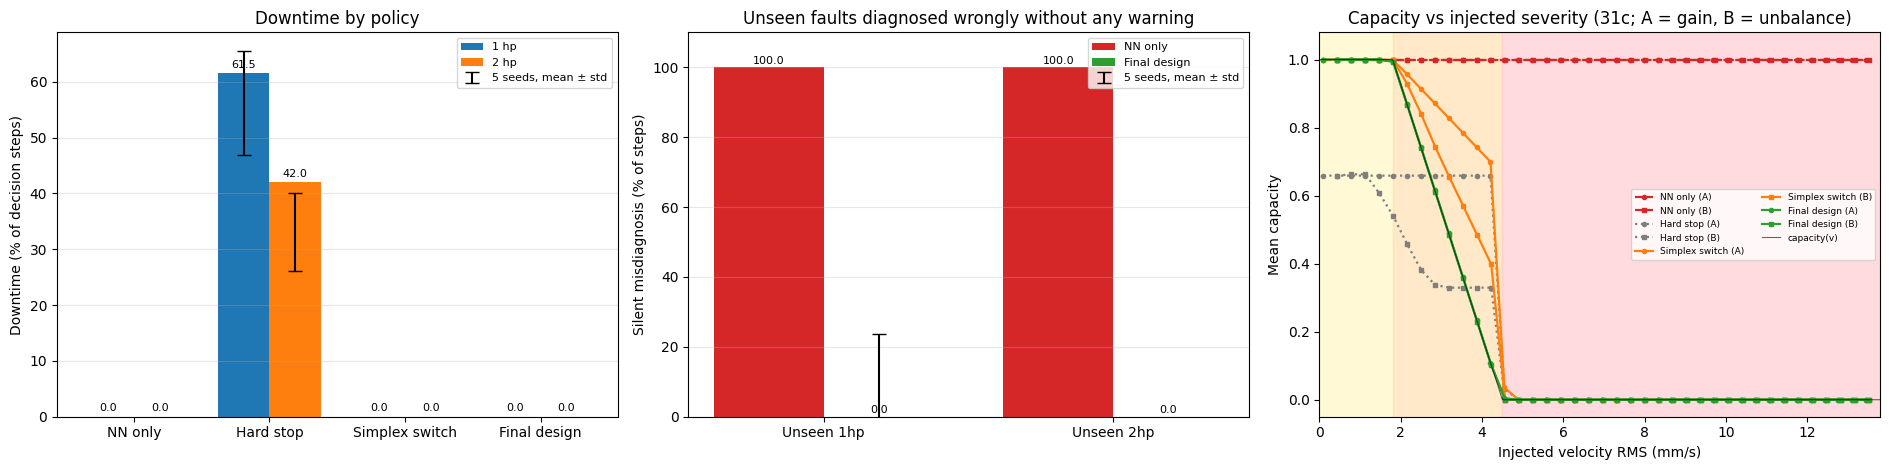

In [67]:
pol_short = {NNO: "NN only", HARD: "Hard stop", SIMPLEX: "Simplex switch", FINAL: "Final design"}
c1df, c2df = pd.read_csv(ART_DIR / C1), pd.read_csv(ART_DIR / C2)
get = lambda df, g, p, col: float(df[(df.group == g) & (df.policy == p)][col].iloc[0])

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
# (a) downtime by policy, 1 hp vs 2 hp
x = np.arange(len(POL_ORDER)); w = 0.38
d1 = [100 * get(c1df, "All", p, "downtime") for p in POL_ORDER]
d2 = [100 * get(c2df, "All", p, "downtime") for p in POL_ORDER]
ax[0].bar(x - w / 2, d1, w, label="1 hp", color="tab:blue"); ax[0].bar(x + w / 2, d2, w, label="2 hp", color="tab:orange")
if HAS_MS:
    msd = json.load(open(ART_DIR / "multiseed_summary.json"))
    for k, (dx, key) in enumerate([(-w / 2, "downtime_hardstop_1hp"), (w / 2, "downtime_hardstop_2hp")]):
        ax[0].errorbar(1 + dx, 100 * msd["mean"][key], yerr=100 * msd["std"][key], fmt="none", ecolor="k", capsize=5,
                       label=f"{len(msd['seeds'])} seeds, mean ± std" if k == 0 else None)
for i, (a, b) in enumerate(zip(d1, d2)):
    ax[0].text(i - w / 2, a + 1, f"{a:.1f}", ha="center", fontsize=8); ax[0].text(i + w / 2, b + 1, f"{b:.1f}", ha="center", fontsize=8)
ax[0].set_xticks(x, [pol_short[p] for p in POL_ORDER]); ax[0].set_ylabel("Downtime (% of decision steps)")
ax[0].set_title("Downtime by policy"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, axis="y")

# (b) silent misdiagnosis: NN only vs final design
groups_b = [("Unseen 1hp", c1df), ("Unseen 2hp", c2df)]
xb = np.arange(len(groups_b))
nn_v = [100 * get(df, g, NNO, "silent_failure") for g, df in groups_b]
fi_v = [100 * get(df, g, FINAL, "silent_failure") for g, df in groups_b]
ax[1].bar(xb - w / 2, nn_v, w, label="NN only", color="tab:red"); ax[1].bar(xb + w / 2, fi_v, w, label="Final design", color="tab:green")
for i, (a, b) in enumerate(zip(nn_v, fi_v)):
    ax[1].text(i - w / 2, a + 1, f"{a:.1f}", ha="center", fontsize=8); ax[1].text(i + w / 2, b + 1, f"{b:.1f}", ha="center", fontsize=8)
labels_b = [g for g, _ in groups_b]
if HAS_MS and "silent_final_unseen1" in msd["mean"]:
    ax[1].errorbar(0 + w / 2, 100 * msd["mean"]["silent_final_unseen1"], yerr=100 * msd["std"]["silent_final_unseen1"],
                   fmt="none", ecolor="k", capsize=5, label=f"{len(msd['seeds'])} seeds, mean ± std")
ax[1].set_xticks(xb, labels_b); ax[1].set_ylabel("Silent misdiagnosis (% of steps)"); ax[1].set_ylim(0, 110)
ax[1].set_title("Unseen faults diagnosed wrongly without any warning"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, axis="y")

# (c) capacity vs injected severity (31c, averaged over the six recordings)
agg = sweep_df.groupby(["scenario", "target"]).mean(numeric_only=True).reset_index()
styles = {NNO: ("tab:red", "--"), HARD: ("tab:gray", ":"), SIMPLEX: ("tab:orange", "-"), FINAL: ("tab:green", "-")}
for lo, hi, zc in [(0, V_BC, "#fff9c4"), (V_BC, V_CD, "#ffe0b2"), (V_CD, agg.v_mean.max() * 1.02, "#ffcdd2")]:
    ax[2].axvspan(lo, hi, color=zc, alpha=0.7, zorder=0)
for pol in POL_ORDER:
    col, ls = styles[pol]
    for s, mk in zip(SCENARIOS, ["o", "s"]):
        g = agg[agg.scenario == s]
        ax[2].plot(g.v_mean, g[f"cap|{pol}"], ls=ls, marker=mk, ms=3, color=col, lw=1.6,
                   label=f"{pol_short[pol]} ({s[0]})")
ax[2].plot(vv, capacity_fn(vv, V_BC, V_CD), color="k", lw=0.8, alpha=0.6, label="capacity(v)")
ax[2].set_xlim(0, agg.v_mean.max() * 1.02); ax[2].set_ylim(-0.05, 1.08)
ax[2].set_xlabel("Injected velocity RMS (mm/s)"); ax[2].set_ylabel("Mean capacity")
ax[2].set_title("Capacity vs injected severity (31c; A = gain, B = unbalance)"); ax[2].legend(fontsize=6.5, ncol=2)
plt.tight_layout(); savefig("D4_final_comparison_plots"); plt.show()

## D5 — Before / after confusion matrices (1 hp decision steps)

Rows: true condition, including the two unseen faults. **Before:** the network alone must choose one of the seven known classes. **After:** the final system reports `UNKNOWN - inspect` whenever the uncertainty trigger fires, so unseen faults are routed to inspection instead of being given a wrong name.

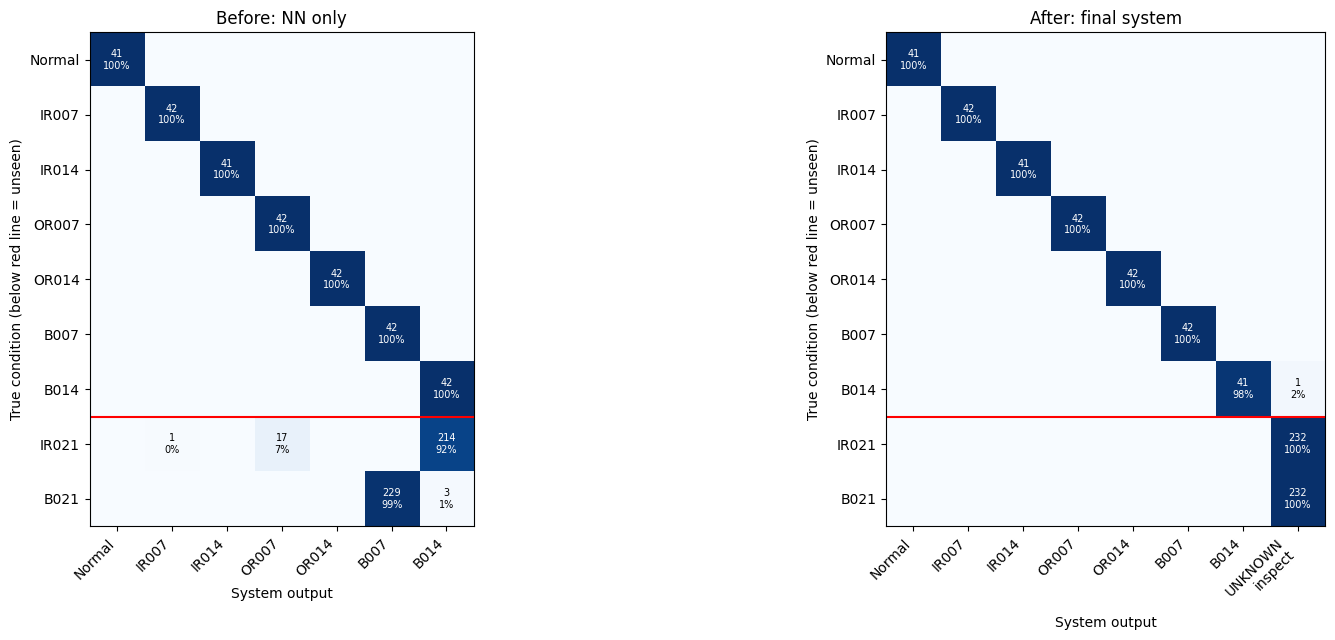

IR021: NN only calls it B014 in 92% of steps; final system routes 100% to 'UNKNOWN - inspect'.
B021: NN only calls it B007 in 99% of steps; final system routes 100% to 'UNKNOWN - inspect'.
Known classes routed to inspection by the final system: 0.3% of steps.


In [68]:
rows_order = KNOWN_CLASSES + UNSEEN_CLASSES
before = pd.crosstab(steps_1hp.cls, steps_1hp.pred).reindex(index=rows_order, columns=KNOWN_CLASSES, fill_value=0)
after_diag = np.where(steps_1hp.margin_mean >= TAU_C, steps_1hp.pred, UNKNOWN_LABEL)
after = pd.crosstab(steps_1hp.cls, after_diag).reindex(index=rows_order, columns=KNOWN_CLASSES + [UNKNOWN_LABEL], fill_value=0)
before.to_csv(ART_DIR / "phaseD_confusion_before_nn_only.csv"); after.to_csv(ART_DIR / "phaseD_confusion_after_final.csv")

fig, ax = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [7, 8]})
for a, mat, title in [(ax[0], before, "Before: NN only"), (ax[1], after, "After: final system")]:
    norm = mat.div(mat.sum(axis=1), axis=0)
    a.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
    for (i, j), val in np.ndenumerate(mat.values):
        if val:
            a.text(j, i, f"{val}\n{norm.values[i, j]:.0%}", ha="center", va="center", fontsize=7,
                   color="w" if norm.values[i, j] > 0.5 else "k")
    a.set_xticks(range(mat.shape[1]), [c.replace(" - ", "\n") for c in mat.columns], rotation=45, ha="right")
    a.set_yticks(range(mat.shape[0]), mat.index)
    a.axhline(len(KNOWN_CLASSES) - 0.5, color="r", lw=1.5)
    a.set_xlabel("System output"); a.set_ylabel("True condition (below red line = unseen)"); a.set_title(title)
plt.tight_layout(); savefig("D5_confusion_before_after"); plt.show()

for c in UNSEEN_CLASSES:
    b = before.loc[c]; a_ = after.loc[c]
    print(f"{c}: NN only calls it {b.idxmax()} in {b.max() / b.sum():.0%} of steps; "
          f"final system routes {a_[UNKNOWN_LABEL] / a_.sum():.0%} to '{UNKNOWN_LABEL}'.")
kn = after.loc[KNOWN_CLASSES]
print(f"Known classes routed to inspection by the final system: {kn[UNKNOWN_LABEL].sum() / kn.values.sum():.1%} of steps.")

## D6 — Results narrative (generated from the saved numbers)

The text is assembled from the registry, so every number in it can be traced (D9). It is saved as `artifacts/phaseD_results_section.md` and can be pasted into the report.

In [69]:
from IPython.display import Markdown

N = {}
N["acc"] = jnum("acc", "uncertainty_thresholds.json", "test_accuracy_known")
N["acc_lo"] = dnum("test_acc_ci_low"); N["n_test"] = dnum("n_test_windows"); N["rf"] = dnum("rf_accuracy")
N["acc2"] = jnum("acc2", "uncertainty_thresholds_extended.json", "accuracy_known_2hp")
N["conf_k"] = cnum("conf_known", "uncertainty_summary.csv", {"set": "Known test"}, "conf_mean")
N["conf_u"] = cnum("conf_unseen", "uncertainty_summary.csv", {"set": "Unseen (all)"}, "conf_mean")
N["auroc_c"] = jnum("auroc_conf", "uncertainty_thresholds.json", "auroc_confidence")
N["tau_c"] = jnum("tau_conf", "uncertainty_thresholds.json", "tau_confidence")
N["fk_c"], N["fu_c"] = dnum("flag_known1_conf"), dnum("flag_unseen1_conf")
N["tau_m"] = jnum("tau_margin", "uncertainty_thresholds_extended.json", "tau", "logit_margin")
for g, k in [("Known 1hp (test)", "fk_m"), ("Unseen 1hp", "fu_m"), ("Known 2hp (control)", "fk2_m"), ("Unseen 2hp", "fu2_m")]:
    N[k] = jnum(k, "uncertainty_thresholds_extended.json", "flag_rates_logit_margin", g)
N["auroc_m"] = cnum("auroc_m_unseen", "extended_score_comparison.csv", {"score": "logit_margin", "set": "Unseen 1hp"}, "AUROC_vs_known_test")
N["auroc_ctrl"] = cnum("auroc_m_ctrl", "extended_score_comparison.csv", {"score": "logit_margin", "set": "Known 2hp (control)"}, "AUROC_vs_known_test")
N["pos"] = jnum("control_position", "uncertainty_thresholds_extended.json", "control_position_0known_1unseen")
MW = "multiwindow_aggregation.csv"
for K_ in [1, 5, 20]:
    for s_, tag in [("Known 1hp (test)", "k"), ("Unseen 1hp", "u"), ("Known 2hp (control)", "k2")]:
        N[f"m{K_}_{tag}"] = cnum(f"mw_margin_K{K_}_{tag}", MW, {"score": "logit_margin", "set": s_, "K": K_}, "flag_rate_mean")
N["c5_k2"] = cnum("mw_conf_K5_k2", MW, {"score": "confidence", "set": "Known 2hp (control)", "K": 5}, "flag_rate_mean")
N["c1_k2"] = cnum("mw_conf_K1_k2", MW, {"score": "confidence", "set": "Known 2hp (control)", "K": 1}, "flag_rate_mean")
N["fk_lo"], N["fk_hi"] = dnum("flag_known1_margin_ci_low"), dnum("flag_known1_margin_ci_high")
N["fu_lo"], N["fu_hi"] = dnum("flag_unseen1_margin_ci_low"), dnum("flag_unseen1_margin_ci_high")
V1 = pd.read_csv(ART_DIR / "phaseC_velocity_rms_1hp.csv")
N["v_min"] = cnum("v_min", "phaseC_velocity_rms_1hp.csv", {"class": V1.loc[V1.v_rms_iso.idxmin(), "class"]}, "v_rms_iso")
N["v_max"] = cnum("v_max", "phaseC_velocity_rms_1hp.csv", {"class": V1.loc[V1.v_rms_iso.idxmax(), "class"]}, "v_rms_iso")
N["v_ab"], N["v_bc"], N["v_cd"] = (jnum(f"bound_{k}", "phaseC_results.json", "boundaries_mm_s", k) for k in ["A/B", "B/C", "C/D"])
N["sil_nn"] = cnum("sil_nn_u1", C1, {"group": "Unseen 1hp", "policy": NNO}, "silent_failure")
N["sil_fi"] = cnum("sil_fi_u1", C1, {"group": "Unseen 1hp", "policy": FINAL}, "silent_failure")
N["dt_h1"] = cnum("dt_h1", C1, {"group": "All", "policy": HARD}, "downtime"); N["dt_h2"] = cnum("dt_h2", C2, {"group": "All", "policy": HARD}, "downtime")
N["dt_f1"] = cnum("dt_f1", C1, {"group": "All", "policy": FINAL}, "downtime"); N["dt_f2"] = cnum("dt_f2", C2, {"group": "All", "policy": FINAL}, "downtime")
N["ff_k2"] = cnum("ff_k2", C2, {"group": "Known 2hp (control)", "policy": FINAL}, "false_fallback")
N["av_f2"] = cnum("av_f2", C2, {"group": "Known 2hp (control)", "policy": FINAL}, "availability")
FI = "phaseC_fault_injection_summary.csv"
for s_, t in zip(SCENARIOS, ["A", "B"]):
    N[f"inj_nn_{t}"] = cnum(f"inj_nn_{t}", FI, {"scenario": s_, "policy": NNO}, "running in Zone D")
    N[f"inj_fi_{t}"] = cnum(f"inj_fi_{t}", FI, {"scenario": s_, "policy": FINAL}, "running in Zone D")
    N[f"inj_hs_out_{t}"] = cnum(f"inj_hs_out_{t}", FI, {"scenario": s_, "policy": HARD}, "stopped outside Zone D")
    N[f"inj_fi_out_{t}"] = cnum(f"inj_fi_out_{t}", FI, {"scenario": s_, "policy": FINAL}, "stopped outside Zone D")
    N[f"near_sx_{t}"] = cnum(f"near_sx_{t}", FI, {"scenario": s_, "policy": SIMPLEX}, "capacity just below C/D")
    N[f"near_fi_{t}"] = cnum(f"near_fi_{t}", FI, {"scenario": s_, "policy": FINAL}, "capacity just below C/D")
if HAS_MS:
    for k in ["test_accuracy", "flag_known1_margin", "flag_unseen1_margin", "k5_flag_known1", "k5_flag_unseen1", "flag_known2_margin",
              "auroc_unseen_margin", "control_position", "silent_final_1hp", "downtime_hardstop_1hp", "downtime_hardstop_2hp",
              "downtime_final_1hp", "downtime_final_2hp"]:
        N[f"ms_{k}"], N[f"ms_{k}_sd"] = msm(k), mss(k)
    msr = pd.read_csv(ART_DIR / "multiseed_results.csv")
    N["ms_u_min"] = cnum("ms_unseen_min", "multiseed_results.csv", {"seed": int(msr.loc[msr.flag_unseen1_margin.idxmin(), "seed"])}, "flag_unseen1_margin")
    N["ms_u_max"] = cnum("ms_unseen_max", "multiseed_results.csv", {"seed": int(msr.loc[msr.flag_unseen1_margin.idxmax(), "seed"])}, "flag_unseen1_margin")
    N["n_seeds"] = len(msr)
if HAS_ENS:
    for k in ["flag_unseen1_margin", "flag_known1_margin", "k5_flag_unseen1", "flag_known2_margin", "silent_final_unseen1", "auroc_unseen_margin"]:
        N[f"en_{k}"] = ens(k)
pc = lambda k: P(N[k]); f3 = lambda k: f"{N[k]:.3f}"
pms = lambda k: PM(N[f"ms_{k}"], N[f"ms_{k}_sd"]) if HAS_MS else "—"
Z_MAX = iso_zone(N["v_max"], (N["v_ab"], N["v_bc"], N["v_cd"]))
ALL_ZONE_A = Z_MAX == "A"
sep_word = lambda a: "well" if a >= 0.9 else ("moderately" if a >= 0.75 else "only weakly")
chg = lambda new, old: "raised" if new > old else ("reduced" if new < old else "left")

res = []
res.append("## Results\n")
res.append("### 1. Known-fault performance\n"
    f"The 1D-CNN classified all seven known conditions at 1 hp with {pc('acc')} accuracy on a time-separated test set "
    f"({int(N['n_test'])} windows; 95% lower confidence bound {pc('acc_lo')}), matching a Random Forest baseline on "
    f"hand-crafted features ({pc('rf')}). Trained only at 1 hp, it also classified the known classes at 2 hp with {pc('acc2')} accuracy."
    + (f" Across {N['n_seeds']} independently trained networks, test accuracy was {pms('test_accuracy')}." if HAS_MS else "") + "\n")
res.append("### 2. Uncertainty separates known from unseen faults, but softmax is overconfident\n"
    f"Mean softmax confidence was {N['conf_k']:.4f} on known and {N['conf_u']:.4f} on unseen faults: the network remains highly confident "
    f"on fault sizes it has never seen. The ranking nevertheless separates the two groups {sep_word(N['auroc_c'])} (AUROC {f3('auroc_c')}). "
    f"With a threshold chosen only from known validation data (τ = {N['tau_c']:.4f}), {pc('fk_c')} of known and {pc('fu_c')} of unseen "
    "windows were flagged. The threshold lies extremely close to 1 because the softmax is saturated.\n")
res.append("### 3. Logit margin with five-window aggregation is the right trigger\n"
    f"The logit margin carries the same ranking information (AUROC {f3('auroc_m')}; τ = {N['tau_m']:.2f}) without saturation: "
    f"{pc('fk_m')} of known windows (95% CI {pc('fk_lo')}–{pc('fk_hi')}) and {pc('fu_m')} of unseen windows "
    f"(95% CI {pc('fu_lo')}–{pc('fu_hi')}) were flagged. Averaging the margin over five consecutive windows (0.26 s) reduced known-fault "
    f"flags to {pc('m5_k')} and {chg(N['m5_u'], N['fu_m'])} unseen-fault flags at {pc('m5_u')}. Softmax confidence cannot be averaged in the same way: "
    f"its saturation lets single outliers dominate the mean (known 2 hp flags {pc('c1_k2')} per window vs {pc('c5_k2')} after aggregation)."
    + (f" Over {N['n_seeds']} training seeds, the margin flagged {pms('flag_known1_margin')} of known and {pms('flag_unseen1_margin')} "
       f"of unseen windows (range {P(N['ms_u_min'])}–{P(N['ms_u_max'])}), and {pms('k5_flag_unseen1')} with aggregation."
       if HAS_MS else "")
    + (f" A deep ensemble of the {N['n_seeds']} networks flagged {pc('en_flag_unseen1_margin')} of unseen and "
       f"{pc('en_flag_known1_margin')} of known windows." if HAS_ENS and HAS_MS else "") + "\n")
res.append("### 4. Load sensitivity (limitation)\n"
    f"At 2 hp, {pc('fk2_m')} of known-class windows were flagged despite being classified correctly (AUROC vs known test "
    f"{f3('auroc_ctrl')}, where 0.5 would mean no load sensitivity). This places the control group at {N['pos']:.2f} on a scale from "
    f"known (0) to unseen (1): the score is driven mainly by fault novelty but is also sensitive to operating conditions. The effect is "
    f"systematic: {pc('m1_k2')} of 2 hp windows were flagged at K = 1 and still {pc('m20_k2')} at K = 20."
    + (f" Across seeds: {pms('flag_known2_margin')} flagged, control position {N['ms_control_position']:.2f} ± {N['ms_control_position_sd']:.2f}." if HAS_MS else "") + "\n")
res.append("### 5. The physics fallback prevents silent misdiagnosis without adding downtime\n"
    + (f"On the CWRU rig, ISO 10816 velocity (10–1000 Hz) stayed in Zone A for every condition ({N['v_min']:.2f}–{N['v_max']:.2f} mm/s; "
       f"A/B boundary {N['v_ab']:.2f} mm/s), so the physics layer judged all conditions mechanically safe. "
       if ALL_ZONE_A else
       f"On the CWRU rig, ISO 10816 velocity (10–1000 Hz) ranged from {N['v_min']:.2f} to {N['v_max']:.2f} mm/s, reaching Zone {Z_MAX} "
       f"(boundaries {N['v_ab']:.2f} / {N['v_bc']:.2f} / {N['v_cd']:.2f} mm/s). ")
    + f"Without the fallback, "
    f"{pc('sil_nn')} of unseen-fault decision steps were diagnosed as a known fault without any warning; with the final design, "
    f"{pc('sil_fi')}. Stopping on every uncertain prediction caused {pc('dt_h1')} downtime at 1 hp and {pc('dt_h2')} at 2 hp; the final "
    f"design caused {pc('dt_f1')} and {pc('dt_f2')}."
    + (f" Over {N['n_seeds']} seeds: hard-stop downtime {pms('downtime_hardstop_1hp')} (1 hp) and {pms('downtime_hardstop_2hp')} (2 hp); "
       f"final-design downtime {pms('downtime_final_1hp')} and {pms('downtime_final_2hp')}; silent misdiagnoses {pms('silent_final_1hp')} of 1 hp steps."
       if HAS_MS else "") + "\n")
res.append("### 6. The physics layer is robust to load sensitivity because it ignores model confidence\n"
    f"At 2 hp the trigger raised false fallbacks on {pc('ff_k2')} of known-class steps, yet the final design kept "
    f"{pc('av_f2')} availability, because the physics layer reads only vibration velocity. Fault injection on real recordings "
    f"tested the dangerous zones the data never reached. Increasing the signal amplitude left the network's margin unchanged "
    f"(normalized input), and the network alone kept running in {pc('inj_nn_A')} of Zone D steps; the final design ran in "
    f"{pc('inj_fi_A')} (gain) and {pc('inj_fi_B')} (1× unbalance) and never stopped outside Zone D ({pc('inj_fi_out_A')} / {pc('inj_fi_out_B')}), "
    f"while stopping on uncertainty caused {pc('inj_hs_out_A')} / {pc('inj_hs_out_B')} unnecessary stops. Switching to the physics "
    f"controller only when the network is uncertain left trusted predictions at full capacity until the danger limit (mean capacity just "
    f"below C/D {pc('near_sx_A')} / {pc('near_sx_B')}); keeping the physics envelope always active removed this jump "
    f"({pc('near_fi_A')} / {pc('near_fi_B')}), which is why it is the final design.\n")
results_md = "\n".join(res)
display(Markdown(results_md))
(ART_DIR / "phaseD_results_section.md").write_text(results_md)
print("Saved:", ART_DIR / "phaseD_results_section.md")

## Results

### 1. Known-fault performance
The 1D-CNN classified all seven known conditions at 1 hp with 100.0% accuracy on a time-separated test set (320 windows; 95% lower confidence bound 98.9%), matching a Random Forest baseline on hand-crafted features (100.0%). Trained only at 1 hp, it also classified the known classes at 2 hp with 100.0% accuracy. Across 5 independently trained networks, test accuracy was 100.0 ± 0.0%.

### 2. Uncertainty separates known from unseen faults, but softmax is overconfident
Mean softmax confidence was 0.9999 on known and 0.8186 on unseen faults: the network remains highly confident on fault sizes it has never seen. The ranking nevertheless separates the two groups well (AUROC 0.994). With a threshold chosen only from known validation data (τ = 0.9998), 5.9% of known and 98.7% of unseen windows were flagged. The threshold lies extremely close to 1 because the softmax is saturated.

### 3. Logit margin with five-window aggregation is the right trigger
The logit margin carries the same ranking information (AUROC 0.991; τ = 9.14) without saturation: 5.6% of known windows (95% CI 3.4%–8.7%) and 98.1% of unseen windows (95% CI 96.4%–99.1%) were flagged. Averaging the margin over five consecutive windows (0.26 s) reduced known-fault flags to 0.3% and raised unseen-fault flags at 100.0%. Softmax confidence cannot be averaged in the same way: its saturation lets single outliers dominate the mean (known 2 hp flags 27.3% per window vs 39.8% after aggregation). Over 5 training seeds, the margin flagged 4.5 ± 1.3% of known and 87.9 ± 12.7% of unseen windows (range 65.7%–98.1%), and 91.5 ± 15.3% with aggregation. A deep ensemble of the 5 networks flagged 96.8% of unseen and 6.2% of known windows.

### 4. Load sensitivity (limitation)
At 2 hp, 27.9% of known-class windows were flagged despite being classified correctly (AUROC vs known test 0.676, where 0.5 would mean no load sensitivity). This places the control group at 0.24 on a scale from known (0) to unseen (1): the score is driven mainly by fault novelty but is also sensitive to operating conditions. The effect is systematic: 27.9% of 2 hp windows were flagged at K = 1 and still 23.1% at K = 20. Across seeds: 20.2 ± 5.5% flagged, control position 0.19 ± 0.05.

### 5. The physics fallback prevents silent misdiagnosis without adding downtime
On the CWRU rig, ISO 10816 velocity (10–1000 Hz) stayed in Zone A for every condition (0.14–0.29 mm/s; A/B boundary 0.71 mm/s), so the physics layer judged all conditions mechanically safe. Without the fallback, 100.0% of unseen-fault decision steps were diagnosed as a known fault without any warning; with the final design, 0.0%. Stopping on every uncertain prediction caused 61.5% downtime at 1 hp and 42.0% at 2 hp; the final design caused 0.0% and 0.0%. Over 5 seeds: hard-stop downtime 56.3 ± 9.3% (1 hp) and 33.1 ± 7.0% (2 hp); final-design downtime 0.0 ± 0.0% and 0.0 ± 0.0%; silent misdiagnoses 5.2 ± 9.4% of 1 hp steps.

### 6. The physics layer is robust to load sensitivity because it ignores model confidence
At 2 hp the trigger raised false fallbacks on 25.4% of known-class steps, yet the final design kept 100.0% availability, because the physics layer reads only vibration velocity. Fault injection on real recordings tested the dangerous zones the data never reached. Increasing the signal amplitude left the network's margin unchanged (normalized input), and the network alone kept running in 100.0% of Zone D steps; the final design ran in 0.0% (gain) and 0.0% (1× unbalance) and never stopped outside Zone D (0.0% / 0.0%), while stopping on uncertainty caused 34.6% / 53.1% unnecessary stops. Switching to the physics controller only when the network is uncertain left trusted predictions at full capacity until the danger limit (mean capacity just below C/D 58.1% / 52.8%); keeping the physics envelope always active removed this jump (7.0% / 9.2%), which is why it is the final design.


Saved: artifacts/phaseD_results_section.md


## D7 — Limitations (generated from the saved numbers)

In [70]:
lim = ["## Limitations\n"]
if ALL_ZONE_A:
    lim.append(f"1. **Real vibration never reached Zone C or D.** All 1 hp conditions lay in ISO Zone A "
               f"({N['v_min']:.2f}–{N['v_max']:.2f} mm/s against an A/B boundary of {N['v_ab']:.2f} mm/s; see Step 31b for 2 hp), and "
               "velocity did not increase consistently with fault size. The derating and stopping behaviour was therefore demonstrated by "
               "fault injection on real recordings (Step 31c), not by recordings of genuinely dangerous vibration. Scenario A is a severity "
               "scaling, not a physical fault model.")
else:
    lim.append(f"1. **Limited range of real severities.** Real 1 hp velocities ranged from {N['v_min']:.2f} to {N['v_max']:.2f} mm/s "
               f"(highest zone reached: {Z_MAX}). Behaviour across the full range was additionally demonstrated by fault injection "
               "(Step 31c). Scenario A is a severity scaling, not a physical fault model.")
lim.append(f"2. **Load sensitivity is systematic, not random.** {pc('fk2_m')} of correctly classified 2 hp windows were flagged, and "
           f"aggregation {'does not remove it' if N['m20_k2'] >= 0.5 * N['m1_k2'] else 'reduces but does not remove it'} "
           f"({pc('m1_k2')} at K = 1, {pc('m20_k2')} at K = 20). After a load change the system would "
           "route many correct diagnoses to inspection. Training on several loads is the natural remedy.")
lim.append(f"3. **Small test set.** About {dnum('n_windows_per_known_test_class'):.0f} test windows per known class ({int(N['n_test'])} in total). "
           f"Zero errors bound the true error rate only to below {100 * (1 - N['acc_lo']):.1f}% (95%), and the known-fault flag rate "
           f"of {pc('fk_m')} has a 95% interval of {pc('fk_lo')}–{pc('fk_hi')}.")
if HAS_MS:
    lim.append(f"4. **Seed sensitivity of the novelty score.** Unseen-fault detection varied between training runs "
               f"({pms('flag_unseen1_margin')}, range {P(N['ms_u_min'])}–{P(N['ms_u_max'])})."
               + (f" A deep ensemble reached {pc('en_flag_unseen1_margin')}." if HAS_ENS else "")
               + " Machine safety was unaffected, because the physics layer does not depend on the network.")
lim.append("5. **Scope of the standard.** The CWRU motor (≈ 1.5 kW) is below the 15 kW scope of ISO 10816-3; ISO 10816-1 Class I "
           "values were used as engineering reference values, not as a certified acceptance criterion.")
lim.append("6. **Units and measurement.** CWRU acceleration was assumed to be in g, the usual assumption for this dataset. "
           "One magnetically mounted accelerometer at 12 o'clock was used, whereas ISO evaluates several directions.")
lim.append("7. **Theory.** The capacity rule is CBF-inspired, not a formal Control Barrier Function: there is no dynamic machine "
           "model and no forward-invariance proof. The policy evaluation uses the ISO boundary as the safety truth.")
lim.append("8. **Single dataset and rig.** All results come from one laboratory test rig with seeded (EDM) faults at 1 hp and 2 hp.")
lim_md = "\n\n".join(lim)
display(Markdown(lim_md))
(ART_DIR / "phaseD_limitations.md").write_text(lim_md)
print("Saved:", ART_DIR / "phaseD_limitations.md")

## Limitations


1. **Real vibration never reached Zone C or D.** All 1 hp conditions lay in ISO Zone A (0.14–0.29 mm/s against an A/B boundary of 0.71 mm/s; see Step 31b for 2 hp), and velocity did not increase consistently with fault size. The derating and stopping behaviour was therefore demonstrated by fault injection on real recordings (Step 31c), not by recordings of genuinely dangerous vibration. Scenario A is a severity scaling, not a physical fault model.

2. **Load sensitivity is systematic, not random.** 27.9% of correctly classified 2 hp windows were flagged, and aggregation does not remove it (27.9% at K = 1, 23.1% at K = 20). After a load change the system would route many correct diagnoses to inspection. Training on several loads is the natural remedy.

3. **Small test set.** About 46 test windows per known class (320 in total). Zero errors bound the true error rate only to below 1.1% (95%), and the known-fault flag rate of 5.6% has a 95% interval of 3.4%–8.7%.

4. **Seed sensitivity of the novelty score.** Unseen-fault detection varied between training runs (87.9 ± 12.7%, range 65.7%–98.1%). A deep ensemble reached 96.8%. Machine safety was unaffected, because the physics layer does not depend on the network.

5. **Scope of the standard.** The CWRU motor (≈ 1.5 kW) is below the 15 kW scope of ISO 10816-3; ISO 10816-1 Class I values were used as engineering reference values, not as a certified acceptance criterion.

6. **Units and measurement.** CWRU acceleration was assumed to be in g, the usual assumption for this dataset. One magnetically mounted accelerometer at 12 o'clock was used, whereas ISO evaluates several directions.

7. **Theory.** The capacity rule is CBF-inspired, not a formal Control Barrier Function: there is no dynamic machine model and no forward-invariance proof. The policy evaluation uses the ISO boundary as the safety truth.

8. **Single dataset and rig.** All results come from one laboratory test rig with seeded (EDM) faults at 1 hp and 2 hp.

Saved: artifacts/phaseD_limitations.md


## D9 — Final defensibility pass

Every number used in D2–D7 was recorded with its source file and location. This cell re-reads **every** entry from disk and checks it, and checks that every figure exists. The table is saved as `artifacts/phaseD_claims_traceability.csv`.

In [71]:
reg = pd.DataFrame(REGISTRY).drop_duplicates(subset=["key", "source_file", "locator"])
def reread(row):
    f = ART_DIR / row.source_file
    if f.suffix == ".json":
        d = json.load(open(f))
        for p in row.locator.split(" > "):
            d = d[p]
        return float(d)
    where_s, col = row.locator.rsplit(" [", 1)
    where = eval(where_s); col = col[:-1]
    df = pd.read_csv(f)
    msk = np.ones(len(df), bool)
    for k, v in where.items():
        msk &= df[k].astype(str).to_numpy() == str(v)
    return float(df.loc[msk, col].iloc[0])
reg["re-read"] = reg.apply(reread, axis=1)
reg["match"] = np.isclose(reg["value"], reg["re-read"], equal_nan=True)
reg.to_csv(ART_DIR / "phaseD_claims_traceability.csv", index=False)
print(f"{len(reg)} numbers traced to {reg.source_file.nunique()} files; all match: {bool(reg['match'].all())}")
display(reg.groupby("source_file").size().to_frame("numbers used"))
assert reg["match"].all(), reg[~reg["match"]]

FIGURES = {
    "Raw signals / example windows": ["A03_raw_signals", "A09_example_windows", "A09_class_comparison"],
    "Training and confusion (Phase B)": ["B20_training_curves", "B21_confusion_matrix"],
    "Uncertainty distributions and threshold": ["B26_known_vs_unseen_scores", "B27_threshold_selection", "Bplus_logit_margin_groups"],
    "Aggregation and load sensitivity": ["Bplus_multiwindow_aggregation", "Bplus_confusion_2hp", "C31b_2hp_robustness"],
    "Physics layer": ["C28a_accel_to_velocity", "C28b_velocity_rms_by_class", "C28d_iso_zone_mapping", "C29b_capacity_function",
                      "C29c_sensitivity_heatmaps", "C31a_function_tests", "C31c_fault_injection_sweep"],
    "Robustness (seeds, ensemble)": ["R_multiseed_spread", "R_per_class_unseen_by_seed", "R_ensemble_vs_single"],
    "Final results (Phase D)": ["D4_final_comparison_plots", "D5_confusion_before_after"],
}
fig_rows = [{"topic": t, "figure": f"{f}.png", "exists": (FIG_DIR / f"{f}.png").exists()} for t, fs in FIGURES.items() for f in fs]
fig_df = pd.DataFrame(fig_rows)
fig_df.to_csv(ART_DIR / "phaseD_figure_index.csv", index=False)
display(fig_df[~fig_df.exists]) if (~fig_df.exists).any() else print(f"All {len(fig_df)} report figures exist.")

REQUIRED_FILES = ["phaseD_proposal_metrics.csv", "phaseD_final_policy_table.csv", "phaseD_results_section.md",
                  "phaseD_limitations.md", "phaseD_confusion_before_nn_only.csv", "phaseD_confusion_after_final.csv",
                  "phaseD_system_decisions_1hp.csv", "phaseD_claims_traceability.csv"]
missing = [f for f in REQUIRED_FILES if not (ART_DIR / f).exists()]
print("Phase D files:", "all present" if not missing else f"MISSING {missing}")

152 numbers traced to 14 files; all match: True


,numbers used
source_file,
ensemble_results.json,14
extended_score_comparison.csv,2
multiseed_results.csv,2
multiseed_summary.json,32
multiwindow_aggregation.csv,11
phaseC_fault_injection_summary.csv,28
phaseC_policy_comparison_1hp.csv,20
phaseC_policy_comparison_2hp.csv,14
phaseC_results.json,3


All 23 report figures exist.
Phase D files: all present


## D8 — Package artifacts

Creates one zip with `artifacts/` and `figures/` and, in Colab, downloads it. **Do this before the runtime resets.** Also download the notebook itself (File → Download → .ipynb).

In [72]:
import shutil, datetime
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
pkg_dir = Path(f"bearing_project_outputs_{stamp}")
pkg_dir.mkdir(exist_ok=True)
for d in [ART_DIR, FIG_DIR]:
    shutil.copytree(d, pkg_dir / d.name, dirs_exist_ok=True)
zip_path = shutil.make_archive(str(pkg_dir), "zip", root_dir=pkg_dir)
shutil.rmtree(pkg_dir)
n_files = sum(1 for d in [ART_DIR, FIG_DIR] for _ in d.rglob("*") if _.is_file())
print(f"Packaged {n_files} files -> {zip_path} ({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab: copy the zip file manually.")

Packaged 65 files -> /content/bearing_project_outputs_20260927_1259.zip (9.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>